In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

# ============================================================
# P29: BRAIN TUMOUR SEGMENTATION — ENVIRONMENT SETUP
# ============================================================

import os
import sys
import time
import random
import subprocess
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

print("=" * 65)
print("P29 BRAIN TUMOUR SEGMENTATION")
print("ENVIRONMENT INITIALIZATION")
print("=" * 65)

# 1. INSTALL REQUIRED LIBRARIES
packages = [
    "monai",
    "nibabel",
    "scikit-learn",
    "matplotlib",
    "pandas",
    "tqdm",
    "scipy"
]

print("\n[1/6] Installing required packages...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q"
] + packages)

print("All packages installed.")

# 2. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import monai
import nibabel as nib
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.inferers import SlidingWindowInferer
from monai.metrics import DiceMetric

print("\n[2/6] Imports successful.")

# 3. GPU CHECK
print("\n[3/6] Hardware verification")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("MONAI:", monai.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU NOT DETECTED. Enable GPU in Kaggle Settings."
    )

DEVICE = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")

# 4. REPRODUCIBILITY
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

print("\n[4/6] Random seed:", SEED)

# 5. PROJECT DIRECTORIES
PROJECT_DIR = Path("/kaggle/working/P29_Brain_Tumour_Segmentation")

DIRS = {
    "data": PROJECT_DIR / "data",
    "extracted": PROJECT_DIR / "data" / "extracted",
    "manifests": PROJECT_DIR / "manifests",
    "checkpoints": PROJECT_DIR / "checkpoints",
    "logs": PROJECT_DIR / "logs",
    "results": PROJECT_DIR / "results",
    "figures": PROJECT_DIR / "results" / "figures",
    "predictions": PROJECT_DIR / "results" / "predictions",
    "configs": PROJECT_DIR / "configs"
}

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

print("\n[5/6] Project directories created.")

# 6. DATASET CONNECTION
DATASET_ROOT = Path(
    "/kaggle/input/datasets/dschettler8845/brats-2021-task1"
)

ARCHIVE_PATH = DATASET_ROOT / "BraTS2021_Training_Data.tar"

print("\n[6/6] Dataset verification")

if ARCHIVE_PATH.exists():
    print("BraTS archive FOUND.")
    print("Archive:", ARCHIVE_PATH)
    print("Size:", round(ARCHIVE_PATH.stat().st_size / 1024**3, 2), "GB")
else:
    print("BraTS archive NOT FOUND.")
    print("Available Kaggle input directories:")
    for p in Path("/kaggle/input").iterdir():
        print(" -", p)

print("\n" + "=" * 65)
print("ENVIRONMENT SETUP COMPLETE")
print("=" * 65)

print("\nProject directory:", PROJECT_DIR)
print("Device:", DEVICE)
print("Seed:", SEED)


P29 BRAIN TUMOUR SEGMENTATION
ENVIRONMENT INITIALIZATION

[1/6] Installing required packages...
All packages installed.


I0000 00:00:1795328508.537686      51 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.



[2/6] Imports successful.

[3/6] Hardware verification
Python: 3.13.16
PyTorch: 2.11.0+cu130
MONAI: 1.6.2
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

[4/6] Random seed: 42

[5/6] Project directories created.

[6/6] Dataset verification
BraTS archive FOUND.
Archive: /kaggle/input/datasets/dschettler8845/brats-2021-task1/BraTS2021_Training_Data.tar
Size: 12.48 GB

ENVIRONMENT SETUP COMPLETE

Project directory: /kaggle/working/P29_Brain_Tumour_Segmentation
Device: cuda
Seed: 42


In [2]:

# ============================================================
# CELL 2: BRATS INDEXING + PATIENT SELECTION + EXTRACTION
# ============================================================

import tarfile
import re
import shutil
from pathlib import PurePosixPath

print("=" * 65)
print("BRATS DATASET PREPARATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

REQUIRED_MODALITIES = ["t1", "t1ce", "t2", "flair", "seg"]

NUM_PATIENTS = 80
NUM_TRAIN = 52
NUM_VAL = 8
NUM_TEST = 20

assert NUM_TRAIN + NUM_VAL + NUM_TEST == NUM_PATIENTS

EXTRACT_DIR = DIRS["extracted"]
MANIFEST_PATH = DIRS["manifests"] / "patient_manifest.csv"
INDEX_PATH = DIRS["manifests"] / "archive_index.csv"

# ------------------------------------------------------------
# 2. INDEX ARCHIVE
# ------------------------------------------------------------

print("\n[1/5] Indexing BraTS archive...")

patient_files = {}

pattern = re.compile(
    r"(BraTS2021_[A-Za-z0-9]+)_(t1ce|flair|t1|t2|seg)\.nii\.gz$",
    re.IGNORECASE
)

with tarfile.open(ARCHIVE_PATH, "r:") as tar:
    members = tar.getmembers()

    for member in tqdm(members, desc="Scanning archive"):
        if not member.isfile():
            continue

        filename = PurePosixPath(member.name).name
        match = pattern.search(filename)

        if match is None:
            continue

        patient_id = match.group(1)
        modality = match.group(2).lower()

        patient_files.setdefault(patient_id, {})
        patient_files[patient_id][modality] = member.name

print("Archive entries:", len(members))
print("Patients indexed:", len(patient_files))

# ------------------------------------------------------------
# 3. FIND COMPLETE PATIENTS
# ------------------------------------------------------------

print("\n[2/5] Finding complete patients...")

complete_patients = []

for patient_id, files in patient_files.items():
    if all(m in files for m in REQUIRED_MODALITIES):
        complete_patients.append(patient_id)

complete_patients = sorted(complete_patients)

print("Complete patients:", len(complete_patients))

if len(complete_patients) < NUM_PATIENTS:
    raise RuntimeError(
        f"Only {len(complete_patients)} complete patients found."
    )

# Save archive index for reproducibility
index_rows = []

for patient_id in complete_patients:
    row = {"patient_id": patient_id}
    row.update(patient_files[patient_id])
    index_rows.append(row)

pd.DataFrame(index_rows).to_csv(INDEX_PATH, index=False)

# ------------------------------------------------------------
# 4. SELECT 80 PATIENTS AND CREATE FIXED SPLIT
# ------------------------------------------------------------

print("\n[3/5] Selecting patients and creating split...")

rng = random.Random(SEED)

selected_patients = complete_patients.copy()
rng.shuffle(selected_patients)
selected_patients = sorted(selected_patients[:NUM_PATIENTS])

# Shuffle selected patients again for split assignment
rng.shuffle(selected_patients)

train_ids = selected_patients[:NUM_TRAIN]
val_ids = selected_patients[NUM_TRAIN:NUM_TRAIN + NUM_VAL]
test_ids = selected_patients[NUM_TRAIN + NUM_VAL:]

split_map = {}

for patient_id in train_ids:
    split_map[patient_id] = "train"

for patient_id in val_ids:
    split_map[patient_id] = "validation"

for patient_id in test_ids:
    split_map[patient_id] = "test"

print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

# ------------------------------------------------------------
# 5. EXTRACT ONLY REQUIRED FILES
# ------------------------------------------------------------

print("\n[4/5] Extracting selected patients...")

manifest_rows = []

with tarfile.open(ARCHIVE_PATH, "r:") as tar:

    for patient_id in tqdm(
        selected_patients,
        desc="Extracting patients"
    ):

        patient_dir = EXTRACT_DIR / patient_id
        patient_dir.mkdir(parents=True, exist_ok=True)

        row = {
            "patient_id": patient_id,
            "split": split_map[patient_id]
        }

        for modality in REQUIRED_MODALITIES:

            archive_member = patient_files[patient_id][modality]
            output_path = patient_dir / f"{patient_id}_{modality}.nii.gz"

            if not output_path.exists() or output_path.stat().st_size == 0:

                member = tar.getmember(archive_member)

                with tar.extractfile(member) as source:
                    if source is None:
                        raise RuntimeError(
                            f"Could not read {archive_member}"
                        )

                    with open(output_path, "wb") as destination:
                        shutil.copyfileobj(source, destination)

            if output_path.stat().st_size == 0:
                raise RuntimeError(f"Empty file: {output_path}")

            row[modality] = str(output_path)

        manifest_rows.append(row)

# ------------------------------------------------------------
# 6. VALIDATE FILES AND SAVE MANIFEST
# ------------------------------------------------------------

print("\n[5/5] Validating extracted files...")

manifest = pd.DataFrame(manifest_rows)

# Keep a consistent order
manifest = manifest[
    ["patient_id", "split", "t1", "t1ce", "t2", "flair", "seg"]
]

for _, row in tqdm(manifest.iterrows(),
                   total=len(manifest),
                   desc="Checking NIfTI headers"):

    shapes = []

    for modality in REQUIRED_MODALITIES:
        nii = nib.load(row[modality])
        shapes.append(tuple(nii.shape))

    if len(set(shapes)) != 1:
        raise RuntimeError(
            f"Shape mismatch for patient {row['patient_id']}: {shapes}"
        )

manifest.to_csv(MANIFEST_PATH, index=False)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATASET PREPARATION COMPLETE")
print("=" * 65)

print("\nSplit distribution:")
print(manifest["split"].value_counts())

print("\nManifest:", MANIFEST_PATH)
print("Archive index:", INDEX_PATH)
print("Extracted patients:", len(manifest))
print("Extracted files:", len(manifest) * 5)

print("\nExample patient:")
print(manifest.iloc[0].to_string())

print("\nAll selected patients have five valid NIfTI files.")
print("All modality shapes match within each patient.")


BRATS DATASET PREPARATION

[1/5] Indexing BraTS archive...


Scanning archive:   0%|          | 0/7508 [00:00<?, ?it/s]

Archive entries: 7508
Patients indexed: 1251

[2/5] Finding complete patients...
Complete patients: 1251

[3/5] Selecting patients and creating split...
Train: 52
Validation: 8
Test: 20

[4/5] Extracting selected patients...


Extracting patients:   0%|          | 0/80 [00:00<?, ?it/s]


[5/5] Validating extracted files...


Checking NIfTI headers:   0%|          | 0/80 [00:00<?, ?it/s]


DATASET PREPARATION COMPLETE

Split distribution:
split
train         52
test          20
validation     8
Name: count, dtype: int64

Manifest: /kaggle/working/P29_Brain_Tumour_Segmentation/manifests/patient_manifest.csv
Archive index: /kaggle/working/P29_Brain_Tumour_Segmentation/manifests/archive_index.csv
Extracted patients: 80
Extracted files: 400

Example patient:
patient_id                                      BraTS2021_00728
split                                                     train
t1            /kaggle/working/P29_Brain_Tumour_Segmentation/...
t1ce          /kaggle/working/P29_Brain_Tumour_Segmentation/...
t2            /kaggle/working/P29_Brain_Tumour_Segmentation/...
flair         /kaggle/working/P29_Brain_Tumour_Segmentation/...
seg           /kaggle/working/P29_Brain_Tumour_Segmentation/...

All selected patients have five valid NIfTI files.
All modality shapes match within each patient.


In [3]:

# ============================================================
# CELL 3: MRI PREPROCESSING + LABEL MAPPING + CACHING
# ============================================================

import numpy as np
import nibabel as nib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

print("=" * 65)
print("MRI PREPROCESSING AND LABEL VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PREPROCESS_DIR = PROJECT_DIR / "data" / "preprocessed"
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)

MODALITIES = ["t1", "t1ce", "t2", "flair"]

PATCH_SIZE = (96, 96, 96)

# BraTS original labels:
# 0 = Background
# 1 = Necrotic / Non-enhancing tumour core
# 2 = Edema
# 4 = Enhancing tumour
#
# New labels:
# 0 = Background
# 1 = Necrotic / Non-enhancing tumour core
# 2 = Edema
# 3 = Enhancing tumour

LABEL_MAP = {
    0: 0,
    1: 1,
    2: 2,
    4: 3
}

# ------------------------------------------------------------
# 2. LOAD MANIFEST
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)

processing_manifest = manifest[
    manifest["split"].isin(["train", "validation"])
].copy()

print("Patients to preprocess:", len(processing_manifest))
print("Training:", (processing_manifest["split"] == "train").sum())
print("Validation:", (processing_manifest["split"] == "validation").sum())

# ------------------------------------------------------------
# 3. PREPROCESS EACH PATIENT
# ------------------------------------------------------------

summary = []

for _, row in tqdm(
    processing_manifest.iterrows(),
    total=len(processing_manifest),
    desc="Preprocessing patients"
):

    patient_id = row["patient_id"]

    image_path = PREPROCESS_DIR / f"{patient_id}_image.npy"
    label_path = PREPROCESS_DIR / f"{patient_id}_label.npy"

    # Reuse already completed preprocessing if available
    if image_path.exists() and label_path.exists():
        image = np.load(image_path, mmap_mode="r")
        label = np.load(label_path, mmap_mode="r")

        if image.shape != (4, 240, 240, 155):
            raise RuntimeError(
                f"Unexpected cached image shape: {patient_id}"
            )

        if label.shape != (240, 240, 155):
            raise RuntimeError(
                f"Unexpected cached label shape: {patient_id}"
            )

        unique_labels = np.unique(label)

    else:

        # Load four MRI modalities
        modalities_data = []

        for modality in MODALITIES:
            volume = nib.load(row[modality]).get_fdata(
                dtype=np.float32
            )

            if not np.isfinite(volume).all():
                raise RuntimeError(
                    f"Non-finite MRI values in {patient_id}, {modality}"
                )

            # Z-score normalization over nonzero voxels
            nonzero = volume != 0

            if nonzero.sum() == 0:
                raise RuntimeError(
                    f"Empty modality: {patient_id}, {modality}"
                )

            mean = volume[nonzero].mean()
            std = volume[nonzero].std()

            volume[nonzero] = (
                volume[nonzero] - mean
            ) / max(std, 1e-8)

            volume[~nonzero] = 0

            modalities_data.append(volume.astype(np.float16))

        image = np.stack(modalities_data, axis=0)

        # Load segmentation
        original_seg = nib.load(row["seg"]).get_fdata(
            dtype=np.float32
        )

        original_seg = np.rint(original_seg).astype(np.uint8)

        original_labels = set(np.unique(original_seg).tolist())

        if not original_labels.issubset({0, 1, 2, 4}):
            raise RuntimeError(
                f"Unexpected labels for {patient_id}: {original_labels}"
            )

        # Remap labels
        label = np.zeros(original_seg.shape, dtype=np.uint8)

        for old_label, new_label in LABEL_MAP.items():
            label[original_seg == old_label] = new_label

        # Validate shapes
        if image.shape[1:] != label.shape:
            raise RuntimeError(
                f"Image/label shape mismatch: {patient_id}"
            )

        # Save preprocessed arrays
        np.save(image_path, image)
        np.save(label_path, label)

        unique_labels = np.unique(label)

        del modalities_data, original_seg

    # Validate cached/preprocessed arrays
    if not np.isfinite(np.asarray(image)).all():
        raise RuntimeError(f"Non-finite image values: {patient_id}")

    if not set(unique_labels.tolist()).issubset({0, 1, 2, 3}):
        raise RuntimeError(f"Invalid mapped labels: {patient_id}")

    label_counts = np.bincount(
        np.asarray(label).ravel(),
        minlength=4
    )

    summary.append({
        "patient_id": patient_id,
        "split": row["split"],
        "shape": str(tuple(label.shape)),
        "background_voxels": int(label_counts[0]),
        "necrotic_voxels": int(label_counts[1]),
        "edema_voxels": int(label_counts[2]),
        "enhancing_voxels": int(label_counts[3]),
        "tumour_voxels": int(label_counts[1:].sum()),
        "image_file": str(image_path),
        "label_file": str(label_path)
    })

    del image, label

# ------------------------------------------------------------
# 4. SAVE PREPROCESSING SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary)

SUMMARY_PATH = DIRS["logs"] / "preprocessing_summary.csv"
summary_df.to_csv(SUMMARY_PATH, index=False)

# ------------------------------------------------------------
# 5. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PREPROCESSING COMPLETE")
print("=" * 65)

print("\nProcessed patients:")
print(summary_df["split"].value_counts())

print("\nMapped segmentation classes:")
print("0 = Background")
print("1 = Necrotic / Non-enhancing tumour core")
print("2 = Edema")
print("3 = Enhancing tumour")

print("\nTotal tumour voxels by class:")

for column in [
    "necrotic_voxels",
    "edema_voxels",
    "enhancing_voxels"
]:
    print(column, ":", f"{summary_df[column].sum():,}")

print("\nExample preprocessed image shape:",
      np.load(summary_df.iloc[0]["image_file"], mmap_mode="r").shape)

print("Example segmentation shape:",
      np.load(summary_df.iloc[0]["label_file"], mmap_mode="r").shape)

print("\nSummary saved:", SUMMARY_PATH)
print("Preprocessed data:", PREPROCESS_DIR)

print("\nAll preprocessing checks passed.")


MRI PREPROCESSING AND LABEL VALIDATION
Patients to preprocess: 60
Training: 52
Validation: 8


Preprocessing patients:   0%|          | 0/60 [00:00<?, ?it/s]


PREPROCESSING COMPLETE

Processed patients:
split
train         52
validation     8
Name: count, dtype: int64

Mapped segmentation classes:
0 = Background
1 = Necrotic / Non-enhancing tumour core
2 = Edema
3 = Enhancing tumour

Total tumour voxels by class:
necrotic_voxels : 1,303,396
edema_voxels : 3,809,402
enhancing_voxels : 1,137,651

Example preprocessed image shape: (4, 240, 240, 155)
Example segmentation shape: (240, 240, 155)

Summary saved: /kaggle/working/P29_Brain_Tumour_Segmentation/logs/preprocessing_summary.csv
Preprocessed data: /kaggle/working/P29_Brain_Tumour_Segmentation/data/preprocessed

All preprocessing checks passed.


In [4]:

# ============================================================
# CELL 4: PATCH SAMPLING + AUGMENTATION + DATALOADER
# ============================================================

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

print("=" * 65)
print("PATCH SAMPLING AND DATALOADER")
print("=" * 65)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PATCH_SIZE = (96, 96, 96)
PATCHES_PER_PATIENT = 2
BATCH_SIZE = 2
NUM_WORKERS = 0

TRAIN_MANIFEST = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

VAL_MANIFEST = manifest[
    manifest["split"] == "validation"
].reset_index(drop=True)

PREPROCESS_DIR = PROJECT_DIR / "data" / "preprocessed"

# ------------------------------------------------------------
# 2. PATCH EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_patch(image, label, center, patch_size=PATCH_SIZE):

    starts = []

    for dim, patch, coordinate in zip(
        label.shape, patch_size, center
    ):
        start = int(coordinate) - patch // 2
        start = max(0, min(start, dim - patch))
        starts.append(start)

    x, y, z = starts
    px, py, pz = patch_size

    image_patch = image[
        :,
        x:x+px,
        y:y+py,
        z:z+pz
    ]

    label_patch = label[
        x:x+px,
        y:y+py,
        z:z+pz
    ]

    return image_patch, label_patch


# ------------------------------------------------------------
# 3. TRAINING DATASET
# ------------------------------------------------------------

class BraTSPatchDataset(Dataset):

    def __init__(self, dataframe, patches_per_patient=2):
        self.dataframe = dataframe.reset_index(drop=True)
        self.patches_per_patient = patches_per_patient

        self.patient_data = []

        print("\nLoading training patients into RAM...")

        for _, row in tqdm(
            self.dataframe.iterrows(),
            total=len(self.dataframe),
            desc="Caching training data"
        ):

            image = np.load(
                PREPROCESS_DIR / f"{row['patient_id']}_image.npy"
            )

            label = np.load(
                PREPROCESS_DIR / f"{row['patient_id']}_label.npy"
            )

            self.patient_data.append({
                "patient_id": row["patient_id"],
                "image": image,
                "label": label
            })

        print("Training patients cached:", len(self.patient_data))

    def __len__(self):
        return len(self.patient_data) * self.patches_per_patient

    def __getitem__(self, index):

        patient_index = index // self.patches_per_patient

        patient = self.patient_data[patient_index]

        image = patient["image"]
        label = patient["label"]

        # Two-thirds tumour-centred sampling
        use_tumour_center = np.random.random() < (2 / 3)

        if use_tumour_center:

            tumour_coords = np.argwhere(label > 0)

            if len(tumour_coords) > 0:
                center = tumour_coords[
                    np.random.randint(len(tumour_coords))
                ]
            else:
                center = [
                    np.random.randint(0, dim)
                    for dim in label.shape
                ]

        else:
            center = [
                np.random.randint(0, dim)
                for dim in label.shape
            ]

        image_patch, label_patch = extract_patch(
            image, label, center
        )

        # Convert to float32 for training
        image_patch = image_patch.astype(np.float32)
        label_patch = label_patch.astype(np.int64)

        # Random spatial flips
        for axis in [1, 2, 3]:
            if np.random.random() < 0.5:
                image_patch = np.flip(image_patch, axis=axis)
                label_patch = np.flip(label_patch, axis=axis - 1)

        # Intensity augmentation
        if np.random.random() < 0.5:
            scale = np.random.uniform(0.9, 1.1)
            image_patch *= scale

        if np.random.random() < 0.5:
            shift = np.random.uniform(-0.1, 0.1)
            image_patch += shift

        # Gaussian noise
        if np.random.random() < 0.3:
            noise = np.random.normal(
                0, 0.05, image_patch.shape
            ).astype(np.float32)

            image_patch += noise

        image_patch = np.ascontiguousarray(image_patch)
        label_patch = np.ascontiguousarray(label_patch)

        return (
            torch.from_numpy(image_patch),
            torch.from_numpy(label_patch).unsqueeze(0)
        )


# ------------------------------------------------------------
# 4. BUILD DATASET AND DATALOADER
# ------------------------------------------------------------

train_dataset = BraTSPatchDataset(
    TRAIN_MANIFEST,
    patches_per_patient=PATCHES_PER_PATIENT
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

# ------------------------------------------------------------
# 5. VALIDATION DATASET
# ------------------------------------------------------------

class BraTSValidationDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = np.load(
            PREPROCESS_DIR / f"{row['patient_id']}_image.npy"
        ).astype(np.float32)

        label = np.load(
            PREPROCESS_DIR / f"{row['patient_id']}_label.npy"
        ).astype(np.int64)

        return (
            torch.from_numpy(np.ascontiguousarray(image)),
            torch.from_numpy(np.ascontiguousarray(label)).unsqueeze(0),
            row["patient_id"]
        )


val_dataset = BraTSValidationDataset(VAL_MANIFEST)

# Full-volume validation will use batch size 1
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# 6. TEST TRAINING BATCH
# ------------------------------------------------------------

print("\nTesting training DataLoader...")

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Image finite:", torch.isfinite(images).all().item())
print("Label classes:", torch.unique(labels).tolist())

print(
    "Tumour voxel percentage:",
    round((labels > 0).float().mean().item() * 100, 3),
    "%"
)

assert images.shape == (BATCH_SIZE, 4, 96, 96, 96)
assert labels.shape == (BATCH_SIZE, 1, 96, 96, 96)
assert torch.isfinite(images).all()
assert set(torch.unique(labels).tolist()).issubset({0, 1, 2, 3})

print("\nTraining batches per epoch:", len(train_loader))
print("Validation patients:", len(val_loader))

print("\n" + "=" * 65)
print("DATALOADER READY")
print("=" * 65)


PATCH SAMPLING AND DATALOADER

Loading training patients into RAM...


Caching training data:   0%|          | 0/52 [00:00<?, ?it/s]

Training patients cached: 52

Testing training DataLoader...
Image batch shape: torch.Size([2, 4, 96, 96, 96])
Label batch shape: torch.Size([2, 1, 96, 96, 96])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label classes: [0, 1, 2, 3]
Tumour voxel percentage: 8.294 %

Training batches per epoch: 52
Validation patients: 8

DATALOADER READY


In [7]:

from pathlib import Path

print("=" * 65)
print("ALL FILES AVAILABLE IN KAGGLE INPUT")
print("=" * 65)

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\nFolder: {root}")
    for filename in files:
        path = Path(root) / filename
        print(f"  {filename}  |  {path.stat().st_size / (1024**2):.2f} MB")


ALL FILES AVAILABLE IN KAGGLE INPUT

Folder: /kaggle/input

Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/dschettler8845

Folder: /kaggle/input/datasets/dschettler8845/brats-2021-task1
  BraTS2021_00495.tar  |  9.84 MB
  BraTS2021_00621.tar  |  10.27 MB
  BraTS2021_Training_Data.tar  |  12775.81 MB

Folder: /kaggle/input/datasets/rashikarathore292

Folder: /kaggle/input/datasets/rashikarathore292/additional-info-req
  baseline_training_history - baseline_training_history.csv  |  0.00 MB
  patient_manifest - patient_manifest.csv  |  0.04 MB

Folder: /kaggle/input/models

Folder: /kaggle/input/models/rashikarathore292

Folder: /kaggle/input/models/rashikarathore292/baseline-models-3d

Folder: /kaggle/input/models/rashikarathore292/baseline-models-3d/other

Folder: /kaggle/input/models/rashikarathore292/baseline-models-3d/other/default

Folder: /kaggle/input/models/rashikarathore292/baseline-models-3d/other/default/1
  baseline_best.pth  |  6.99 MB
  baseline_latest.pth  

In [8]:

# ============================================================
# CELL 5: RESTORE BASELINE MODEL A + VERIFY ORIGINAL SPLIT
# ============================================================

import shutil
import torch
import pandas as pd
from pathlib import Path

print("=" * 70)
print("RESTORING EXISTING BASELINE MODEL A")
print("=" * 70)

# Exact paths from Kaggle input inspection
INPUT_ROOT = Path("/kaggle/input")

best_source = (
    INPUT_ROOT / "models/rashikarathore292/"
    "baseline-models-3d/other/default/1/baseline_best.pth"
)

latest_source = (
    INPUT_ROOT / "models/rashikarathore292/"
    "baseline-models-3d/other/default/1/baseline_latest.pth"
)

history_source = (
    INPUT_ROOT / "datasets/rashikarathore292/"
    "additional-info-req/"
    "baseline_training_history - baseline_training_history.csv"
)

manifest_source = (
    INPUT_ROOT / "datasets/rashikarathore292/"
    "additional-info-req/"
    "patient_manifest - patient_manifest.csv"
)

# Verify all four files
sources = {
    "Best checkpoint": best_source,
    "Latest checkpoint": latest_source,
    "Training history": history_source,
    "Original manifest": manifest_source
}

for name, path in sources.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} missing: {path}")

    print(f"{name}: FOUND ({path.stat().st_size / (1024**2):.3f} MB)")

# Copy files into project
MODEL_A_DIR = PROJECT_DIR / "checkpoints" / "model_a"
MODEL_A_DIR.mkdir(parents=True, exist_ok=True)

MODEL_A_BEST = MODEL_A_DIR / "baseline_best.pth"
MODEL_A_LATEST = MODEL_A_DIR / "baseline_latest.pth"
MODEL_A_HISTORY = DIRS["logs"] / "baseline_training_history.csv"
OLD_MANIFEST_PATH = (
    DIRS["manifests"] / "original_patient_manifest.csv"
)

shutil.copy2(best_source, MODEL_A_BEST)
shutil.copy2(latest_source, MODEL_A_LATEST)
shutil.copy2(history_source, MODEL_A_HISTORY)
shutil.copy2(manifest_source, OLD_MANIFEST_PATH)

print("\nAll four files copied successfully.")

# ------------------------------------------------------------
# LOAD AND INSPECT BASELINE CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_A_BEST,
    map_location="cpu",
    weights_only=False
)

print("\nCHECKPOINT INFORMATION")
print("-" * 50)

print("Checkpoint keys:", list(checkpoint.keys()))

for key in [
    "epoch",
    "val_WT_Dice",
    "val_TC_Dice",
    "val_mean_Dice",
    "best_mean_dice"
]:
    if key in checkpoint:
        print(f"{key}: {checkpoint[key]}")

if "config" in checkpoint:
    print("\nModel configuration:")
    print(checkpoint["config"])

state = checkpoint["model_state_dict"]

print("\nParameter tensors:", len(state))
print("First tensor:", next(iter(state)))
print("First tensor shape:", next(iter(state.values())).shape)

# ------------------------------------------------------------
# TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.read_csv(MODEL_A_HISTORY)

print("\nBASELINE TRAINING HISTORY")
print("Rows:", len(history_df))
print("Columns:", history_df.columns.tolist())

if not history_df.empty:
    print(history_df.tail(5).to_string(index=False))
else:
    print("WARNING: Training history CSV is empty.")

# ------------------------------------------------------------
# COMPARE OLD AND NEW PATIENT MANIFESTS
# ------------------------------------------------------------

old_manifest = pd.read_csv(OLD_MANIFEST_PATH)
new_manifest = pd.read_csv(MANIFEST_PATH)

print("\nORIGINAL MANIFEST COLUMNS:")
print(old_manifest.columns.tolist())

print("\nCURRENT MANIFEST COLUMNS:")
print(new_manifest.columns.tolist())

print("\nOriginal split distribution:")
print(old_manifest["split"].value_counts())

print("\nCurrent split distribution:")
print(new_manifest["split"].value_counts())

old_ids = set(old_manifest["patient_id"].astype(str))
new_ids = set(new_manifest["patient_id"].astype(str))

same_patients = old_ids == new_ids

print("\nSame 80 patients:", same_patients)

if same_patients:

    old_split = dict(zip(
        old_manifest["patient_id"].astype(str),
        old_manifest["split"].astype(str)
    ))

    new_split = dict(zip(
        new_manifest["patient_id"].astype(str),
        new_manifest["split"].astype(str)
    ))

    same_assignments = old_split == new_split

    print("Same patient split assignments:", same_assignments)

else:
    same_assignments = False

    print("Old-only patients:", sorted(old_ids - new_ids)[:10])
    print("New-only patients:", sorted(new_ids - old_ids)[:10])

# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL A RESTORATION COMPLETE")
print("=" * 70)

print("Best checkpoint:", MODEL_A_BEST)
print("Latest checkpoint:", MODEL_A_LATEST)
print("History:", MODEL_A_HISTORY)
print("Original manifest:", OLD_MANIFEST_PATH)

print("\nSplit match:", same_assignments)


RESTORING EXISTING BASELINE MODEL A
Best checkpoint: FOUND (6.989 MB)
Latest checkpoint: FOUND (6.990 MB)
Training history: FOUND (0.003 MB)
Original manifest: FOUND (0.035 MB)

All four files copied successfully.

CHECKPOINT INFORMATION
--------------------------------------------------
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'train_loss', 'val_WT_Dice', 'val_TC_Dice', 'val_mean_Dice', 'history']
epoch: 47
val_WT_Dice: 0.8649824770930359
val_TC_Dice: 0.7513989891104776
val_mean_Dice: 0.8081907331017568

Parameter tensors: 73
First tensor: model.0.conv.unit0.conv.weight
First tensor shape: torch.Size([16, 4, 3, 3, 3])

BASELINE TRAINING HISTORY
Rows: 50
Columns: ['epoch', 'train_loss', 'val_WT_Dice', 'val_TC_Dice', 'val_mean_Dice', 'epoch_time_seconds']
 epoch  train_loss  val_WT_Dice  val_TC_Dice  val_mean_Dice  epoch_time_seconds
    46    0.071183     0.859136     0.740613       0.799874          113.018352
    47    0.071495     0

In [9]:


# ============================================================
# CELL 6: RESTORE ORIGINAL DATASET SPLIT AND PREPROCESSING
# ============================================================

import tarfile
import re
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path, PurePosixPath
from tqdm.auto import tqdm

print("=" * 70)
print("RESTORING ORIGINAL BASELINE DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD ORIGINAL MANIFEST
# ------------------------------------------------------------

old_manifest = pd.read_csv(OLD_MANIFEST_PATH)

assert len(old_manifest) == 80
assert old_manifest["patient_id"].nunique() == 80

print("\nOriginal split:")
print(old_manifest["split"].value_counts())

# ------------------------------------------------------------
# 2. RE-INDEX ARCHIVE FOR ORIGINAL PATIENTS
# ------------------------------------------------------------

print("\n[1/4] Indexing archive...")

pattern = re.compile(
    r"(BraTS2021_[A-Za-z0-9]+)_(t1ce|flair|t1|t2|seg)\.nii\.gz$",
    re.IGNORECASE
)

required = ["t1", "t1ce", "t2", "flair", "seg"]
original_ids = set(old_manifest["patient_id"].astype(str))

archive_files = {}

with tarfile.open(ARCHIVE_PATH, "r:") as tar:
    members = tar.getmembers()

    for member in tqdm(members, desc="Indexing"):
        if not member.isfile():
            continue

        match = pattern.search(PurePosixPath(member.name).name)

        if match:
            pid = match.group(1)
            modality = match.group(2).lower()

            if pid in original_ids:
                archive_files.setdefault(pid, {})
                archive_files[pid][modality] = member.name

# Check all original patients are present
missing_patients = []

for pid in original_ids:
    if pid not in archive_files or not all(
        m in archive_files[pid] for m in required
    ):
        missing_patients.append(pid)

if missing_patients:
    raise RuntimeError(
        f"Original patients missing from archive: {missing_patients}"
    )

print("Original patients found:", len(archive_files))

# ------------------------------------------------------------
# 3. EXTRACT ORIGINAL 80 PATIENTS
# ------------------------------------------------------------

print("\n[2/4] Extracting original patients...")

original_rows = []

with tarfile.open(ARCHIVE_PATH, "r:") as tar:

    for _, row in tqdm(
        old_manifest.iterrows(),
        total=len(old_manifest),
        desc="Extracting"
    ):

        pid = str(row["patient_id"])
        patient_dir = DIRS["extracted"] / pid
        patient_dir.mkdir(parents=True, exist_ok=True)

        new_row = {
            "patient_id": pid,
            "split": row["split"]
        }

        for modality in required:

            output_path = patient_dir / f"{pid}_{modality}.nii.gz"

            if not output_path.exists() or output_path.stat().st_size == 0:

                member = tar.getmember(
                    archive_files[pid][modality]
                )

                with tar.extractfile(member) as source:
                    if source is None:
                        raise RuntimeError(
                            f"Could not extract {pid} {modality}"
                        )

                    with open(output_path, "wb") as destination:
                        import shutil
                        shutil.copyfileobj(source, destination)

            new_row[modality] = str(output_path)

        original_rows.append(new_row)

# Recreate manifest in consistent column order
original_manifest = pd.DataFrame(original_rows)

original_manifest = original_manifest[
    ["patient_id", "split", "t1", "t1ce", "t2", "flair", "seg"]
]

# ------------------------------------------------------------
# 4. PREPROCESS ORIGINAL TRAIN + VALIDATION PATIENTS
# ------------------------------------------------------------

print("\n[3/4] Preprocessing original training and validation patients...")

PREPROCESS_DIR = DIRS["data"] / "preprocessed"
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)

processing_manifest = original_manifest[
    original_manifest["split"].isin(["train", "validation"])
]

preprocessing_records = []

for _, row in tqdm(
    processing_manifest.iterrows(),
    total=len(processing_manifest),
    desc="Preprocessing"
):

    pid = row["patient_id"]

    modalities_data = []

    for modality in ["t1", "t1ce", "t2", "flair"]:

        volume = nib.load(row[modality]).get_fdata(
            dtype=np.float32
        )

        nonzero = volume != 0

        if not nonzero.any():
            raise RuntimeError(f"Empty modality: {pid}, {modality}")

        mean = volume[nonzero].mean()
        std = volume[nonzero].std()

        volume[nonzero] = (
            volume[nonzero] - mean
        ) / max(std, 1e-8)

        volume[~nonzero] = 0

        modalities_data.append(volume.astype(np.float16))

    image = np.stack(modalities_data, axis=0)

    original_seg = nib.load(row["seg"]).get_fdata(
        dtype=np.float32
    )

    original_seg = np.rint(original_seg).astype(np.uint8)

    if not set(np.unique(original_seg).tolist()).issubset(
        {0, 1, 2, 4}
    ):
        raise RuntimeError(f"Unexpected labels for {pid}")

    label = np.zeros(original_seg.shape, dtype=np.uint8)

    label[original_seg == 1] = 1
    label[original_seg == 2] = 2
    label[original_seg == 4] = 3

    if image.shape[1:] != label.shape:
        raise RuntimeError(f"Shape mismatch: {pid}")

    np.save(PREPROCESS_DIR / f"{pid}_image.npy", image)
    np.save(PREPROCESS_DIR / f"{pid}_label.npy", label)

    preprocessing_records.append({
        "patient_id": pid,
        "split": row["split"],
        "image_shape": str(image.shape),
        "label_shape": str(label.shape),
        "tumour_voxels": int(np.count_nonzero(label))
    })

    del image, label, original_seg, modalities_data

# ------------------------------------------------------------
# 5. SET ORIGINAL MANIFEST AS ACTIVE MANIFEST
# ------------------------------------------------------------

print("\n[4/4] Activating original manifest...")

MANIFEST_PATH = DIRS["manifests"] / "patient_manifest.csv"

original_manifest.to_csv(MANIFEST_PATH, index=False)

manifest = original_manifest.copy()

TRAIN_MANIFEST = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

VAL_MANIFEST = manifest[
    manifest["split"] == "validation"
].reset_index(drop=True)

TEST_MANIFEST = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

pd.DataFrame(preprocessing_records).to_csv(
    DIRS["logs"] / "original_preprocessing_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 6. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ORIGINAL DATASET RESTORATION COMPLETE")
print("=" * 70)

print("\nSplit distribution:")
print(manifest["split"].value_counts())

print("\nTraining patients:", len(TRAIN_MANIFEST))
print("Validation patients:", len(VAL_MANIFEST))
print("Test patients:", len(TEST_MANIFEST))

print(
    "\nSame original patient IDs:",
    set(manifest["patient_id"]) == original_ids
)

print(
    "Preprocessed training/validation patients:",
    len(preprocessing_records)
)

print("\nActive manifest:", MANIFEST_PATH)
print("Preprocessed directory:", PREPROCESS_DIR)

print("\nOriginal Model A split is now restored.")


RESTORING ORIGINAL BASELINE DATASET

Original split:
split
train         52
test          20
validation     8
Name: count, dtype: int64

[1/4] Indexing archive...


Indexing:   0%|          | 0/7508 [00:00<?, ?it/s]

Original patients found: 80

[2/4] Extracting original patients...


Extracting:   0%|          | 0/80 [00:00<?, ?it/s]


[3/4] Preprocessing original training and validation patients...


Preprocessing:   0%|          | 0/60 [00:00<?, ?it/s]


[4/4] Activating original manifest...

ORIGINAL DATASET RESTORATION COMPLETE

Split distribution:
split
train         52
test          20
validation     8
Name: count, dtype: int64

Training patients: 52
Validation patients: 8
Test patients: 20

Same original patient IDs: True
Preprocessed training/validation patients: 60

Active manifest: /kaggle/working/P29_Brain_Tumour_Segmentation/manifests/patient_manifest.csv
Preprocessed directory: /kaggle/working/P29_Brain_Tumour_Segmentation/data/preprocessed

Original Model A split is now restored.


In [10]:

# ============================================================
# CELL 7: MODEL B — IMPROVED 3D U-NET
# DATA LOADER + TRAINING + VALIDATION + CHECKPOINTS
# ============================================================

import os, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.inferers import SlidingWindowInferer
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

EPOCHS = 50
BATCH_SIZE = 2
PATCH_SIZE = (96, 96, 96)
PATCHES_PER_PATIENT = 2
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-5
VALIDATE_EVERY = 2

PREPROCESS_DIR = DIRS["data"] / "preprocessed"

MODEL_B_DIR = PROJECT_DIR / "checkpoints" / "model_b"
MODEL_B_DIR.mkdir(parents=True, exist_ok=True)

MODEL_B_BEST = MODEL_B_DIR / "model_b_best.pth"
MODEL_B_LATEST = MODEL_B_DIR / "model_b_latest.pth"
MODEL_B_HISTORY = DIRS["logs"] / "model_b_training_history.csv"

print("=" * 70)
print("MODEL B: IMPROVED 3D U-NET")
print("=" * 70)

print("Training patients:", len(TRAIN_MANIFEST))
print("Validation patients:", len(VAL_MANIFEST))
print("Test patients: reserved and untouched")

# ------------------------------------------------------------
# 2. PATCH EXTRACTION
# ------------------------------------------------------------

def extract_patch_b(image, label, center):

    starts = []

    for dim, patch, coordinate in zip(
        label.shape, PATCH_SIZE, center
    ):
        start = int(coordinate) - patch // 2
        start = max(0, min(start, dim - patch))
        starts.append(start)

    x, y, z = starts
    px, py, pz = PATCH_SIZE

    return (
        image[:, x:x+px, y:y+py, z:z+pz],
        label[x:x+px, y:y+py, z:z+pz]
    )

# ------------------------------------------------------------
# 3. TRAINING DATASET
# ------------------------------------------------------------

class ModelBPatchDataset(Dataset):

    def __init__(self, dataframe):

        self.patients = []

        print("\nCaching original training patients...")

        for _, row in tqdm(
            dataframe.iterrows(),
            total=len(dataframe)
        ):

            pid = row["patient_id"]

            image = np.load(
                PREPROCESS_DIR / f"{pid}_image.npy"
            )

            label = np.load(
                PREPROCESS_DIR / f"{pid}_label.npy"
            )

            # Precompute tumour coordinates
            tumour_coords = np.argwhere(label > 0).astype(
                np.int16
            )

            self.patients.append({
                "id": pid,
                "image": image,
                "label": label,
                "tumour_coords": tumour_coords
            })

        print("Cached:", len(self.patients), "patients")

    def __len__(self):
        return len(self.patients) * PATCHES_PER_PATIENT

    def __getitem__(self, index):

        patient = self.patients[
            index // PATCHES_PER_PATIENT
        ]

        image = patient["image"]
        label = patient["label"]
        coords = patient["tumour_coords"]

        # 2/3 tumour-centred, 1/3 random
        if np.random.random() < 2/3 and len(coords) > 0:
            center = coords[np.random.randint(len(coords))]
        else:
            center = [
                np.random.randint(0, dim)
                for dim in label.shape
            ]

        image_patch, label_patch = extract_patch_b(
            image, label, center
        )

        image_patch = image_patch.astype(np.float32)
        label_patch = label_patch.astype(np.int64)

        # Random spatial flips
        for axis in [1, 2, 3]:
            if np.random.random() < 0.5:
                image_patch = np.flip(image_patch, axis=axis)
                label_patch = np.flip(label_patch, axis=axis-1)

        # Intensity scaling
        if np.random.random() < 0.5:
            image_patch *= np.random.uniform(0.9, 1.1)

        # Intensity shift
        if np.random.random() < 0.5:
            image_patch += np.random.uniform(-0.1, 0.1)

        # Gaussian noise
        if np.random.random() < 0.3:
            image_patch += np.random.normal(
                0, 0.05, image_patch.shape
            ).astype(np.float32)

        image_patch = np.ascontiguousarray(image_patch)
        label_patch = np.ascontiguousarray(label_patch)

        return (
            torch.from_numpy(image_patch),
            torch.from_numpy(label_patch).unsqueeze(0)
        )

# ------------------------------------------------------------
# 4. VALIDATION DATASET
# ------------------------------------------------------------

class ModelBValidationDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]
        pid = row["patient_id"]

        image = np.load(
            PREPROCESS_DIR / f"{pid}_image.npy"
        ).astype(np.float32)

        label = np.load(
            PREPROCESS_DIR / f"{pid}_label.npy"
        ).astype(np.int64)

        return (
            torch.from_numpy(image.copy()),
            torch.from_numpy(label.copy()).unsqueeze(0),
            pid
        )

# ------------------------------------------------------------
# 5. BUILD LOADERS
# ------------------------------------------------------------

train_dataset_b = ModelBPatchDataset(TRAIN_MANIFEST)

train_loader_b = DataLoader(
    train_dataset_b,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_dataset_b = ModelBValidationDataset(VAL_MANIFEST)

val_loader_b = DataLoader(
    val_dataset_b,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nTraining batches per epoch:", len(train_loader_b))
print("Validation patients:", len(val_loader_b))

# ------------------------------------------------------------
# 6. MODEL B ARCHITECTURE
# ------------------------------------------------------------

model_b = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="INSTANCE",
    act=("LEAKYRELU", {"negative_slope": 0.01})
).to(DEVICE)

criterion_b = DiceCELoss(
    include_background=False,
    to_onehot_y=True,
    softmax=True,
    lambda_dice=1.0,
    lambda_ce=1.0
)

optimizer_b = torch.optim.Adam(
    model_b.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_b = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_b,
    mode="max",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

scaler_b = torch.amp.GradScaler("cuda")

print("\nModel parameters:",
      f"{sum(p.numel() for p in model_b.parameters()):,}")

# ------------------------------------------------------------
# 7. FULL VOLUME VALIDATION
# ------------------------------------------------------------

inferer_b = SlidingWindowInferer(
    roi_size=PATCH_SIZE,
    sw_batch_size=1,
    overlap=0.25,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)

def binary_dice_b(pred, target):

    pred = pred.bool()
    target = target.bool()

    intersection = (pred & target).sum().item()
    denominator = pred.sum().item() + target.sum().item()

    if denominator == 0:
        return 1.0

    return 2.0 * intersection / denominator


@torch.no_grad()
def validate_model_b():

    model_b.eval()

    wt_scores = []
    tc_scores = []

    for images, labels, patient_ids in tqdm(
        val_loader_b,
        desc="Model B validation",
        leave=False
    ):

        images = images.float()

        with torch.amp.autocast("cuda"):
            logits = inferer_b(images, model_b)

        predictions = torch.argmax(logits, dim=1).squeeze(0)
        target = labels.squeeze(0).squeeze(0)

        pred_wt = predictions > 0
        target_wt = target > 0

        pred_tc = (predictions == 1) | (predictions == 3)
        target_tc = (target == 1) | (target == 3)

        wt_scores.append(
            binary_dice_b(pred_wt, target_wt)
        )

        tc_scores.append(
            binary_dice_b(pred_tc, target_tc)
        )

        del images, labels, logits, predictions, target

    model_b.train()

    wt = float(np.mean(wt_scores))
    tc = float(np.mean(tc_scores))

    return {
        "WT_Dice": wt,
        "TC_Dice": tc,
        "Mean_Dice": (wt + tc) / 2
    }

# ------------------------------------------------------------
# 8. CHECKPOINT SAVING
# ------------------------------------------------------------

def save_checkpoint_b(path, epoch, history, best_score):

    state = {
        "epoch": epoch,
        "model_state_dict": model_b.state_dict(),
        "optimizer_state_dict": optimizer_b.state_dict(),
        "scheduler_state_dict": scheduler_b.state_dict(),
        "scaler_state_dict": scaler_b.state_dict(),
        "history": history,
        "best_mean_dice": best_score,
        "seed": SEED,
        "config": {
            "architecture": "MONAI 3D UNet",
            "channels": (16, 32, 64, 128),
            "strides": (2, 2, 2),
            "norm": "INSTANCE",
            "activation": "LEAKYRELU",
            "loss": "DiceCELoss",
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "patch_size": PATCH_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS
        }
    }

    temporary_path = str(path) + ".tmp"
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)

# ------------------------------------------------------------
# 9. RESUME OR START FRESH
# ------------------------------------------------------------

history_b = []
start_epoch = 0
best_mean_dice_b = -1.0

if MODEL_B_LATEST.exists():

    print("\nExisting Model B checkpoint found. Resuming...")

    checkpoint_b = torch.load(
        MODEL_B_LATEST,
        map_location=DEVICE,
        weights_only=False
    )

    model_b.load_state_dict(checkpoint_b["model_state_dict"])
    optimizer_b.load_state_dict(checkpoint_b["optimizer_state_dict"])
    scheduler_b.load_state_dict(checkpoint_b["scheduler_state_dict"])
    scaler_b.load_state_dict(checkpoint_b["scaler_state_dict"])

    start_epoch = checkpoint_b["epoch"]
    history_b = checkpoint_b["history"]
    best_mean_dice_b = checkpoint_b["best_mean_dice"]

    print("Resuming after epoch:", start_epoch)

else:
    print("\nStarting fresh Model B training.")

# ------------------------------------------------------------
# 10. TRAINING
# ------------------------------------------------------------

training_start = time.time()

for epoch in range(start_epoch, EPOCHS):

    model_b.train()
    epoch_start = time.time()
    running_loss = 0.0

    progress = tqdm(
        train_loader_b,
        desc=f"Model B | Epoch {epoch+1}/{EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.squeeze(1).to(
            DEVICE, non_blocking=True
        )

        optimizer_b.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            logits = model_b(images)
            loss = criterion_b(
                logits,
                labels.unsqueeze(1)
            )

        scaler_b.scale(loss).backward()
        scaler_b.step(optimizer_b)
        scaler_b.update()

        running_loss += loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

        del images, labels, logits, loss

    epoch_loss = running_loss / len(train_loader_b)

    # Validation every two epochs and at final epoch
    should_validate = (
        (epoch + 1) % VALIDATE_EVERY == 0
        or epoch + 1 == EPOCHS
    )

    metrics = {
        "WT_Dice": np.nan,
        "TC_Dice": np.nan,
        "Mean_Dice": np.nan
    }

    if should_validate:

        print("\nRunning full-volume validation...")

        metrics = validate_model_b()

        print(
            f"WT: {metrics['WT_Dice']:.4f} | "
            f"TC: {metrics['TC_Dice']:.4f} | "
            f"Mean: {metrics['Mean_Dice']:.4f}"
        )

        scheduler_b.step(metrics["Mean_Dice"])

    epoch_time = time.time() - epoch_start

    history_b.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "val_WT_Dice": metrics["WT_Dice"],
        "val_TC_Dice": metrics["TC_Dice"],
        "val_mean_Dice": metrics["Mean_Dice"],
        "learning_rate": optimizer_b.param_groups[0]["lr"],
        "epoch_time_min": epoch_time / 60
    })

    # Update best checkpoint
    if should_validate and metrics["Mean_Dice"] > best_mean_dice_b:

        best_mean_dice_b = metrics["Mean_Dice"]

        save_checkpoint_b(
            MODEL_B_BEST,
            epoch + 1,
            history_b,
            best_mean_dice_b
        )

        print("New best Model B checkpoint saved.")

    # Save latest checkpoint every epoch
    save_checkpoint_b(
        MODEL_B_LATEST,
        epoch + 1,
        history_b,
        best_mean_dice_b
    )

    pd.DataFrame(history_b).to_csv(
        MODEL_B_HISTORY,
        index=False
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Time: {epoch_time/60:.2f} min"
    )

    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL B TRAINING COMPLETE")
print("=" * 70)

print("Best validation mean Dice:",
      round(best_mean_dice_b, 4))

print("Best checkpoint:", MODEL_B_BEST)
print("Latest checkpoint:", MODEL_B_LATEST)
print("History:", MODEL_B_HISTORY)

print("\nLast five epochs:")
print(pd.DataFrame(history_b).tail().to_string(index=False))


MODEL B: IMPROVED 3D U-NET
Training patients: 52
Validation patients: 8
Test patients: reserved and untouched

Caching original training patients...


  0%|          | 0/52 [00:00<?, ?it/s]

Cached: 52 patients

Training batches per epoch: 52
Validation patients: 8

Model parameters: 603,640

Starting fresh Model B training.


Model B | Epoch 1/50:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch 1/50 | Loss: 1.9111 | Time: 0.15 min


Model B | Epoch 2/50:   0%|          | 0/52 [00:00<?, ?it/s]

... (143 outputs left out)

Model B | Epoch 50/50:   0%|          | 0/52 [00:00<?, ?it/s]


Running full-volume validation...


Model B validation:   0%|          | 0/8 [00:00<?, ?it/s]

WT: 0.8444 | TC: 0.8422 | Mean: 0.8433
New best Model B checkpoint saved.
Epoch 50/50 | Loss: 0.3825 | Time: 0.52 min

MODEL B TRAINING COMPLETE
Best validation mean Dice: 0.8433
Best checkpoint: /kaggle/working/P29_Brain_Tumour_Segmentation/checkpoints/model_b/model_b_best.pth
Latest checkpoint: /kaggle/working/P29_Brain_Tumour_Segmentation/checkpoints/model_b/model_b_latest.pth
History: /kaggle/working/P29_Brain_Tumour_Segmentation/logs/model_b_training_history.csv

Last five epochs:
 epoch  train_loss  val_WT_Dice  val_TC_Dice  val_mean_Dice  learning_rate  epoch_time_min
    46    0.482374     0.834605     0.818187       0.826396         0.0003        0.533951
    47    0.429734          NaN          NaN            NaN         0.0003        0.125264
    48    0.462925     0.755534     0.824390       0.789962         0.0003        0.520497
    49    0.473814          NaN          NaN            NaN         0.0003        0.145090
    50    0.382540     0.844395     0.842247       0.8

In [11]:

import os
import glob
import torch
import pandas as pd

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

# 1. Check checkpoints
checkpoint_paths = {
    "Model A best": os.path.join(
        PROJECT_DIR, "checkpoints/model_a/baseline_best.pth"
    ),
    "Model B best": os.path.join(
        PROJECT_DIR, "checkpoints/model_b/model_b_best.pth"
    ),
    "Model B latest": os.path.join(
        PROJECT_DIR, "checkpoints/model_b/model_b_latest.pth"
    )
}

print("=" * 60)
print("CHECKPOINT VERIFICATION")
print("=" * 60)

for name, path in checkpoint_paths.items():
    if os.path.exists(path):
        print(f"{name}: FOUND | {os.path.getsize(path)/1024**2:.2f} MB")
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        print("  Epoch:", ckpt.get("epoch", "Not recorded"))
        print("  Validation mean Dice:", ckpt.get("val_mean_Dice", "Not recorded"))
    else:
        print(f"{name}: MISSING | {path}")

# 2. Check validation manifest
manifest_path = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

manifest = pd.read_csv(manifest_path)
val_manifest = manifest[manifest["split"] == "validation"].copy()

print("\n" + "=" * 60)
print("VALIDATION PATIENTS")
print("=" * 60)
print("Number of validation patients:", len(val_manifest))
print(val_manifest["patient_id"].tolist())

# 3. Check preprocessed files
preprocess_dir = os.path.join(PROJECT_DIR, "data/preprocessed")
files = glob.glob(os.path.join(preprocess_dir, "**/*"), recursive=True)
files = [f for f in files if os.path.isfile(f)]

print("\n" + "=" * 60)
print("PREPROCESSING FILES")
print("=" * 60)
print("Total files:", len(files))

for f in files[:12]:
    print(os.path.relpath(f, PROJECT_DIR))

# 4. Check Model A and Model B architecture compatibility
a = torch.load(checkpoint_paths["Model A best"],
               map_location="cpu", weights_only=False)
b = torch.load(checkpoint_paths["Model B best"],
               map_location="cpu", weights_only=False)

print("\n" + "=" * 60)
print("CHECKPOINT ARCHITECTURE COMPATIBILITY")
print("=" * 60)

a_state = a["model_state_dict"]
b_state = b["model_state_dict"]

print("Same parameter keys:", a_state.keys() == b_state.keys())
print("Model A parameter tensors:", len(a_state))
print("Model B parameter tensors:", len(b_state))


CHECKPOINT VERIFICATION
Model A best: FOUND | 6.99 MB
  Epoch: 47
  Validation mean Dice: 0.8081907331017568
Model B best: FOUND | 6.95 MB
  Epoch: 50
  Validation mean Dice: Not recorded
Model B latest: FOUND | 6.95 MB
  Epoch: 50
  Validation mean Dice: Not recorded

VALIDATION PATIENTS
Number of validation patients: 8
['BraTS2021_00131', 'BraTS2021_00658', 'BraTS2021_01008', 'BraTS2021_00233', 'BraTS2021_00292', 'BraTS2021_01344', 'BraTS2021_01163', 'BraTS2021_00478']

PREPROCESSING FILES
Total files: 238
data/preprocessed/BraTS2021_01622_image.npy
data/preprocessed/BraTS2021_01513_label.npy
data/preprocessed/BraTS2021_00072_label.npy
data/preprocessed/BraTS2021_01220_image.npy
data/preprocessed/BraTS2021_00077_image.npy
data/preprocessed/BraTS2021_00251_label.npy
data/preprocessed/BraTS2021_00628_label.npy
data/preprocessed/BraTS2021_00646_label.npy
data/preprocessed/BraTS2021_00414_label.npy
data/preprocessed/BraTS2021_01546_image.npy
data/preprocessed/BraTS2021_00512_label.npy
da

In [12]:

import os
import numpy as np
import torch

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

A_PATH = os.path.join(
    PROJECT_DIR, "checkpoints/model_a/baseline_best.pth"
)
B_PATH = os.path.join(
    PROJECT_DIR, "checkpoints/model_b/model_b_best.pth"
)

a = torch.load(A_PATH, map_location="cpu", weights_only=False)
b = torch.load(B_PATH, map_location="cpu", weights_only=False)

a_state = a["model_state_dict"]
b_state = b["model_state_dict"]

print("=" * 65)
print("MODEL A STATE DICTIONARY")
print("=" * 65)

for k, v in a_state.items():
    print(k, tuple(v.shape))

print("\n" + "=" * 65)
print("MODEL B STATE DICTIONARY")
print("=" * 65)

for k, v in b_state.items():
    print(k, tuple(v.shape))

print("\n" + "=" * 65)
print("MATCHING PARAMETER SHAPES")
print("=" * 65)

common = set(a_state.keys()) & set(b_state.keys())
print("Common keys:", len(common))

for k in sorted(common):
    if a_state[k].shape != b_state[k].shape:
        print("SHAPE MISMATCH:", k, a_state[k].shape, b_state[k].shape)

# Check all eight validation patients
print("\n" + "=" * 65)
print("VALIDATION DATA VERIFICATION")
print("=" * 65)

val_ids = [
    "BraTS2021_00131",
    "BraTS2021_00658",
    "BraTS2021_01008",
    "BraTS2021_00233",
    "BraTS2021_00292",
    "BraTS2021_01344",
    "BraTS2021_01163",
    "BraTS2021_00478"
]

preprocess_dir = os.path.join(PROJECT_DIR, "data/preprocessed")

for pid in val_ids:
    image_path = os.path.join(preprocess_dir, f"{pid}_image.npy")
    label_path = os.path.join(preprocess_dir, f"{pid}_label.npy")

    print(f"\n{pid}")
    print("Image exists:", os.path.exists(image_path))
    print("Label exists:", os.path.exists(label_path))

    if os.path.exists(image_path) and os.path.exists(label_path):
        image = np.load(image_path, mmap_mode="r")
        label = np.load(label_path, mmap_mode="r")

        print("Image shape:", image.shape)
        print("Label shape:", label.shape)
        print("Image dtype:", image.dtype)
        print("Label classes:", np.unique(label))


MODEL A STATE DICTIONARY
model.0.conv.unit0.conv.weight (16, 4, 3, 3, 3)
model.0.conv.unit0.conv.bias (16,)
model.0.conv.unit0.adn.N.weight (16,)
model.0.conv.unit0.adn.N.bias (16,)
model.0.conv.unit0.adn.N.running_mean (16,)
model.0.conv.unit0.adn.N.running_var (16,)
model.0.conv.unit0.adn.N.num_batches_tracked ()
model.0.residual.weight (16, 4, 3, 3, 3)
model.0.residual.bias (16,)
model.1.submodule.0.conv.unit0.conv.weight (32, 16, 3, 3, 3)
model.1.submodule.0.conv.unit0.conv.bias (32,)
model.1.submodule.0.conv.unit0.adn.N.weight (32,)
model.1.submodule.0.conv.unit0.adn.N.bias (32,)
model.1.submodule.0.conv.unit0.adn.N.running_mean (32,)
model.1.submodule.0.conv.unit0.adn.N.running_var (32,)
model.1.submodule.0.conv.unit0.adn.N.num_batches_tracked ()
model.1.submodule.0.residual.weight (32, 16, 3, 3, 3)
model.1.submodule.0.residual.bias (32,)
model.1.submodule.1.submodule.0.conv.unit0.conv.weight (64, 32, 3, 3, 3)
model.1.submodule.1.submodule.0.conv.unit0.conv.bias (64,)
model.1.sub

In [13]:

import os
import gc
import numpy as np
import pandas as pd
import torch

from monai.networks.nets import UNet
from monai.inferers import SlidingWindowInferer

# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"
PREPROCESS_DIR = os.path.join(PROJECT_DIR, "data/preprocessed")

CHECKPOINTS = {
    "Model A": os.path.join(
        PROJECT_DIR, "checkpoints/model_a/baseline_best.pth"
    ),
    "Model B": os.path.join(
        PROJECT_DIR, "checkpoints/model_b/model_b_best.pth"
    )
}

VAL_IDS = [
    "BraTS2021_00131",
    "BraTS2021_00658",
    "BraTS2021_01008",
    "BraTS2021_00233",
    "BraTS2021_00292",
    "BraTS2021_01344",
    "BraTS2021_01163",
    "BraTS2021_00478"
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert DEVICE.type == "cuda", "CUDA GPU is required for this evaluation."

# Identical inference configuration for both models
inferer = SlidingWindowInferer(
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)

print("Evaluation device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Validation patients:", len(VAL_IDS))


# ============================================================
# MODEL ARCHITECTURES
# ============================================================

def build_model(model_name):

    if model_name == "Model A":
        return UNet(
            spatial_dims=3,
            in_channels=4,
            out_channels=4,
            channels=(16, 32, 64, 128),
            strides=(2, 2, 2),
            num_res_units=1,
            norm="BATCH",
            act="RELU"
        )

    elif model_name == "Model B":
        return UNet(
            spatial_dims=3,
            in_channels=4,
            out_channels=4,
            channels=(16, 32, 64, 128),
            strides=(2, 2, 2),
            num_res_units=1,
            norm="INSTANCE",
            act=("LEAKYRELU", {"negative_slope": 0.01})
        )

    else:
        raise ValueError("Unknown model")


# ============================================================
# DICE METRICS
# ============================================================

def calculate_dice(pred, target):

    pred = pred.astype(bool)
    target = target.astype(bool)

    intersection = np.logical_and(pred, target).sum()
    denominator = pred.sum() + target.sum()

    if denominator == 0:
        return 1.0

    return float(2.0 * intersection / denominator)


def calculate_metrics(prediction, target):

    # Whole Tumour: all non-background classes
    pred_wt = prediction > 0
    target_wt = target > 0

    # Tumour Core: necrotic/non-enhancing + enhancing
    pred_tc = np.logical_or(prediction == 1, prediction == 3)
    target_tc = np.logical_or(target == 1, target == 3)

    wt = calculate_dice(pred_wt, target_wt)
    tc = calculate_dice(pred_tc, target_tc)

    return {
        "WT_Dice": wt,
        "TC_Dice": tc,
        "Mean_Dice": (wt + tc) / 2
    }


# ============================================================
# EVALUATE ONE MODEL ON ALL VALIDATION PATIENTS
# ============================================================

def evaluate_model(model_name, checkpoint_path):

    print("\n" + "=" * 65)
    print(f"EVALUATING {model_name}")
    print("=" * 65)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = build_model(model_name)

    # Strict loading: no missing or unexpected parameters allowed
    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    print("Checkpoint loaded successfully.")
    print("Checkpoint epoch:", checkpoint.get("epoch", "Unknown"))

    patient_results = []

    for index, patient_id in enumerate(VAL_IDS, start=1):

        print(
            f"\n[{index}/{len(VAL_IDS)}] Evaluating {patient_id}...",
            flush=True
        )

        image_path = os.path.join(
            PREPROCESS_DIR, f"{patient_id}_image.npy"
        )

        label_path = os.path.join(
            PREPROCESS_DIR, f"{patient_id}_label.npy"
        )

        image_np = np.load(image_path)
        label_np = np.load(label_path)

        # Input shape: [1, 4, D, H, W]
        image = torch.from_numpy(
            image_np.astype(np.float32)
        ).unsqueeze(0)

        with torch.inference_mode():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = inferer(image, model)

            prediction = (
                logits.argmax(dim=1)
                .squeeze(0)
                .cpu()
                .numpy()
                .astype(np.uint8)
            )

        metrics = calculate_metrics(prediction, label_np)

        patient_results.append({
            "Patient": patient_id,
            "Model": model_name,
            **metrics
        })

        print(
            f"WT: {metrics['WT_Dice']:.4f} | "
            f"TC: {metrics['TC_Dice']:.4f} | "
            f"Mean: {metrics['Mean_Dice']:.4f}"
        )

        del image, image_np, label_np, logits, prediction
        gc.collect()

    del model, checkpoint
    torch.cuda.empty_cache()
    gc.collect()

    return patient_results


# ============================================================
# RUN BOTH MODELS
# ============================================================

all_results = []

for model_name, checkpoint_path in CHECKPOINTS.items():

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(checkpoint_path)

    results = evaluate_model(model_name, checkpoint_path)
    all_results.extend(results)


# ============================================================
# PATIENT-WISE COMPARISON
# ============================================================

results_df = pd.DataFrame(all_results)

comparison = results_df.pivot(
    index="Patient",
    columns="Model",
    values=["WT_Dice", "TC_Dice", "Mean_Dice"]
)

comparison.columns = [
    f"{metric}_{model.replace(' ', '_')}"
    for metric, model in comparison.columns
]

comparison = comparison.reset_index()

comparison["Mean_Dice_Improvement"] = (
    comparison["Mean_Dice_Model_B"]
    - comparison["Mean_Dice_Model_A"]
)

comparison["WT_Dice_Improvement"] = (
    comparison["WT_Dice_Model_B"]
    - comparison["WT_Dice_Model_A"]
)

comparison["TC_Dice_Improvement"] = (
    comparison["TC_Dice_Model_B"]
    - comparison["TC_Dice_Model_A"]
)


# ============================================================
# OVERALL SUMMARY
# ============================================================

summary = (
    results_df.groupby("Model")[
        ["WT_Dice", "TC_Dice", "Mean_Dice"]
    ]
    .mean()
    .reset_index()
)

print("\n" + "=" * 75)
print("OVERALL VALIDATION RESULTS")
print("=" * 75)

print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\n" + "=" * 75)
print("PATIENT-WISE MODEL COMPARISON")
print("=" * 75)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# SAVE RESULTS
# ============================================================

RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "validation_comparison")
os.makedirs(RESULTS_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(RESULTS_DIR, "validation_patient_results.csv"),
    index=False
)

comparison.to_csv(
    os.path.join(RESULTS_DIR, "model_a_vs_model_b_patient_comparison.csv"),
    index=False
)

summary.to_csv(
    os.path.join(RESULTS_DIR, "model_a_vs_model_b_summary.csv"),
    index=False
)

print("\n" + "=" * 65)
print("VALIDATION COMPARISON COMPLETE")
print("=" * 65)
print("Results saved to:", RESULTS_DIR)
print("Files:")
print("- validation_patient_results.csv")
print("- model_a_vs_model_b_patient_comparison.csv")
print("- model_a_vs_model_b_summary.csv")


Evaluation device: cuda
GPU: Tesla T4
Validation patients: 8

EVALUATING Model A
Checkpoint loaded successfully.
Checkpoint epoch: 47

[1/8] Evaluating BraTS2021_00131...
WT: 0.9015 | TC: 0.7933 | Mean: 0.8474

[2/8] Evaluating BraTS2021_00658...
WT: 0.7886 | TC: 0.5911 | Mean: 0.6899

[3/8] Evaluating BraTS2021_01008...
WT: 0.9038 | TC: 0.9344 | Mean: 0.9191

[4/8] Evaluating BraTS2021_00233...
WT: 0.9544 | TC: 0.9179 | Mean: 0.9361

[5/8] Evaluating BraTS2021_00292...
WT: 0.7689 | TC: 0.3508 | Mean: 0.5598

[6/8] Evaluating BraTS2021_01344...
WT: 0.8869 | TC: 0.9226 | Mean: 0.9047

[7/8] Evaluating BraTS2021_01163...
WT: 0.8108 | TC: 0.6225 | Mean: 0.7167

[8/8] Evaluating BraTS2021_00478...
WT: 0.9049 | TC: 0.8790 | Mean: 0.8920

EVALUATING Model B
Checkpoint loaded successfully.
Checkpoint epoch: 50

[1/8] Evaluating BraTS2021_00131...
WT: 0.9324 | TC: 0.8888 | Mean: 0.9106

[2/8] Evaluating BraTS2021_00658...
WT: 0.7203 | TC: 0.8013 | Mean: 0.7608

[3/8] Evaluating BraTS2021_01008

In [14]:

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

manifest_path = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

test_manifest = manifest[
    manifest["split"].astype(str).str.lower() == "test"
].copy()

print("=" * 65)
print("TEST SET VERIFICATION")
print("=" * 65)

print("Manifest columns:")
print(manifest.columns.tolist())

print("\nNumber of test patients:", len(test_manifest))
print("\nFirst test patient record:")
print(test_manifest.iloc[0].to_dict())

print("\nTest patient IDs:")
print(test_manifest["patient_id"].tolist())

print("\n" + "=" * 65)
print("RAW FILE PATH VERIFICATION")
print("=" * 65)

for col in ["t1", "t1ce", "t2", "flair", "seg"]:
    if col not in test_manifest.columns:
        print(f"{col}: COLUMN NOT FOUND")
        continue

    path = test_manifest.iloc[0][col]
    print(f"{col}: {path}")
    print("  Exists:", os.path.exists(path))

print("\n" + "=" * 65)
print("PREPROCESSED TEST DATA")
print("=" * 65)

preprocess_dir = os.path.join(
    PROJECT_DIR, "data/preprocessed"
)

existing = 0

for pid in test_manifest["patient_id"]:
    image_path = os.path.join(preprocess_dir, f"{pid}_image.npy")
    label_path = os.path.join(preprocess_dir, f"{pid}_label.npy")

    if os.path.exists(image_path) and os.path.exists(label_path):
        existing += 1

print("Already preprocessed:", existing, "/", len(test_manifest))


TEST SET VERIFICATION
Manifest columns:
['patient_id', 'split', 't1', 't1ce', 't2', 'flair', 'seg']

Number of test patients: 20

First test patient record:
{'patient_id': 'BraTS2021_01174', 'split': 'test', 't1': '/kaggle/working/P29_Brain_Tumour_Segmentation/data/extracted/BraTS2021_01174/BraTS2021_01174_t1.nii.gz', 't1ce': '/kaggle/working/P29_Brain_Tumour_Segmentation/data/extracted/BraTS2021_01174/BraTS2021_01174_t1ce.nii.gz', 't2': '/kaggle/working/P29_Brain_Tumour_Segmentation/data/extracted/BraTS2021_01174/BraTS2021_01174_t2.nii.gz', 'flair': '/kaggle/working/P29_Brain_Tumour_Segmentation/data/extracted/BraTS2021_01174/BraTS2021_01174_flair.nii.gz', 'seg': '/kaggle/working/P29_Brain_Tumour_Segmentation/data/extracted/BraTS2021_01174/BraTS2021_01174_seg.nii.gz'}

Test patient IDs:
['BraTS2021_01174', 'BraTS2021_01143', 'BraTS2021_00606', 'BraTS2021_00787', 'BraTS2021_00207', 'BraTS2021_01663', 'BraTS2021_00504', 'BraTS2021_01509', 'BraTS2021_00479', 'BraTS2021_01362', 'BraTS2021

In [16]:

import os
import shutil

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

source = os.path.join(
    PROJECT_DIR,
    "checkpoints/model_b/model_b_best.pth"
)

destination = "/kaggle/working/Model_B_Best_Checkpoint.pth"

# Verify original checkpoint
assert os.path.exists(source), "Original Model B checkpoint not found!"

# Copy to main Kaggle working directory
shutil.copy2(source, destination)

# Verify copied checkpoint
assert os.path.exists(destination), "Checkpoint copy failed!"

print("=" * 60)
print("MODEL B CHECKPOINT COPIED SUCCESSFULLY")
print("=" * 60)
print("Download location:", destination)
print("File size:", round(os.path.getsize(destination) / (1024**2), 2), "MB")


MODEL B CHECKPOINT COPIED SUCCESSFULLY
Download location: /kaggle/working/Model_B_Best_Checkpoint.pth
File size: 6.95 MB


In [17]:

import os
import numpy as np
import pandas as pd
import nibabel as nib
from tqdm.auto import tqdm

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR, "data/preprocessed"
)

os.makedirs(PREPROCESS_DIR, exist_ok=True)

manifest = pd.read_csv(MANIFEST_PATH)

test_manifest = manifest[
    manifest["split"].astype(str).str.lower() == "test"
].copy()

assert len(test_manifest) == 20, (
    f"Expected 20 test patients, found {len(test_manifest)}"
)

# Preserve exact modality order
MODALITIES = ["t1", "t1ce", "t2", "flair"]

print("Test patients:", len(test_manifest))
print("Modality order:", MODALITIES)


# ============================================================
# PREPROCESSING FUNCTION
# ============================================================

def preprocess_patient(row):

    patient_id = row["patient_id"]

    # Load four MRI modalities
    volumes = []

    for modality in MODALITIES:
        path = row[modality]

        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Missing {modality} for {patient_id}: {path}"
            )

        volume = nib.load(path).get_fdata(dtype=np.float32)
        volumes.append(volume)

    # Ensure all modality shapes match
    reference_shape = volumes[0].shape

    for volume in volumes[1:]:
        assert volume.shape == reference_shape, (
            f"Modality shape mismatch for {patient_id}"
        )

    # Stack: [4, H, W, D]
    image = np.stack(volumes, axis=0)

    # Per-modality z-score normalization over nonzero voxels
    for channel in range(4):

        modality_data = image[channel]
        nonzero_mask = modality_data != 0

        if np.any(nonzero_mask):
            mean = modality_data[nonzero_mask].mean()
            std = modality_data[nonzero_mask].std()

            modality_data[nonzero_mask] = (
                modality_data[nonzero_mask] - mean
            ) / (std + 1e-8)

        modality_data[~nonzero_mask] = 0

        image[channel] = modality_data

    # Load segmentation
    seg_path = row["seg"]

    if not os.path.exists(seg_path):
        raise FileNotFoundError(
            f"Missing segmentation for {patient_id}"
        )

    label_original = nib.load(seg_path).get_fdata(
        dtype=np.float32
    )

    assert label_original.shape == reference_shape

    # Verify original BraTS labels
    original_classes = set(np.unique(label_original).tolist())
    allowed_classes = {0.0, 1.0, 2.0, 4.0}

    assert original_classes.issubset(allowed_classes), (
        f"Unexpected labels for {patient_id}: {original_classes}"
    )

    # Remap: 0->0, 1->1, 2->2, 4->3
    label = np.zeros(label_original.shape, dtype=np.uint8)
    label[label_original == 1] = 1
    label[label_original == 2] = 2
    label[label_original == 4] = 3

    # Save using same data types as training/validation
    image_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_label.npy"
    )

    np.save(image_path, image.astype(np.float16))
    np.save(label_path, label)

    return {
        "patient_id": patient_id,
        "shape": reference_shape,
        "classes": np.unique(label).tolist(),
        "image_path": image_path,
        "label_path": label_path
    }


# ============================================================
# PROCESS ALL TEST PATIENTS
# ============================================================

processed_records = []

for _, row in tqdm(
    test_manifest.iterrows(),
    total=len(test_manifest),
    desc="Preprocessing test patients"
):
    record = preprocess_patient(row)
    processed_records.append(record)

print("\n" + "=" * 65)
print("TEST PREPROCESSING COMPLETE")
print("=" * 65)

print("Patients processed:", len(processed_records))

for record in processed_records:
    print(
        record["patient_id"],
        "| Shape:", record["shape"],
        "| Classes:", record["classes"]
    )


# ============================================================
# FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 65)
print("VERIFYING SAVED TEST DATA")
print("=" * 65)

for patient_id in test_manifest["patient_id"]:

    image_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_label.npy"
    )

    assert os.path.exists(image_path)
    assert os.path.exists(label_path)

    image = np.load(image_path, mmap_mode="r")
    label = np.load(label_path, mmap_mode="r")

    assert image.shape[0] == 4
    assert image.shape[1:] == label.shape
    assert image.dtype == np.float16
    assert set(np.unique(label)).issubset({0, 1, 2, 3})

print("All 20 test patients verified successfully.")
print("Test preprocessing directory:", PREPROCESS_DIR)


Test patients: 20
Modality order: ['t1', 't1ce', 't2', 'flair']


Preprocessing test patients:   0%|          | 0/20 [00:00<?, ?it/s]


TEST PREPROCESSING COMPLETE
Patients processed: 20
BraTS2021_01174 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01143 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00606 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00787 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00207 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01663 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00504 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01509 | Shape: (240, 240, 155) | Classes: [0, 1, 2]
BraTS2021_00479 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01362 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01193 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00795 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01556 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_00631 | Shape: (240, 240, 155) | Classes: [0, 1, 2, 3]
BraTS2021_01080 | Shape: (240, 240, 155) 

In [18]:

import os
import gc
import numpy as np
import pandas as pd
import torch

from monai.networks.nets import UNet
from monai.inferers import SlidingWindowInferer

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR, "data/preprocessed"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints/model_b/model_b_best.pth"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR, "results/test_evaluation"
)

PREDICTION_DIR = os.path.join(
    RESULTS_DIR, "predictions"
)

UNCERTAINTY_DIR = os.path.join(
    RESULTS_DIR, "uncertainty_maps"
)

os.makedirs(PREDICTION_DIR, exist_ok=True)
os.makedirs(UNCERTAINTY_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert DEVICE.type == "cuda"
assert os.path.exists(CHECKPOINT_PATH)

manifest = pd.read_csv(MANIFEST_PATH)

test_manifest = manifest[
    manifest["split"].astype(str).str.lower() == "test"
].copy()

assert len(test_manifest) == 20

TEST_IDS = test_manifest["patient_id"].tolist()

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Test patients:", len(TEST_IDS))


# ============================================================
# 2. BUILD SELECTED MODEL B
# ============================================================

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="INSTANCE",
    act=("LEAKYRELU", {"negative_slope": 0.01})
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("\nModel B checkpoint loaded successfully.")
print("Selected checkpoint epoch:", checkpoint["epoch"])


# ============================================================
# 3. INFERENCE CONFIGURATION
# ============================================================

inferer = SlidingWindowInferer(
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)


# ============================================================
# 4. DICE METRICS
# ============================================================

def dice_score(pred, target):

    pred = pred.astype(bool)
    target = target.astype(bool)

    intersection = np.logical_and(pred, target).sum()
    denominator = pred.sum() + target.sum()

    if denominator == 0:
        return 1.0

    return float(2.0 * intersection / denominator)


def calculate_metrics(prediction, target):

    # Whole Tumour
    pred_wt = prediction > 0
    target_wt = target > 0

    # Tumour Core
    pred_tc = np.isin(prediction, [1, 3])
    target_tc = np.isin(target, [1, 3])

    wt_dice = dice_score(pred_wt, target_wt)
    tc_dice = dice_score(pred_tc, target_tc)

    return {
        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "Mean_Dice": (wt_dice + tc_dice) / 2
    }


# ============================================================
# 5. FINAL TEST EVALUATION
# ============================================================

test_results = []

for index, patient_id in enumerate(TEST_IDS, start=1):

    print(
        f"\n[{index}/20] Evaluating {patient_id}",
        flush=True
    )

    image_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_label.npy"
    )

    assert os.path.exists(image_path)
    assert os.path.exists(label_path)

    image_np = np.load(image_path)
    label_np = np.load(label_path)

    # Input: [1, 4, H, W, D]
    image = torch.from_numpy(
        image_np.astype(np.float32)
    ).unsqueeze(0)

    # Full-volume sliding-window inference
    with torch.inference_mode():

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = inferer(image, model)

        # Four-class probabilities
        probabilities = torch.softmax(logits, dim=1)

        # Predicted segmentation
        prediction = (
            probabilities.argmax(dim=1)
            .squeeze(0)
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        # Predictive entropy uncertainty:
        # H(p) = -sum_c p(c) log(p(c))
        entropy = -(
            probabilities *
            torch.log(probabilities.clamp_min(1e-8))
        ).sum(dim=1)

        entropy = (
            entropy.squeeze(0)
            .cpu()
            .numpy()
            .astype(np.float16)
        )

    # Calculate metrics
    metrics = calculate_metrics(
        prediction,
        label_np
    )

    test_results.append({
        "Patient": patient_id,
        **metrics
    })

    # Save predicted segmentation
    prediction_path = os.path.join(
        PREDICTION_DIR,
        f"{patient_id}_prediction.npy"
    )

    np.save(prediction_path, prediction)

    # Save entropy uncertainty map
    uncertainty_path = os.path.join(
        UNCERTAINTY_DIR,
        f"{patient_id}_entropy.npy"
    )

    np.save(uncertainty_path, entropy)

    print(
        f"WT: {metrics['WT_Dice']:.4f} | "
        f"TC: {metrics['TC_Dice']:.4f} | "
        f"Mean: {metrics['Mean_Dice']:.4f}"
    )

    del (
        image_np,
        label_np,
        image,
        logits,
        probabilities,
        prediction,
        entropy
    )

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 6. OVERALL TEST RESULTS
# ============================================================

test_df = pd.DataFrame(test_results)

summary = pd.DataFrame([{
    "Model": "Model B",
    "Number_of_patients": len(test_df),
    "WT_Dice": test_df["WT_Dice"].mean(),
    "TC_Dice": test_df["TC_Dice"].mean(),
    "Mean_Dice": test_df["Mean_Dice"].mean(),
    "WT_Dice_Std": test_df["WT_Dice"].std(),
    "TC_Dice_Std": test_df["TC_Dice"].std(),
    "Mean_Dice_Std": test_df["Mean_Dice"].std()
}])

print("\n" + "=" * 75)
print("FINAL HELD-OUT TEST RESULTS — MODEL B")
print("=" * 75)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 75)
print("PATIENT-WISE TEST RESULTS")
print("=" * 75)

print(
    test_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 7. SAVE RESULTS
# ============================================================

test_df.to_csv(
    os.path.join(RESULTS_DIR, "test_patient_results.csv"),
    index=False
)

summary.to_csv(
    os.path.join(RESULTS_DIR, "test_summary.csv"),
    index=False
)

print("\n" + "=" * 75)
print("FINAL TEST EVALUATION COMPLETE")
print("=" * 75)

print("Metrics:", RESULTS_DIR)
print("Predictions:", PREDICTION_DIR)
print("Uncertainty maps:", UNCERTAINTY_DIR)

print("\nSaved files:")
print("- test_patient_results.csv")
print("- test_summary.csv")
print("- 20 predicted segmentation arrays")
print("- 20 entropy uncertainty maps")


Device: cuda
GPU: Tesla T4
Test patients: 20

Model B checkpoint loaded successfully.
Selected checkpoint epoch: 50

[1/20] Evaluating BraTS2021_01174
WT: 0.8343 | TC: 0.8138 | Mean: 0.8241

[2/20] Evaluating BraTS2021_01143
WT: 0.8612 | TC: 0.8180 | Mean: 0.8396

[3/20] Evaluating BraTS2021_00606
WT: 0.8186 | TC: 0.8157 | Mean: 0.8171

[4/20] Evaluating BraTS2021_00787
WT: 0.9471 | TC: 0.9634 | Mean: 0.9552

[5/20] Evaluating BraTS2021_00207
WT: 0.8506 | TC: 0.5867 | Mean: 0.7186

[6/20] Evaluating BraTS2021_01663
WT: 0.7966 | TC: 0.2548 | Mean: 0.5257

[7/20] Evaluating BraTS2021_00504
WT: 0.9443 | TC: 0.8185 | Mean: 0.8814

[8/20] Evaluating BraTS2021_01509
WT: 0.8005 | TC: 0.3837 | Mean: 0.5921

[9/20] Evaluating BraTS2021_00479
WT: 0.8442 | TC: 0.9022 | Mean: 0.8732

[10/20] Evaluating BraTS2021_01362
WT: 0.9390 | TC: 0.9247 | Mean: 0.9318

[11/20] Evaluating BraTS2021_01193
WT: 0.7926 | TC: 0.7134 | Mean: 0.7530

[12/20] Evaluating BraTS2021_00795
WT: 0.8456 | TC: 0.8542 | Mean: 

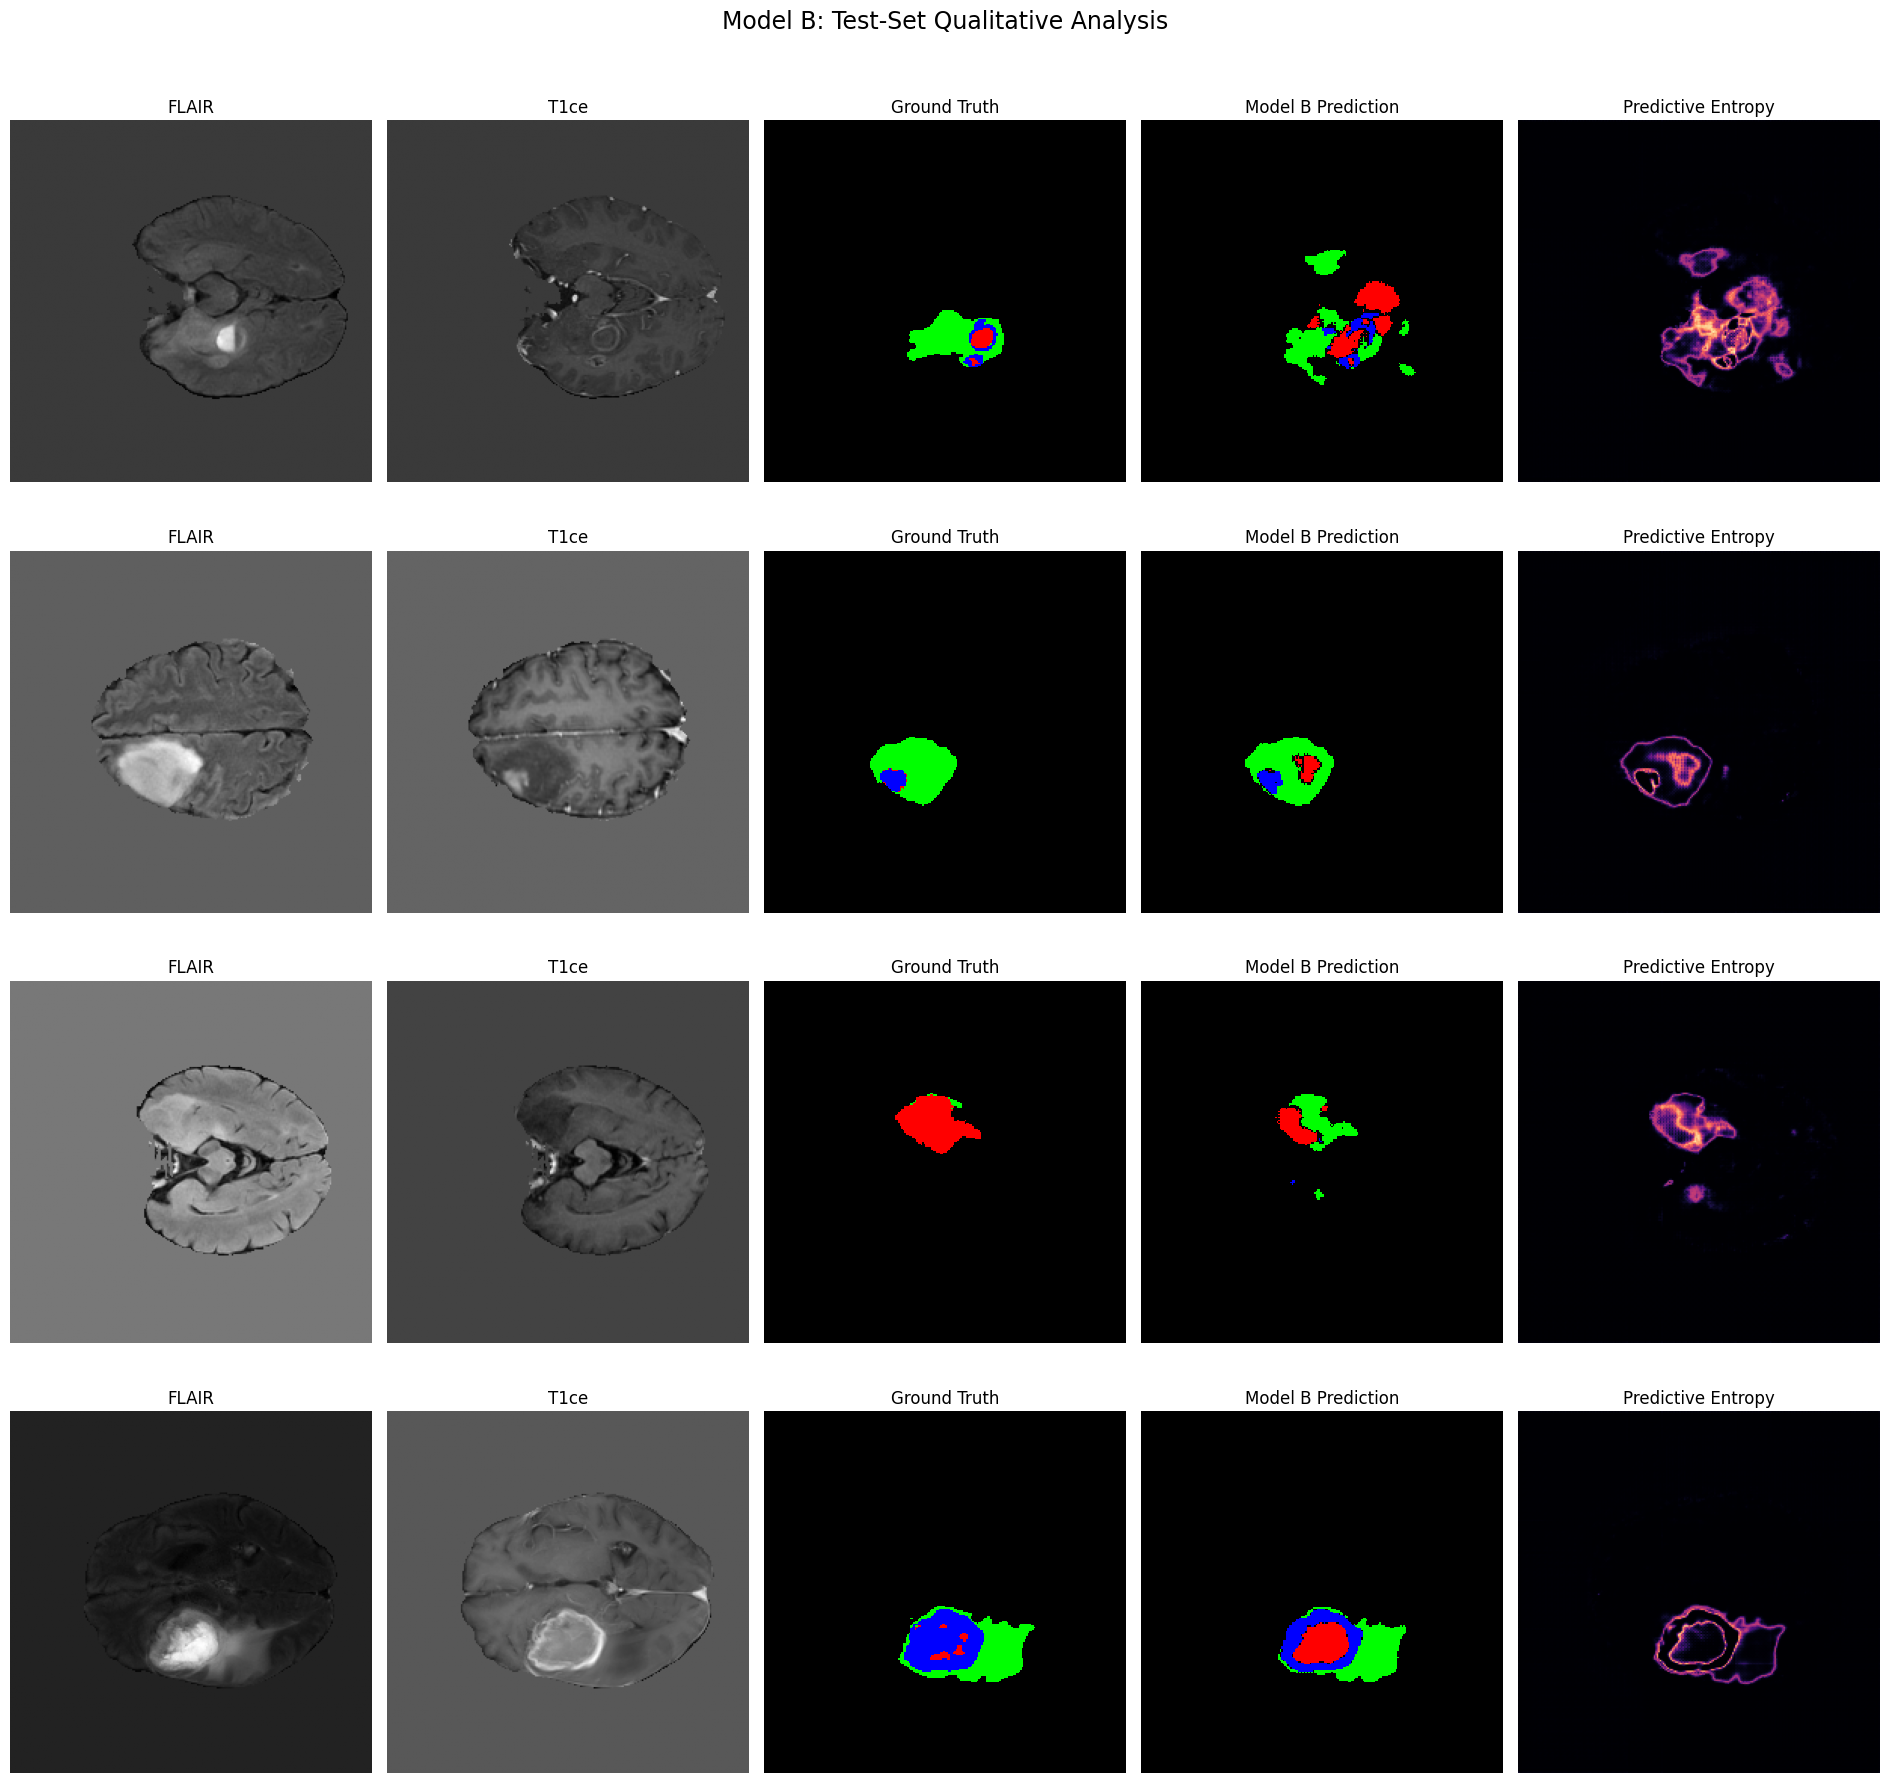

Figure saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/figures/failure_analysis/test_failure_analysis.png


In [19]:

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR, "data/preprocessed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR, "results/test_evaluation"
)

PREDICTION_DIR = os.path.join(RESULTS_DIR, "predictions")
UNCERTAINTY_DIR = os.path.join(RESULTS_DIR, "uncertainty_maps")

FIGURE_DIR = os.path.join(
    PROJECT_DIR, "results/figures/failure_analysis"
)
os.makedirs(FIGURE_DIR, exist_ok=True)

PATIENTS = [
    "BraTS2021_01556",
    "BraTS2021_01663",
    "BraTS2021_01509",
    "BraTS2021_00787"
]

# Background, necrotic/non-enhancing, oedema, enhancing
seg_cmap = ListedColormap([
    "black", "red", "lime", "blue"
])

fig, axes = plt.subplots(
    len(PATIENTS), 5,
    figsize=(19, 4.5 * len(PATIENTS))
)

for row, patient_id in enumerate(PATIENTS):

    image = np.load(
        os.path.join(PREPROCESS_DIR, f"{patient_id}_image.npy")
    ).astype(np.float32)

    label = np.load(
        os.path.join(PREPROCESS_DIR, f"{patient_id}_label.npy")
    )

    prediction = np.load(
        os.path.join(PREDICTION_DIR, f"{patient_id}_prediction.npy")
    )

    entropy = np.load(
        os.path.join(UNCERTAINTY_DIR, f"{patient_id}_entropy.npy")
    ).astype(np.float32)

    # Select axial slice with the largest ground-truth WT area
    tumour_area = (label > 0).sum(axis=(0, 1))
    z = int(np.argmax(tumour_area))

    # Input channel order: T1, T1ce, T2, FLAIR
    axes[row, 0].imshow(image[3, :, :, z], cmap="gray")
    axes[row, 0].set_title("FLAIR")

    axes[row, 1].imshow(image[1, :, :, z], cmap="gray")
    axes[row, 1].set_title("T1ce")

    axes[row, 2].imshow(
        label[:, :, z],
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )
    axes[row, 2].set_title("Ground Truth")

    axes[row, 3].imshow(
        prediction[:, :, z],
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )
    axes[row, 3].set_title("Model B Prediction")

    im = axes[row, 4].imshow(
        entropy[:, :, z],
        cmap="magma",
        vmin=0,
        vmax=np.log(4)
    )
    axes[row, 4].set_title("Predictive Entropy")

    for col in range(5):
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"{patient_id}\nSlice {z}",
        fontsize=10
    )

fig.suptitle(
    "Model B: Test-Set Qualitative Analysis",
    fontsize=17,
    y=1.01
)

fig.tight_layout()

figure_path = os.path.join(
    FIGURE_DIR,
    "test_failure_analysis.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)


In [20]:

# ============================================================
# ARM E: 50% OVERLAP + 8-FLIP TEST-TIME AUGMENTATION
# VALIDATION RUN: 8 PATIENTS
# ============================================================

import os
import time
import itertools
import numpy as np
import pandas as pd
import torch

from monai.networks.nets import UNet
from monai.inferers import SlidingWindowInferer
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR,
    "checkpoints/model_b/model_b_best.pth"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "manifests/patient_manifest.csv"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR,
    "data/preprocessed"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "results/arm_e_validation"
)

PRED_DIR = os.path.join(OUTPUT_DIR, "predictions")
UNCERTAINTY_DIR = os.path.join(OUTPUT_DIR, "uncertainty_maps")
PROB_DIR = os.path.join(OUTPUT_DIR, "probabilities")

for directory in [OUTPUT_DIR, PRED_DIR, UNCERTAINTY_DIR, PROB_DIR]:
    os.makedirs(directory, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROI_SIZE = (96, 96, 96)
OVERLAP = 0.50
SW_BATCH_SIZE = 1

print("=" * 65)
print("ARM E — VALIDATION INFERENCE")
print("=" * 65)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("ROI size:", ROI_SIZE)
print("Sliding-window overlap:", OVERLAP)
print("TTA transformations: 8")

assert os.path.exists(CHECKPOINT_PATH), (
    f"Model B checkpoint not found: {CHECKPOINT_PATH}"
)

# ------------------------------------------------------------
# 2. LOAD MODEL B
# ------------------------------------------------------------

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="INSTANCE",
    act=("LEAKYRELU", {"negative_slope": 0.01})
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nModel B checkpoint loaded.")
print("Checkpoint epoch:", checkpoint.get("epoch", "Unknown"))

del checkpoint

# ------------------------------------------------------------
# 3. SLIDING WINDOW INFERER
# ------------------------------------------------------------

inferer = SlidingWindowInferer(
    roi_size=ROI_SIZE,
    sw_batch_size=SW_BATCH_SIZE,
    overlap=OVERLAP,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)

# ------------------------------------------------------------
# 4. METRIC AND UNCERTAINTY FUNCTIONS
# ------------------------------------------------------------

def calculate_dice(pred, target, epsilon=1e-7):
    pred = pred.bool()
    target = target.bool()

    intersection = torch.logical_and(pred, target).sum().item()
    denominator = pred.sum().item() + target.sum().item()

    if denominator == 0:
        return 1.0

    return (2.0 * intersection + epsilon) / (
        denominator + epsilon
    )


def binary_entropy(probability, epsilon=1e-7):
    p = np.clip(probability, epsilon, 1.0 - epsilon)

    return -(
        p * np.log(p) +
        (1.0 - p) * np.log(1.0 - p)
    )


# ------------------------------------------------------------
# 5. EIGHT-FLIP TTA INFERENCE
# ------------------------------------------------------------

# All combinations of flipping spatial dimensions:
# (none), X, Y, Z, XY, XZ, YZ, XYZ

flip_combinations = list(
    itertools.product([False, True], repeat=3)
)

assert len(flip_combinations) == 8

def run_arm_e_inference(image_tensor):

    probability_sum = None

    with torch.inference_mode():

        for flip_combination in flip_combinations:

            flip_dims = [
                axis + 2
                for axis, should_flip in enumerate(flip_combination)
                if should_flip
            ]

            # Apply spatial transformation
            if flip_dims:
                transformed_image = torch.flip(
                    image_tensor,
                    dims=flip_dims
                )
            else:
                transformed_image = image_tensor

            # Sliding-window prediction
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                logits = inferer(
                    transformed_image,
                    model
                )

            # Convert logits into probabilities in FP32
            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            # Invert the spatial transformation
            if flip_dims:
                probabilities = torch.flip(
                    probabilities,
                    dims=flip_dims
                )

            probabilities = probabilities.cpu().float()

            if probability_sum is None:
                probability_sum = probabilities.clone()
            else:
                probability_sum += probabilities

            del transformed_image, logits, probabilities

    # Average the eight aligned probability predictions
    mean_probabilities = probability_sum / len(flip_combinations)

    return mean_probabilities


# ------------------------------------------------------------
# 6. LOAD VALIDATION PATIENTS
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)

val_manifest = manifest[
    manifest["split"].astype(str).str.lower() == "validation"
].copy()

if len(val_manifest) == 0:
    val_manifest = manifest[
        manifest["split"].astype(str).str.lower() == "val"
    ].copy()

val_patients = val_manifest["patient_id"].tolist()

print("\nValidation patients:", len(val_patients))
print(val_patients)

# ------------------------------------------------------------
# 7. RUN ARM E ON VALIDATION PATIENTS
# ------------------------------------------------------------

patient_results = []

overall_start = time.time()

for index, patient_id in enumerate(
    tqdm(val_patients, desc="Arm E validation")
):

    patient_start = time.time()

    image_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_label.npy"
    )

    assert os.path.exists(image_path), image_path
    assert os.path.exists(label_path), label_path

    image = np.load(image_path).astype(np.float32)
    label = np.load(label_path).astype(np.uint8)

    # [C, H, W, D] -> [1, C, H, W, D]
    image_tensor = torch.from_numpy(image).unsqueeze(0)

    # Eight-flip TTA + 50% overlapping inference
    mean_probabilities = run_arm_e_inference(image_tensor)

    # Remove batch dimension: [4, H, W, D]
    probabilities = mean_probabilities[0].numpy()

    # Multiclass prediction
    prediction = np.argmax(
        probabilities,
        axis=0
    ).astype(np.uint8)

    # Binary region probabilities
    # WT: classes 1, 2, 3
    # TC: classes 1, 3
    p_wt = probabilities[1:4].sum(axis=0)
    p_tc = probabilities[1] + probabilities[3]

    # Ground-truth and predicted regions
    pred_tensor = torch.from_numpy(prediction)
    label_tensor = torch.from_numpy(label)

    pred_wt = pred_tensor > 0
    true_wt = label_tensor > 0

    pred_tc = (pred_tensor == 1) | (pred_tensor == 3)
    true_tc = (label_tensor == 1) | (label_tensor == 3)

    wt_dice = calculate_dice(pred_wt, true_wt)
    tc_dice = calculate_dice(pred_tc, true_tc)

    mean_dice = (wt_dice + tc_dice) / 2.0

    # Binary predictive entropy
    entropy_wt = binary_entropy(p_wt)
    entropy_tc = binary_entropy(p_tc)

    # Save segmentation
    np.save(
        os.path.join(PRED_DIR, f"{patient_id}_prediction.npy"),
        prediction
    )

    # Save probability maps in float16 to conserve storage
    np.savez_compressed(
        os.path.join(PROB_DIR, f"{patient_id}_probabilities.npz"),
        p_wt=p_wt.astype(np.float16),
        p_tc=p_tc.astype(np.float16)
    )

    # Save uncertainty maps
    np.savez_compressed(
        os.path.join(
            UNCERTAINTY_DIR,
            f"{patient_id}_uncertainty.npz"
        ),
        entropy_wt=entropy_wt.astype(np.float16),
        entropy_tc=entropy_tc.astype(np.float16)
    )

    elapsed = time.time() - patient_start

    patient_results.append({
        "patient_id": patient_id,
        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "Mean_Dice": mean_dice,
        "mean_WT_entropy": float(entropy_wt.mean()),
        "mean_TC_entropy": float(entropy_tc.mean()),
        "inference_time_seconds": elapsed
    })

    print(
        f"\n[{index + 1}/{len(val_patients)}] {patient_id}"
        f"\nWT: {wt_dice:.4f} | TC: {tc_dice:.4f}"
        f" | Mean: {mean_dice:.4f}"
        f"\nTime: {elapsed:.1f} sec"
    )

    del image, image_tensor, label
    del mean_probabilities, probabilities, prediction
    del p_wt, p_tc, entropy_wt, entropy_tc
    del pred_tensor, label_tensor

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(patient_results)

results_path = os.path.join(
    OUTPUT_DIR,
    "arm_e_validation_patient_results.csv"
)

results_df.to_csv(results_path, index=False)

summary_df = pd.DataFrame([{
    "Model": "Model B - Arm E",
    "Number_of_patients": len(results_df),
    "WT_Dice": results_df["WT_Dice"].mean(),
    "TC_Dice": results_df["TC_Dice"].mean(),
    "Mean_Dice": results_df["Mean_Dice"].mean(),
    "WT_Dice_Std": results_df["WT_Dice"].std(),
    "TC_Dice_Std": results_df["TC_Dice"].std(),
    "Mean_Dice_Std": results_df["Mean_Dice"].std(),
    "Mean_inference_time_seconds":
        results_df["inference_time_seconds"].mean()
}])

summary_path = os.path.join(
    OUTPUT_DIR,
    "arm_e_validation_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ARM E VALIDATION COMPLETE")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nPatient-wise results:")
print(results_df.to_string(index=False))

print("\nTotal elapsed time: {:.2f} minutes".format(
    (time.time() - overall_start) / 60
))

print("\nSaved outputs:")
print("Predictions:", PRED_DIR)
print("Probabilities:", PROB_DIR)
print("Uncertainty maps:", UNCERTAINTY_DIR)
print("Patient results:", results_path)
print("Summary:", summary_path)

print("\nNext: verify Arm E outputs and compare with Arm D.")


ARM E — VALIDATION INFERENCE
Device: cuda
GPU: Tesla T4
ROI size: (96, 96, 96)
Sliding-window overlap: 0.5
TTA transformations: 8

Model B checkpoint loaded.
Checkpoint epoch: 50

Validation patients: 8
['BraTS2021_00131', 'BraTS2021_00658', 'BraTS2021_01008', 'BraTS2021_00233', 'BraTS2021_00292', 'BraTS2021_01344', 'BraTS2021_01163', 'BraTS2021_00478']


Arm E validation:   0%|          | 0/8 [00:00<?, ?it/s]


[1/8] BraTS2021_00131
WT: 0.9351 | TC: 0.8869 | Mean: 0.9110
Time: 13.4 sec

[2/8] BraTS2021_00658
WT: 0.7809 | TC: 0.8528 | Mean: 0.8169
Time: 13.4 sec

[3/8] BraTS2021_01008
WT: 0.8899 | TC: 0.8832 | Mean: 0.8866
Time: 13.2 sec

[4/8] BraTS2021_00233
WT: 0.9512 | TC: 0.9258 | Mean: 0.9385
Time: 13.5 sec

[5/8] BraTS2021_00292
WT: 0.6774 | TC: 0.6584 | Mean: 0.6679
Time: 13.4 sec

[6/8] BraTS2021_01344
WT: 0.8897 | TC: 0.8412 | Mean: 0.8654
Time: 13.5 sec

[7/8] BraTS2021_01163
WT: 0.8379 | TC: 0.7861 | Mean: 0.8120
Time: 13.4 sec

[8/8] BraTS2021_00478
WT: 0.9017 | TC: 0.9235 | Mean: 0.9126
Time: 13.6 sec

ARM E VALIDATION COMPLETE
          Model  Number_of_patients  WT_Dice  TC_Dice  Mean_Dice  WT_Dice_Std  TC_Dice_Std  Mean_Dice_Std  Mean_inference_time_seconds
Model B - Arm E                   8 0.857979 0.844751   0.851365     0.090669     0.088034       0.086793                    13.423211

Patient-wise results:
     patient_id  WT_Dice  TC_Dice  Mean_Dice  mean_WT_entropy  m

In [22]:
OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "results/arm_e_test"
)

In [25]:

# ============================================================
# ARM E: FINAL HELD-OUT TEST EVALUATION
# 50% SLIDING WINDOW OVERLAP + 8-FLIP TTA
# MODEL B — EPOCH 50
# ============================================================

import os
import time
import itertools
import gc
import numpy as np
import pandas as pd
import torch

from monai.networks.nets import UNet
from monai.inferers import SlidingWindowInferer
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR,
    "checkpoints/model_b/model_b_best.pth"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "manifests/patient_manifest.csv"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR,
    "data/preprocessed"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "results/arm_e_test"
)

PRED_DIR = os.path.join(OUTPUT_DIR, "predictions")
UNCERTAINTY_DIR = os.path.join(OUTPUT_DIR, "uncertainty_maps")
PROB_DIR = os.path.join(OUTPUT_DIR, "probabilities")

for directory in [
    OUTPUT_DIR,
    PRED_DIR,
    UNCERTAINTY_DIR,
    PROB_DIR
]:
    os.makedirs(directory, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ROI_SIZE = (96, 96, 96)
OVERLAP = 0.50
SW_BATCH_SIZE = 1

print("=" * 70)
print("ARM E — FINAL HELD-OUT TEST EVALUATION")
print("=" * 70)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("ROI size:", ROI_SIZE)
print("Overlap:", OVERLAP)
print("TTA transformations: 8")

assert os.path.exists(CHECKPOINT_PATH), (
    "Model B checkpoint not found: " + CHECKPOINT_PATH
)

assert os.path.exists(MANIFEST_PATH), (
    "Patient manifest not found: " + MANIFEST_PATH
)

# ------------------------------------------------------------
# 2. LOAD MODEL B CHECKPOINT
# ------------------------------------------------------------

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="INSTANCE",
    act=("LEAKYRELU", {"negative_slope": 0.01})
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nModel B checkpoint loaded successfully.")
print("Selected checkpoint epoch:", checkpoint.get("epoch", "Unknown"))

del checkpoint
gc.collect()

# ------------------------------------------------------------
# 3. SLIDING WINDOW INFERER
# ------------------------------------------------------------

inferer = SlidingWindowInferer(
    roi_size=ROI_SIZE,
    sw_batch_size=SW_BATCH_SIZE,
    overlap=OVERLAP,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)

# ------------------------------------------------------------
# 4. METRIC AND UNCERTAINTY FUNCTIONS
# ------------------------------------------------------------

def calculate_dice(pred, target, epsilon=1e-7):

    pred = pred.bool()
    target = target.bool()

    intersection = torch.logical_and(
        pred, target
    ).sum().item()

    denominator = (
        pred.sum().item() +
        target.sum().item()
    )

    if denominator == 0:
        return 1.0

    return (
        2.0 * intersection + epsilon
    ) / (
        denominator + epsilon
    )


def binary_entropy(probability, epsilon=1e-7):

    p = np.clip(
        probability,
        epsilon,
        1.0 - epsilon
    )

    return -(
        p * np.log(p) +
        (1.0 - p) * np.log(1.0 - p)
    )


# ------------------------------------------------------------
# 5. EIGHT-FLIP TTA
# ------------------------------------------------------------

flip_combinations = list(
    itertools.product(
        [False, True],
        repeat=3
    )
)

assert len(flip_combinations) == 8


def run_arm_e_inference(image_tensor):

    probability_sum = None

    with torch.inference_mode():

        for flip_combination in flip_combinations:

            flip_dims = [
                axis + 2
                for axis, should_flip
                in enumerate(flip_combination)
                if should_flip
            ]

            # Apply spatial flip
            if flip_dims:

                transformed_image = torch.flip(
                    image_tensor,
                    dims=flip_dims
                )

            else:

                transformed_image = image_tensor

            # Sliding-window inference
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):

                logits = inferer(
                    transformed_image,
                    model
                )

            # Convert logits to FP32 probabilities
            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            # Reverse the spatial transformation
            if flip_dims:

                probabilities = torch.flip(
                    probabilities,
                    dims=flip_dims
                )

            probabilities = probabilities.cpu().float()

            # Accumulate aligned probability maps
            if probability_sum is None:

                probability_sum = probabilities.clone()

            else:

                probability_sum += probabilities

            del transformed_image
            del logits
            del probabilities

    # Average eight predictions
    mean_probabilities = (
        probability_sum / len(flip_combinations)
    )

    return mean_probabilities


# ------------------------------------------------------------
# 6. LOAD THE 20 HELD-OUT TEST PATIENTS
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)

test_manifest = manifest[
    manifest["split"].astype(str).str.lower() == "test"
].copy()

test_patients = test_manifest[
    "patient_id"
].tolist()

assert len(test_patients) == 20, (
    f"Expected 20 test patients, found {len(test_patients)}"
)

print("\nHeld-out test patients:", len(test_patients))
print(test_patients)

# Verify all preprocessed files before starting
for patient_id in test_patients:

    image_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_label.npy"
    )

    assert os.path.exists(image_path), (
        f"Missing image: {image_path}"
    )

    assert os.path.exists(label_path), (
        f"Missing label: {label_path}"
    )

print("\nAll 20 preprocessed test patients verified.")

# ------------------------------------------------------------
# 7. RUN ARM E ON ALL TEST PATIENTS
# ------------------------------------------------------------

patient_results = []

overall_start = time.time()

for index, patient_id in enumerate(
    tqdm(test_patients, desc="Arm E test evaluation")
):

    patient_start = time.time()

    image_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_image.npy"
    )

    label_path = os.path.join(
        PREPROCESS_DIR,
        f"{patient_id}_label.npy"
    )

    image = np.load(image_path).astype(np.float32)
    label = np.load(label_path).astype(np.uint8)

    # [C, H, W, D] -> [1, C, H, W, D]
    image_tensor = torch.from_numpy(
        image
    ).unsqueeze(0)

    # Arm E inference
    mean_probabilities = run_arm_e_inference(
        image_tensor
    )

    # [1, 4, H, W, D] -> [4, H, W, D]
    probabilities = mean_probabilities[0].numpy()

    # Multiclass segmentation
    prediction = np.argmax(
        probabilities,
        axis=0
    ).astype(np.uint8)

    # WT probability: classes 1, 2, 3
    p_wt = probabilities[1:4].sum(axis=0)

    # TC probability: classes 1, 3
    p_tc = probabilities[1] + probabilities[3]

    # Ground truth and prediction tensors
    pred_tensor = torch.from_numpy(prediction)
    label_tensor = torch.from_numpy(label)

    # Whole Tumour
    pred_wt = pred_tensor > 0
    true_wt = label_tensor > 0

    # Tumour Core
    pred_tc = (
        (pred_tensor == 1) |
        (pred_tensor == 3)
    )

    true_tc = (
        (label_tensor == 1) |
        (label_tensor == 3)
    )

    # Dice metrics
    wt_dice = calculate_dice(
        pred_wt,
        true_wt
    )

    tc_dice = calculate_dice(
        pred_tc,
        true_tc
    )

    mean_dice = (
        wt_dice + tc_dice
    ) / 2.0

    # Binary predictive entropy
    entropy_wt = binary_entropy(p_wt)
    entropy_tc = binary_entropy(p_tc)

    # Save segmentation prediction
    np.save(
        os.path.join(
            PRED_DIR,
            f"{patient_id}_prediction.npy"
        ),
        prediction
    )

    # Save probability maps
    np.savez_compressed(
        os.path.join(
            PROB_DIR,
            f"{patient_id}_probabilities.npz"
        ),
        p_wt=p_wt.astype(np.float16),
        p_tc=p_tc.astype(np.float16)
    )

    # Save uncertainty maps
    np.savez_compressed(
        os.path.join(
            UNCERTAINTY_DIR,
            f"{patient_id}_uncertainty.npz"
        ),
        entropy_wt=entropy_wt.astype(np.float16),
        entropy_tc=entropy_tc.astype(np.float16)
    )

    elapsed = time.time() - patient_start

    patient_results.append({

        "patient_id": patient_id,

        "WT_Dice": wt_dice,
        "TC_Dice": tc_dice,
        "Mean_Dice": mean_dice,

        "mean_WT_entropy": float(
            entropy_wt.mean()
        ),

        "mean_TC_entropy": float(
            entropy_tc.mean()
        ),

        "inference_time_seconds": elapsed
    })

    print(
        f"\n[{index + 1}/20] {patient_id}"
        f"\nWT: {wt_dice:.4f}"
        f" | TC: {tc_dice:.4f}"
        f" | Mean: {mean_dice:.4f}"
        f"\nTime: {elapsed:.1f} seconds"
    )

    # Release memory
    del image
    del label
    del image_tensor
    del mean_probabilities
    del probabilities
    del prediction
    del p_wt
    del p_tc
    del entropy_wt
    del entropy_tc
    del pred_tensor
    del label_tensor

    del pred_wt
    del true_wt
    del pred_tc
    del true_tc

    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. SAVE PATIENT-WISE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(patient_results)

results_path = os.path.join(
    OUTPUT_DIR,
    "arm_e_test_patient_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------------------
# 9. SAVE OVERALL TEST SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame([{

    "Model": "Model B - Arm E",

    "Number_of_patients": len(results_df),

    "WT_Dice": results_df["WT_Dice"].mean(),

    "TC_Dice": results_df["TC_Dice"].mean(),

    "Mean_Dice": results_df["Mean_Dice"].mean(),

    "WT_Dice_Std": results_df["WT_Dice"].std(),

    "TC_Dice_Std": results_df["TC_Dice"].std(),

    "Mean_Dice_Std": results_df["Mean_Dice"].std(),

    "Mean_inference_time_seconds":
        results_df["inference_time_seconds"].mean()

}])

summary_path = os.path.join(
    OUTPUT_DIR,
    "arm_e_test_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

total_time = (
    time.time() - overall_start
) / 60

print("\n" + "=" * 75)
print("FINAL HELD-OUT TEST RESULTS — ARM E")
print("=" * 75)

print(summary_df.to_string(index=False))

print("\n" + "=" * 75)
print("PATIENT-WISE TEST RESULTS")
print("=" * 75)

print(
    results_df[
        [
            "patient_id",
            "WT_Dice",
            "TC_Dice",
            "Mean_Dice"
        ]
    ].to_string(index=False)
)

print("\nTotal inference time: {:.2f} minutes".format(
    total_time
))

print("\n" + "=" * 75)
print("ARM E TEST EVALUATION COMPLETE")
print("=" * 75)

print("\nSaved outputs:")
print("Predictions:", PRED_DIR)
print("Probabilities:", PROB_DIR)
print("Uncertainty maps:", UNCERTAINTY_DIR)
print("Patient results:", results_path)
print("Summary:", summary_path)

print("\nAll 20 test patients processed.")
print("Model B checkpoint was not modified.")


ARM E — FINAL HELD-OUT TEST EVALUATION
Device: cuda
GPU: Tesla T4
ROI size: (96, 96, 96)
Overlap: 0.5
TTA transformations: 8

Model B checkpoint loaded successfully.
Selected checkpoint epoch: 50

Held-out test patients: 20
['BraTS2021_01174', 'BraTS2021_01143', 'BraTS2021_00606', 'BraTS2021_00787', 'BraTS2021_00207', 'BraTS2021_01663', 'BraTS2021_00504', 'BraTS2021_01509', 'BraTS2021_00479', 'BraTS2021_01362', 'BraTS2021_01193', 'BraTS2021_00795', 'BraTS2021_01556', 'BraTS2021_00631', 'BraTS2021_01080', 'BraTS2021_00156', 'BraTS2021_00663', 'BraTS2021_01062', 'BraTS2021_01237', 'BraTS2021_00789']

All 20 preprocessed test patients verified.


Arm E test evaluation:   0%|          | 0/20 [00:00<?, ?it/s]


[1/20] BraTS2021_01174
WT: 0.8395 | TC: 0.8153 | Mean: 0.8274
Time: 13.5 seconds

[2/20] BraTS2021_01143
WT: 0.8876 | TC: 0.8079 | Mean: 0.8477
Time: 13.3 seconds

[3/20] BraTS2021_00606
WT: 0.8386 | TC: 0.8309 | Mean: 0.8347
Time: 13.4 seconds

[4/20] BraTS2021_00787
WT: 0.9568 | TC: 0.9695 | Mean: 0.9632
Time: 13.5 seconds

[5/20] BraTS2021_00207
WT: 0.8508 | TC: 0.5759 | Mean: 0.7134
Time: 13.4 seconds

[6/20] BraTS2021_01663
WT: 0.8089 | TC: 0.2377 | Mean: 0.5233
Time: 13.6 seconds

[7/20] BraTS2021_00504
WT: 0.9507 | TC: 0.8058 | Mean: 0.8782
Time: 13.6 seconds

[8/20] BraTS2021_01509
WT: 0.8262 | TC: 0.6097 | Mean: 0.7180
Time: 13.6 seconds

[9/20] BraTS2021_00479
WT: 0.8420 | TC: 0.9375 | Mean: 0.8898
Time: 13.7 seconds

[10/20] BraTS2021_01362
WT: 0.9502 | TC: 0.9287 | Mean: 0.9395
Time: 13.6 seconds

[11/20] BraTS2021_01193
WT: 0.8195 | TC: 0.7410 | Mean: 0.7803
Time: 13.6 seconds

[12/20] BraTS2021_00795
WT: 0.8014 | TC: 0.8649 | Mean: 0.8332
Time: 13.6 seconds

[13/20] BraT

In [26]:
# ============================================================
# ARM A — FINAL HELD-OUT TEST EVALUATION
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from monai.networks.nets import UNet
from monai.inferers import SlidingWindowInferer

# -------------------- CONFIGURATION --------------------

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "checkpoints/model_a/baseline_best.pth"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR, "data/preprocessed"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results/final_comparison"
)

PREDICTION_DIR = os.path.join(
    OUTPUT_DIR, "arm_a_predictions"
)

os.makedirs(PREDICTION_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROI_SIZE = (96, 96, 96)
OVERLAP = 0.25

print("=" * 65)
print("ARM A — FINAL HELD-OUT TEST EVALUATION")
print("=" * 65)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- LOAD TEST MANIFEST --------------------

manifest = pd.read_csv(MANIFEST_PATH)
test_manifest = manifest[manifest["split"] == "test"].copy()

test_ids = test_manifest["patient_id"].tolist()

print("\nHeld-out test patients:", len(test_ids))

assert len(test_ids) == 20, (
    f"Expected 20 test patients, found {len(test_ids)}"
)

# Verify that the preprocessed test data exists
for patient_id in test_ids:
    image_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_image.npy"
    )
    label_path = os.path.join(
        PREPROCESS_DIR, f"{patient_id}_label.npy"
    )

    assert os.path.exists(image_path), image_path
    assert os.path.exists(label_path), label_path

print("All 20 preprocessed test patients verified.")

# -------------------- BUILD MODEL A --------------------

model_a = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="BATCH",
    act="RELU"
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_a.load_state_dict(checkpoint["model_state_dict"])
model_a.eval()

print("\nModel A checkpoint loaded successfully.")
print("Selected checkpoint epoch:", checkpoint.get("epoch", "Unknown"))

# -------------------- SLIDING WINDOW INFERENCE --------------------

inferer_a = SlidingWindowInferer(
    roi_size=ROI_SIZE,
    sw_batch_size=1,
    overlap=OVERLAP,
    mode="gaussian",
    sw_device=DEVICE,
    device="cpu"
)

# -------------------- DICE FUNCTIONS --------------------

def calculate_dice(prediction, target, region):
    pred_region = region(prediction)
    target_region = region(target)

    intersection = np.logical_and(
        pred_region, target_region
    ).sum()

    denominator = pred_region.sum() + target_region.sum()

    if denominator == 0:
        return 1.0

    return float(2.0 * intersection / denominator)


def whole_tumour(mask):
    return mask > 0


def tumour_core(mask):
    return np.logical_or(mask == 1, mask == 3)


# -------------------- EVALUATE ALL TEST PATIENTS --------------------

patient_results = []
total_start = time.time()

with torch.inference_mode():

    for index, patient_id in enumerate(
        tqdm(test_ids, desc="Arm A test evaluation"), start=1
    ):

        patient_start = time.time()

        image_path = os.path.join(
            PREPROCESS_DIR, f"{patient_id}_image.npy"
        )

        label_path = os.path.join(
            PREPROCESS_DIR, f"{patient_id}_label.npy"
        )

        image_np = np.load(image_path).astype(np.float32)
        label_np = np.load(label_path).astype(np.uint8)

        # Image: [1, 4, D, H, W]
        image_tensor = torch.from_numpy(
            image_np
        ).unsqueeze(0).to(DEVICE)

        # Full-volume sliding-window prediction
        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            logits = inferer_a(image_tensor, model_a)

        prediction_np = (
            torch.argmax(logits, dim=1)
            .squeeze(0)
            .numpy()
            .astype(np.uint8)
        )

        # Calculate region-wise Dice
        wt_dice = calculate_dice(
            prediction_np, label_np, whole_tumour
        )

        tc_dice = calculate_dice(
            prediction_np, label_np, tumour_core
        )

        mean_dice = (wt_dice + tc_dice) / 2.0

        # Save prediction for later comparison and visualisation
        np.save(
            os.path.join(
                PREDICTION_DIR, f"{patient_id}_prediction.npy"
            ),
            prediction_np
        )

        elapsed = time.time() - patient_start

        patient_results.append({
            "patient_id": patient_id,
            "WT_Dice": wt_dice,
            "TC_Dice": tc_dice,
            "Mean_Dice": mean_dice,
            "inference_time_seconds": elapsed
        })

        print(
            f"\n[{index}/20] {patient_id}"
            f"\nWT: {wt_dice:.4f} | "
            f"TC: {tc_dice:.4f} | "
            f"Mean: {mean_dice:.4f}"
            f"\nTime: {elapsed:.2f} seconds"
        )

        del image_tensor, logits, prediction_np
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

# -------------------- SUMMARY --------------------

results_df = pd.DataFrame(patient_results)

summary_df = pd.DataFrame([{
    "Model": "Model A - 3D U-Net",
    "Number_of_patients": len(results_df),
    "WT_Dice": results_df["WT_Dice"].mean(),
    "TC_Dice": results_df["TC_Dice"].mean(),
    "Mean_Dice": results_df["Mean_Dice"].mean(),
    "WT_Dice_Std": results_df["WT_Dice"].std(ddof=0),
    "TC_Dice_Std": results_df["TC_Dice"].std(ddof=0),
    "Mean_Dice_Std": results_df["Mean_Dice"].std(ddof=0),
    "Mean_inference_time_seconds":
        results_df["inference_time_seconds"].mean()
}])

# -------------------- SAVE RESULTS --------------------

patient_csv = os.path.join(
    OUTPUT_DIR, "arm_a_test_patient_results.csv"
)

summary_csv = os.path.join(
    OUTPUT_DIR, "arm_a_test_summary.csv"
)

results_df.to_csv(patient_csv, index=False)
summary_df.to_csv(summary_csv, index=False)

total_elapsed = time.time() - total_start

print("\n" + "=" * 75)
print("FINAL HELD-OUT TEST RESULTS — MODEL A")
print("=" * 75)

print(summary_df.to_string(index=False))

print("\nPATIENT-WISE RESULTS")
print(results_df.to_string(index=False))

print("\nTotal evaluation time:", round(total_elapsed / 60, 2), "minutes")

print("\nSaved outputs:")
print("Predictions:", PREDICTION_DIR)
print("Patient results:", patient_csv)
print("Summary:", summary_csv)

print("\nMODEL A TEST EVALUATION COMPLETE")


ARM A — FINAL HELD-OUT TEST EVALUATION
Device: cuda
GPU: Tesla T4

Held-out test patients: 20
All 20 preprocessed test patients verified.

Model A checkpoint loaded successfully.
Selected checkpoint epoch: 47


Arm A test evaluation:   0%|          | 0/20 [00:00<?, ?it/s]


[1/20] BraTS2021_01174
WT: 0.8274 | TC: 0.7870 | Mean: 0.8072
Time: 2.48 seconds

[2/20] BraTS2021_01143
WT: 0.9011 | TC: 0.8081 | Mean: 0.8546
Time: 2.44 seconds

[3/20] BraTS2021_00606
WT: 0.8215 | TC: 0.6048 | Mean: 0.7132
Time: 2.54 seconds

[4/20] BraTS2021_00787
WT: 0.9423 | TC: 0.9431 | Mean: 0.9427
Time: 2.50 seconds

[5/20] BraTS2021_00207
WT: 0.8655 | TC: 0.3545 | Mean: 0.6100
Time: 2.45 seconds

[6/20] BraTS2021_01663
WT: 0.9071 | TC: 0.4112 | Mean: 0.6591
Time: 2.52 seconds

[7/20] BraTS2021_00504
WT: 0.9467 | TC: 0.7790 | Mean: 0.8628
Time: 2.48 seconds

[8/20] BraTS2021_01509
WT: 0.8403 | TC: 0.0041 | Mean: 0.4222
Time: 2.46 seconds

[9/20] BraTS2021_00479
WT: 0.8875 | TC: 0.6629 | Mean: 0.7752
Time: 2.49 seconds

[10/20] BraTS2021_01362
WT: 0.9232 | TC: 0.8556 | Mean: 0.8894
Time: 2.41 seconds

[11/20] BraTS2021_01193
WT: 0.7189 | TC: 0.5316 | Mean: 0.6253
Time: 2.49 seconds

[12/20] BraTS2021_00795
WT: 0.9053 | TC: 0.8799 | Mean: 0.8926
Time: 2.41 seconds

[13/20] BraT

In [28]:
import os
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

# ------------------------------------------------
# SOURCE DIRECTORIES
# ------------------------------------------------

BASE_DIR = Path(
    "/kaggle/working/P29_Brain_Tumour_Segmentation/results/arm_e_test"
)

FOLDERS = {
    "predictions": BASE_DIR / "predictions",
    "probabilities": BASE_DIR / "probabilities",
    "uncertainty_maps": BASE_DIR / "uncertainty_maps"
}

# ------------------------------------------------
# VERIFY FILES
# ------------------------------------------------

print("=" * 60)
print("VERIFYING ARM E OUTPUT FILES")
print("=" * 60)

for folder_name, folder_path in FOLDERS.items():

    if not folder_path.exists():
        raise FileNotFoundError(
            f"Folder not found: {folder_path}"
        )

    files = [
        f for f in folder_path.rglob("*")
        if f.is_file()
    ]

    print(f"{folder_name}: {len(files)} files")

    if len(files) == 0:
        raise ValueError(
            f"No files found in {folder_path}"
        )

# ------------------------------------------------
# CREATE ZIP
# ------------------------------------------------

ZIP_PATH = Path(
    "/kaggle/working/Arm_E_Test_Outputs.zip"
)

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zipf:

    for folder_name, folder_path in FOLDERS.items():

        for file_path in folder_path.rglob("*"):

            if file_path.is_file():

                # Keep the three folders at the ZIP root
                relative_path = (
                    Path(folder_name) /
                    file_path.relative_to(folder_path)
                )

                zipf.write(
                    file_path,
                    arcname=str(relative_path)
                )

# ------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zipf:

    bad_file = zipf.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP verification failed: {bad_file}"
        )

    print("\nZIP contents:")
    for name in zipf.namelist()[:15]:
        print(name)

    print("..." if len(zipf.namelist()) > 15 else "")

size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 60)
print("ZIP CREATED AND VERIFIED SUCCESSFULLY")
print("=" * 60)
print("File:", ZIP_PATH)
print(f"Size: {size_mb:.2f} MB")
print("Total files:", len(zipf.namelist()) if 'zipf' in locals() else "See ZIP")

display(FileLink(str(ZIP_PATH)))


VERIFYING ARM E OUTPUT FILES
predictions: 20 files
probabilities: 20 files
uncertainty_maps: 20 files

ZIP contents:
predictions/BraTS2021_01143_prediction.npy
predictions/BraTS2021_01193_prediction.npy
predictions/BraTS2021_00631_prediction.npy
predictions/BraTS2021_01080_prediction.npy
predictions/BraTS2021_00479_prediction.npy
predictions/BraTS2021_01237_prediction.npy
predictions/BraTS2021_01362_prediction.npy
predictions/BraTS2021_00663_prediction.npy
predictions/BraTS2021_01062_prediction.npy
predictions/BraTS2021_01174_prediction.npy
predictions/BraTS2021_00156_prediction.npy
predictions/BraTS2021_01509_prediction.npy
predictions/BraTS2021_00795_prediction.npy
predictions/BraTS2021_01556_prediction.npy
predictions/BraTS2021_00207_prediction.npy
...

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/Arm_E_Test_Outputs.zip
Size: 1048.86 MB
Total files: 60


/kaggle/working/Arm_E_Test_Outputs.zip

In [29]:
# ============================================================
# FINAL COMPARISON — MODEL A vs ARM E
# Dice + HD95 + PAIRED STATISTICAL TESTING
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import nibabel as nib

from scipy.ndimage import binary_erosion, distance_transform_edt
from scipy.stats import wilcoxon

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

A_PRED_DIR = os.path.join(
    PROJECT_DIR, "results/final_comparison/arm_a_predictions"
)

E_PRED_DIR = os.path.join(
    PROJECT_DIR, "results/arm_e_test/predictions"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "manifests/patient_manifest.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results/final_comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# LOAD TEST PATIENTS
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)
test_df = manifest[manifest["split"] == "test"].copy()

assert len(test_df) == 20, "Expected 20 held-out test patients."

# ------------------------------------------------------------
# FIND PREDICTION FILES
# ------------------------------------------------------------

def find_prediction(folder, patient_id):

    matches = glob.glob(
        os.path.join(folder, "**", f"{patient_id}*.npy"),
        recursive=True
    )

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one prediction for {patient_id} "
            f"in {folder}; found {matches}"
        )

    return matches[0]


# ------------------------------------------------------------
# METRIC FUNCTIONS
# ------------------------------------------------------------

def get_regions(mask):

    wt = mask > 0
    tc = np.logical_or(mask == 1, mask == 3)

    return wt, tc


def dice_score(pred, gt):

    intersection = np.logical_and(pred, gt).sum()
    denominator = pred.sum() + gt.sum()

    if denominator == 0:
        return 1.0

    return float(2.0 * intersection / denominator)


def hd95(pred, gt, spacing):

    pred = np.asarray(pred, dtype=bool)
    gt = np.asarray(gt, dtype=bool)

    # Both empty: no boundary error
    if not pred.any() and not gt.any():
        return 0.0

    # One empty: HD95 is undefined
    if not pred.any() or not gt.any():
        return np.nan

    structure = np.ones((3, 3, 3), dtype=bool)

    pred_surface = np.logical_and(
        pred,
        np.logical_not(binary_erosion(pred, structure=structure))
    )

    gt_surface = np.logical_and(
        gt,
        np.logical_not(binary_erosion(gt, structure=structure))
    )

    distance_to_gt = distance_transform_edt(
        ~gt_surface, sampling=spacing
    )

    distance_to_pred = distance_transform_edt(
        ~pred_surface, sampling=spacing
    )

    distances_pred_to_gt = distance_to_gt[pred_surface]
    distances_gt_to_pred = distance_to_pred[gt_surface]

    all_distances = np.concatenate([
        distances_pred_to_gt,
        distances_gt_to_pred
    ])

    return float(np.percentile(all_distances, 95))


# ------------------------------------------------------------
# EVALUATE BOTH MODELS
# ------------------------------------------------------------

records = []

print("=" * 70)
print("MODEL A vs ARM E — HD95 AND DICE COMPARISON")
print("=" * 70)

for _, row in test_df.iterrows():

    patient_id = row["patient_id"]

    a_path = find_prediction(A_PRED_DIR, patient_id)
    e_path = find_prediction(E_PRED_DIR, patient_id)

    label_path = os.path.join(
        PROJECT_DIR,
        "data/preprocessed",
        f"{patient_id}_label.npy"
    )

    assert os.path.exists(label_path), label_path

    pred_a = np.load(a_path).astype(np.uint8)
    pred_e = np.load(e_path).astype(np.uint8)
    gt = np.load(label_path).astype(np.uint8)

    assert pred_a.shape == pred_e.shape == gt.shape, (
        f"Shape mismatch for {patient_id}: "
        f"A={pred_a.shape}, E={pred_e.shape}, GT={gt.shape}"
    )

    # Obtain physical voxel spacing from original segmentation header
    nii = nib.load(row["seg"])
    spacing = tuple(float(x) for x in nii.header.get_zooms()[:3])

    a_wt, a_tc = get_regions(pred_a)
    e_wt, e_tc = get_regions(pred_e)
    gt_wt, gt_tc = get_regions(gt)

    # Dice
    a_wt_dice = dice_score(a_wt, gt_wt)
    a_tc_dice = dice_score(a_tc, gt_tc)

    e_wt_dice = dice_score(e_wt, gt_wt)
    e_tc_dice = dice_score(e_tc, gt_tc)

    # HD95 in mm using original voxel spacing
    a_wt_hd95 = hd95(a_wt, gt_wt, spacing)
    a_tc_hd95 = hd95(a_tc, gt_tc, spacing)

    e_wt_hd95 = hd95(e_wt, gt_wt, spacing)
    e_tc_hd95 = hd95(e_tc, gt_tc, spacing)

    records.append({
        "patient_id": patient_id,

        "A_WT_Dice": a_wt_dice,
        "E_WT_Dice": e_wt_dice,

        "A_TC_Dice": a_tc_dice,
        "E_TC_Dice": e_tc_dice,

        "A_Mean_Dice": (a_wt_dice + a_tc_dice) / 2,
        "E_Mean_Dice": (e_wt_dice + e_tc_dice) / 2,

        "A_WT_HD95_mm": a_wt_hd95,
        "E_WT_HD95_mm": e_wt_hd95,

        "A_TC_HD95_mm": a_tc_hd95,
        "E_TC_HD95_mm": e_tc_hd95,

        "voxel_spacing_mm": str(spacing)
    })

    print(
        f"{patient_id} | "
        f"A Mean Dice: {(a_wt_dice+a_tc_dice)/2:.4f} | "
        f"E Mean Dice: {(e_wt_dice+e_tc_dice)/2:.4f}"
    )

    del pred_a, pred_e, gt

# ------------------------------------------------------------
# PATIENT-WISE TABLE
# ------------------------------------------------------------

results = pd.DataFrame(records)

results["Mean_Dice_Improvement"] = (
    results["E_Mean_Dice"] - results["A_Mean_Dice"]
)

results["WT_HD95_Change_mm"] = (
    results["E_WT_HD95_mm"] - results["A_WT_HD95_mm"]
)

results["TC_HD95_Change_mm"] = (
    results["E_TC_HD95_mm"] - results["A_TC_HD95_mm"]
)

patient_csv = os.path.join(
    OUTPUT_DIR, "model_a_vs_arm_e_patient_metrics.csv"
)

results.to_csv(patient_csv, index=False)

# ------------------------------------------------------------
# SUMMARY TABLE
# ------------------------------------------------------------

metric_pairs = [
    ("WT_Dice", "A_WT_Dice", "E_WT_Dice", "higher"),
    ("TC_Dice", "A_TC_Dice", "E_TC_Dice", "higher"),
    ("Mean_Dice", "A_Mean_Dice", "E_Mean_Dice", "higher"),
    ("WT_HD95_mm", "A_WT_HD95_mm", "E_WT_HD95_mm", "lower"),
    ("TC_HD95_mm", "A_TC_HD95_mm", "E_TC_HD95_mm", "lower")
]

summary_records = []

for metric, a_col, e_col, direction in metric_pairs:

    a_values = results[a_col].dropna()
    e_values = results[e_col].dropna()

    paired = results[[a_col, e_col]].dropna()

    if len(paired) < 2:
        p_value = np.nan
    else:
        try:
            p_value = wilcoxon(
                paired[e_col],
                paired[a_col],
                alternative="two-sided"
            ).pvalue
        except ValueError:
            p_value = 1.0

    a_mean = a_values.mean()
    e_mean = e_values.mean()

    summary_records.append({
        "Metric": metric,
        "Model_A": a_mean,
        "Arm_E": e_mean,
        "Change_E_minus_A": e_mean - a_mean,
        "Direction_of_improvement": direction,
        "Paired_patients": len(paired),
        "Wilcoxon_p_value": p_value
    })

summary = pd.DataFrame(summary_records)

summary_csv = os.path.join(
    OUTPUT_DIR, "model_a_vs_arm_e_final_summary.csv"
)

summary.to_csv(summary_csv, index=False)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL MODEL A vs ARM E COMPARISON")
print("=" * 80)

print(summary.round(5).to_string(index=False))

print("\nPatient-wise metrics saved:", patient_csv)
print("Summary saved:", summary_csv)

print("\nHD95 interpretation: LOWER IS BETTER")
print("Dice interpretation: HIGHER IS BETTER")

print("\nCOMPARISON COMPLETE")


MODEL A vs ARM E — HD95 AND DICE COMPARISON
BraTS2021_01174 | A Mean Dice: 0.8072 | E Mean Dice: 0.8274
BraTS2021_01143 | A Mean Dice: 0.8546 | E Mean Dice: 0.8477
BraTS2021_00606 | A Mean Dice: 0.7132 | E Mean Dice: 0.8347
BraTS2021_00787 | A Mean Dice: 0.9427 | E Mean Dice: 0.9632
BraTS2021_00207 | A Mean Dice: 0.6100 | E Mean Dice: 0.7134
BraTS2021_01663 | A Mean Dice: 0.6591 | E Mean Dice: 0.5233
BraTS2021_00504 | A Mean Dice: 0.8628 | E Mean Dice: 0.8782
BraTS2021_01509 | A Mean Dice: 0.4222 | E Mean Dice: 0.7180
BraTS2021_00479 | A Mean Dice: 0.7752 | E Mean Dice: 0.8898
BraTS2021_01362 | A Mean Dice: 0.8894 | E Mean Dice: 0.9395
BraTS2021_01193 | A Mean Dice: 0.6253 | E Mean Dice: 0.7803
BraTS2021_00795 | A Mean Dice: 0.8926 | E Mean Dice: 0.8332
BraTS2021_01556 | A Mean Dice: 0.2284 | E Mean Dice: 0.2637
BraTS2021_00631 | A Mean Dice: 0.6976 | E Mean Dice: 0.9477
BraTS2021_01080 | A Mean Dice: 0.7365 | E Mean Dice: 0.9231
BraTS2021_00156 | A Mean Dice: 0.8441 | E Mean Dice: 0.9

In [30]:
# ============================================================
# PAIRED BOOTSTRAP — MODEL A vs ARM E
# 95% CONFIDENCE INTERVALS, 10,000 RESAMPLES
# ============================================================

import os
import numpy as np
import pandas as pd

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

INPUT_CSV = os.path.join(
    PROJECT_DIR,
    "results/final_comparison/model_a_vs_arm_e_patient_metrics.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results/final_comparison"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT_CSV)

METRICS = {
    "WT_Dice": ("A_WT_Dice", "E_WT_Dice"),
    "TC_Dice": ("A_TC_Dice", "E_TC_Dice"),
    "Mean_Dice": ("A_Mean_Dice", "E_Mean_Dice"),
    "WT_HD95_mm": ("A_WT_HD95_mm", "E_WT_HD95_mm"),
    "TC_HD95_mm": ("A_TC_HD95_mm", "E_TC_HD95_mm")
}

N_BOOTSTRAP = 10000
SEED = 42
rng = np.random.default_rng(SEED)

records = []

print("Paired bootstrap resampling:", N_BOOTSTRAP)
print("Random seed:", SEED)

for metric, (a_col, e_col) in METRICS.items():

    paired = df[[a_col, e_col]].dropna()

    a = paired[a_col].to_numpy()
    e = paired[e_col].to_numpy()

    # Positive difference means E - A
    differences = e - a

    observed = differences.mean()

    bootstrap_means = np.empty(N_BOOTSTRAP)

    for b in range(N_BOOTSTRAP):
        indices = rng.integers(
            0, len(differences), size=len(differences)
        )
        bootstrap_means[b] = differences[indices].mean()

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    records.append({
        "Metric": metric,
        "Number_of_patients": len(differences),
        "Mean_difference_E_minus_A": observed,
        "CI_95_lower": ci_low,
        "CI_95_upper": ci_high
    })

    print(
        f"\n{metric}"
        f"\nMean difference: {observed:.5f}"
        f"\n95% CI: [{ci_low:.5f}, {ci_high:.5f}]"
    )

bootstrap_df = pd.DataFrame(records)

OUTPUT_CSV = os.path.join(
    OUTPUT_DIR, "paired_bootstrap_95CI.csv"
)

bootstrap_df.to_csv(OUTPUT_CSV, index=False)

print("\n" + "=" * 65)
print("PAIRED BOOTSTRAP COMPLETE")
print("=" * 65)
print(bootstrap_df.to_string(index=False))
print("\nSaved:", OUTPUT_CSV)


Paired bootstrap resampling: 10000
Random seed: 42

WT_Dice
Mean difference: 0.01206
95% CI: [-0.01376, 0.03891]

TC_Dice
Mean difference: 0.14315
95% CI: [0.07738, 0.21600]

Mean_Dice
Mean difference: 0.07760
95% CI: [0.03628, 0.11983]

WT_HD95_mm
Mean difference: 9.89859
95% CI: [1.19582, 20.71948]

TC_HD95_mm
Mean difference: 3.06531
95% CI: [-2.49184, 12.08434]

PAIRED BOOTSTRAP COMPLETE
    Metric  Number_of_patients  Mean_difference_E_minus_A  CI_95_lower  CI_95_upper
   WT_Dice                  20                   0.012059    -0.013764     0.038908
   TC_Dice                  20                   0.143146     0.077385     0.216002
 Mean_Dice                  20                   0.077602     0.036276     0.119828
WT_HD95_mm                  20                   9.898592     1.195825    20.719476
TC_HD95_mm                  20                   3.065307    -2.491842    12.084336

Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/final_comparison/paired_bootstrap_95CI.

In [31]:
import pandas as pd
import os

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

arm_d_path = os.path.join(
    BASE, "results/test_evaluation/test_patient_results.csv"
)

arm_e_path = os.path.join(
    BASE, "results/arm_e_test/arm_e_test_patient_results.csv"
)

arm_d = pd.read_csv(arm_d_path)
arm_e = pd.read_csv(arm_e_path)

print("ARM D")
print("Shape:", arm_d.shape)
print("Columns:", arm_d.columns.tolist())
display(arm_d.head())

print("\nARM E")
print("Shape:", arm_e.shape)
print("Columns:", arm_e.columns.tolist())
display(arm_e.head())

ARM D
Shape: (20, 4)
Columns: ['Patient', 'WT_Dice', 'TC_Dice', 'Mean_Dice']


,Patient,WT_Dice,TC_Dice,Mean_Dice
0,BraTS2021_01174,0.834328,0.813784,0.824056
1,BraTS2021_01143,0.861218,0.818039,0.839628
2,BraTS2021_00606,0.818564,0.815666,0.817115
3,BraTS2021_00787,0.947052,0.963432,0.955242
4,BraTS2021_00207,0.850560,0.586707,0.718633



ARM E
Shape: (20, 7)
Columns: ['patient_id', 'WT_Dice', 'TC_Dice', 'Mean_Dice', 'mean_WT_entropy', 'mean_TC_entropy', 'inference_time_seconds']


,patient_id,WT_Dice,TC_Dice,Mean_Dice,mean_WT_entropy,mean_TC_entropy,inference_time_seconds
0,BraTS2021_01174,0.839454,0.815309,0.827381,0.012235,0.006547,13.533111
1,BraTS2021_01143,0.887587,0.807856,0.847722,0.015083,0.007317,13.290148
2,BraTS2021_00606,0.838561,0.830881,0.834721,0.015022,0.008494,13.441245
3,BraTS2021_00787,0.956846,0.969495,0.963170,0.011191,0.005320,13.472829
4,BraTS2021_00207,0.850849,0.575892,0.713371,0.013573,0.005722,13.428843


In [32]:
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"
RESULTS = os.path.join(BASE, "results", "arm_d_vs_arm_e")

os.makedirs(RESULTS, exist_ok=True)

# Load results
arm_d = pd.read_csv(
    os.path.join(BASE, "results/test_evaluation/test_patient_results.csv")
)

arm_e = pd.read_csv(
    os.path.join(BASE, "results/arm_e_test/arm_e_test_patient_results.csv")
)

# Standardise patient ID columns
arm_d = arm_d.rename(columns={"Patient": "Patient_ID"})
arm_e = arm_e.rename(columns={"patient_id": "Patient_ID"})

metrics = ["WT_Dice", "TC_Dice", "Mean_Dice"]

# Match the same patients
merged = pd.merge(
    arm_d[["Patient_ID"] + metrics],
    arm_e[["Patient_ID"] + metrics + ["inference_time_seconds"]],
    on="Patient_ID",
    suffixes=("_D", "_E"),
    how="inner",
    validate="one_to_one"
)

merged = merged.sort_values("Patient_ID").reset_index(drop=True)

assert len(merged) == 20, (
    f"Expected 20 matched patients, found {len(merged)}"
)

print("=" * 65)
print("ARM D vs ARM E: PAIRED TEST-SET ABLATION")
print("=" * 65)
print("Matched patients:", len(merged))

# Patient-wise differences
for metric in metrics:
    merged[f"{metric}_Difference_E_minus_D"] = (
        merged[f"{metric}_E"] - merged[f"{metric}_D"]
    )

# Statistical analysis
rng = np.random.default_rng(42)
summary_rows = []

for metric in metrics:

    d = merged[f"{metric}_D"].to_numpy()
    e = merged[f"{metric}_E"].to_numpy()
    differences = e - d

    # Wilcoxon signed-rank test
    if np.allclose(differences, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            e, d, alternative="two-sided"
        )

    # Paired bootstrap confidence interval
    bootstrap_differences = []

    for _ in range(10000):
        indices = rng.integers(0, len(differences), len(differences))
        bootstrap_differences.append(
            np.mean(differences[indices])
        )

    ci_lower, ci_upper = np.percentile(
        bootstrap_differences, [2.5, 97.5]
    )

    summary_rows.append({
        "Metric": metric,
        "Arm_D_Mean": np.mean(d),
        "Arm_E_Mean": np.mean(e),
        "Difference_E_minus_D": np.mean(differences),
        "Arm_D_Std": np.std(d, ddof=1),
        "Arm_E_Std": np.std(e, ddof=1),
        "95CI_Lower": ci_lower,
        "95CI_Upper": ci_upper,
        "Wilcoxon_p": p_value,
        "Patients_Improved": int(np.sum(differences > 0)),
        "Patients_Worsened": int(np.sum(differences < 0)),
        "Patients_Unchanged": int(np.sum(differences == 0))
    })

summary = pd.DataFrame(summary_rows)

# Inference-time summary: Arm E has recorded timings
e_times = merged["inference_time_seconds"]

print("\n" + "=" * 65)
print("DICE COMPARISON")
print("=" * 65)
display(summary.round(5))

print("\n" + "=" * 65)
print("ARM E INFERENCE TIME")
print("=" * 65)
print("Mean:", round(e_times.mean(), 3), "seconds/patient")
print("Std:", round(e_times.std(), 3), "seconds")
print("Total:", round(e_times.sum() / 60, 2), "minutes")

# Save outputs
merged.to_csv(
    os.path.join(RESULTS, "arm_d_vs_arm_e_patient_comparison.csv"),
    index=False
)

summary.to_csv(
    os.path.join(RESULTS, "arm_d_vs_arm_e_statistical_summary.csv"),
    index=False
)

print("\nSaved files:")
print(os.path.join(RESULTS, "arm_d_vs_arm_e_patient_comparison.csv"))
print(os.path.join(RESULTS, "arm_d_vs_arm_e_statistical_summary.csv"))

print("\nAblation analysis completed.")

ARM D vs ARM E: PAIRED TEST-SET ABLATION
Matched patients: 20

DICE COMPARISON


,Metric,Arm_D_Mean,Arm_E_Mean,Difference_E_minus_D,Arm_D_Std,Arm_E_Std,95CI_Lower,95CI_Upper,Wilcoxon_p,Patients_Improved,Patients_Worsened,Patients_Unchanged
0,WT_Dice,0.85282,0.86123,0.00841,0.13206,0.13206,0.00108,0.01440,0.00233,17,3,0
1,TC_Dice,0.76965,0.78764,0.01800,0.24151,0.22952,0.00249,0.04277,0.03277,15,5,0
2,Mean_Dice,0.81123,0.82444,0.01320,0.17763,0.17130,0.00385,0.02704,0.00422,15,5,0



ARM E INFERENCE TIME
Mean: 13.548 seconds/patient
Std: 0.1 seconds
Total: 4.52 minutes

Saved files:
/kaggle/working/P29_Brain_Tumour_Segmentation/results/arm_d_vs_arm_e/arm_d_vs_arm_e_patient_comparison.csv
/kaggle/working/P29_Brain_Tumour_Segmentation/results/arm_d_vs_arm_e/arm_d_vs_arm_e_statistical_summary.csv

Ablation analysis completed.


In [33]:
import pandas as pd
import os

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

path = os.path.join(
    BASE,
    "results/arm_d_vs_arm_e/arm_d_vs_arm_e_patient_comparison.csv"
)

df = pd.read_csv(path)

# Sort by Arm E Mean Dice (lowest first)
worst = df.sort_values("Mean_Dice_E").head(5)

print("=" * 65)
print("FIVE WORST-PERFORMING PATIENTS — ARM E")
print("=" * 65)

display(
    worst[[
        "Patient_ID",
        "WT_Dice_D",
        "TC_Dice_D",
        "Mean_Dice_D",
        "WT_Dice_E",
        "TC_Dice_E",
        "Mean_Dice_E",
        "Mean_Dice_Difference_E_minus_D"
    ]].round(4)
)

# Also identify the largest improvements and declines
df["Mean_Dice_Difference_E_minus_D"] = (
    df["Mean_Dice_E"] - df["Mean_Dice_D"]
)

print("\nLargest improvements:")
display(
    df.nlargest(5, "Mean_Dice_Difference_E_minus_D")[
        ["Patient_ID", "Mean_Dice_D", "Mean_Dice_E",
         "Mean_Dice_Difference_E_minus_D"]
    ].round(4)
)

print("\nLargest declines:")
display(
    df.nsmallest(5, "Mean_Dice_Difference_E_minus_D")[
        ["Patient_ID", "Mean_Dice_D", "Mean_Dice_E",
         "Mean_Dice_Difference_E_minus_D"]
    ].round(4)
)

FIVE WORST-PERFORMING PATIENTS — ARM E


,Patient_ID,WT_Dice_D,TC_Dice_D,Mean_Dice_D,WT_Dice_E,TC_Dice_E,Mean_Dice_E,Mean_Dice_Difference_E_minus_D
18,BraTS2021_01556,0.3613,0.1376,0.2495,0.3669,0.1605,0.2637,0.0142
19,BraTS2021_01663,0.7966,0.2548,0.5257,0.8089,0.2377,0.5233,-0.0023
1,BraTS2021_00207,0.8506,0.5867,0.7186,0.8508,0.5759,0.7134,-0.0053
17,BraTS2021_01509,0.8005,0.3837,0.5921,0.8262,0.6097,0.7180,0.1259
14,BraTS2021_01193,0.7926,0.7134,0.7530,0.8195,0.7410,0.7803,0.0272



Largest improvements:


,Patient_ID,Mean_Dice_D,Mean_Dice_E,Mean_Dice_Difference_E_minus_D
17,BraTS2021_01509,0.5921,0.7180,0.1259
14,BraTS2021_01193,0.7530,0.7803,0.0272
11,BraTS2021_01080,0.9012,0.9231,0.0219
4,BraTS2021_00606,0.8171,0.8347,0.0176
15,BraTS2021_01237,0.7956,0.8129,0.0172



Largest declines:


,Patient_ID,Mean_Dice_D,Mean_Dice_E,Mean_Dice_Difference_E_minus_D
9,BraTS2021_00795,0.8499,0.8332,-0.0167
1,BraTS2021_00207,0.7186,0.7134,-0.0053
3,BraTS2021_00504,0.8814,0.8782,-0.0032
19,BraTS2021_01663,0.5257,0.5233,-0.0023
0,BraTS2021_00156,0.9428,0.9423,-0.0005


In [34]:
import os

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

folders = {
    "Preprocessed data": os.path.join(BASE, "data/preprocessed"),
    "Arm E predictions": os.path.join(BASE, "results/arm_e_test/predictions"),
    "Arm E probabilities": os.path.join(BASE, "results/arm_e_test/probabilities"),
    "Arm E uncertainty maps": os.path.join(BASE, "results/arm_e_test/uncertainty_maps"),
    "Arm D predictions": os.path.join(BASE, "results/test_evaluation/predictions"),
}

for name, folder in folders.items():
    print("\n" + "=" * 65)
    print(name)
    print("Path:", folder)

    if not os.path.exists(folder):
        print("FOLDER NOT FOUND")
        continue

    files = sorted(os.listdir(folder))
    print("Number of files:", len(files))

    for f in files[:8]:
        path = os.path.join(folder, f)
        if os.path.isfile(path):
            print(f, "|", round(os.path.getsize(path) / (1024**2), 3), "MB")
        else:
            print(f, "| directory")


Preprocessed data
Path: /kaggle/working/P29_Brain_Tumour_Segmentation/data/preprocessed
Number of files: 278
BraTS2021_00019_image.npy | 68.115 MB
BraTS2021_00019_label.npy | 8.515 MB
BraTS2021_00030_image.npy | 68.115 MB
BraTS2021_00030_label.npy | 8.515 MB
BraTS2021_00049_image.npy | 68.115 MB
BraTS2021_00049_label.npy | 8.515 MB
BraTS2021_00053_image.npy | 68.115 MB
BraTS2021_00053_label.npy | 8.515 MB

Arm E predictions
Path: /kaggle/working/P29_Brain_Tumour_Segmentation/results/arm_e_test/predictions
Number of files: 20
BraTS2021_00156_prediction.npy | 8.515 MB
BraTS2021_00207_prediction.npy | 8.515 MB
BraTS2021_00479_prediction.npy | 8.515 MB
BraTS2021_00504_prediction.npy | 8.515 MB
BraTS2021_00606_prediction.npy | 8.515 MB
BraTS2021_00631_prediction.npy | 8.515 MB
BraTS2021_00663_prediction.npy | 8.515 MB
BraTS2021_00787_prediction.npy | 8.515 MB

Arm E probabilities
Path: /kaggle/working/P29_Brain_Tumour_Segmentation/results/arm_e_test/probabilities
Number of files: 20
BraTS2

In [35]:
import os
import numpy as np

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

patients = [
    "BraTS2021_01556",
    "BraTS2021_01663",
    "BraTS2021_00207",
    "BraTS2021_01509"
]

folders = {
    "MRI": os.path.join(BASE, "data/preprocessed"),
    "Arm D": os.path.join(BASE, "results/test_evaluation/predictions"),
    "Arm E": os.path.join(BASE, "results/arm_e_test/predictions"),
    "Uncertainty": os.path.join(BASE, "results/arm_e_test/uncertainty_maps"),
    "Probabilities": os.path.join(BASE, "results/arm_e_test/probabilities")
}

for patient in patients:
    print("\n" + "=" * 70)
    print(patient)

    # MRI
    image_path = os.path.join(
        folders["MRI"], patient + "_image.npy"
    )
    label_path = os.path.join(
        folders["MRI"], patient + "_label.npy"
    )

    image = np.load(image_path, mmap_mode="r")
    label = np.load(label_path, mmap_mode="r")

    print("\nMRI shape:", image.shape, "dtype:", image.dtype)
    print("Label shape:", label.shape, "dtype:", label.dtype)
    print("Label classes:", np.unique(label))

    # Predictions
    for name in ["Arm D", "Arm E"]:
        path = os.path.join(
            folders[name], patient + "_prediction.npy"
        )
        pred = np.load(path, mmap_mode="r")
        print(f"{name} prediction:", pred.shape,
              "| classes:", np.unique(pred))

    # Uncertainty
    uncertainty_path = os.path.join(
        folders["Uncertainty"], patient + "_uncertainty.npz"
    )

    with np.load(uncertainty_path) as data:
        print("\nUncertainty keys:", data.files)
        for key in data.files:
            arr = data[key]
            print(key, "| shape:", arr.shape,
                  "| dtype:", arr.dtype,
                  "| min:", float(np.min(arr)),
                  "| max:", float(np.max(arr)))

    # Probabilities
    probability_path = os.path.join(
        folders["Probabilities"], patient + "_probabilities.npz"
    )

    with np.load(probability_path) as data:
        print("\nProbability keys:", data.files)
        for key in data.files:
            print(key, "| shape:", data[key].shape,
                  "| dtype:", data[key].dtype)


BraTS2021_01556

MRI shape: (4, 240, 240, 155) dtype: float16
Label shape: (240, 240, 155) dtype: uint8
Label classes: [0 1 2 3]
Arm D prediction: (240, 240, 155) | classes: [0 1 2 3]
Arm E prediction: (240, 240, 155) | classes: [0 1 2 3]

Uncertainty keys: ['entropy_wt', 'entropy_tc']
entropy_wt | shape: (240, 240, 155) | dtype: float16 | min: 1.7285346984863281e-06 | max: 0.693359375
entropy_tc | shape: (240, 240, 155) | dtype: float16 | min: 1.7285346984863281e-06 | max: 0.693359375

Probability keys: ['p_wt', 'p_tc']
p_wt | shape: (240, 240, 155) | dtype: float16
p_tc | shape: (240, 240, 155) | dtype: float16

BraTS2021_01663

MRI shape: (4, 240, 240, 155) dtype: float16
Label shape: (240, 240, 155) dtype: uint8
Label classes: [0 1 2 3]
Arm D prediction: (240, 240, 155) | classes: [0 1 2 3]
Arm E prediction: (240, 240, 155) | classes: [0 1 2 3]

Uncertainty keys: ['entropy_wt', 'entropy_tc']
entropy_wt | shape: (240, 240, 155) | dtype: float16 | min: 1.7285346984863281e-06 | max: 

Processing: BraTS2021_01556


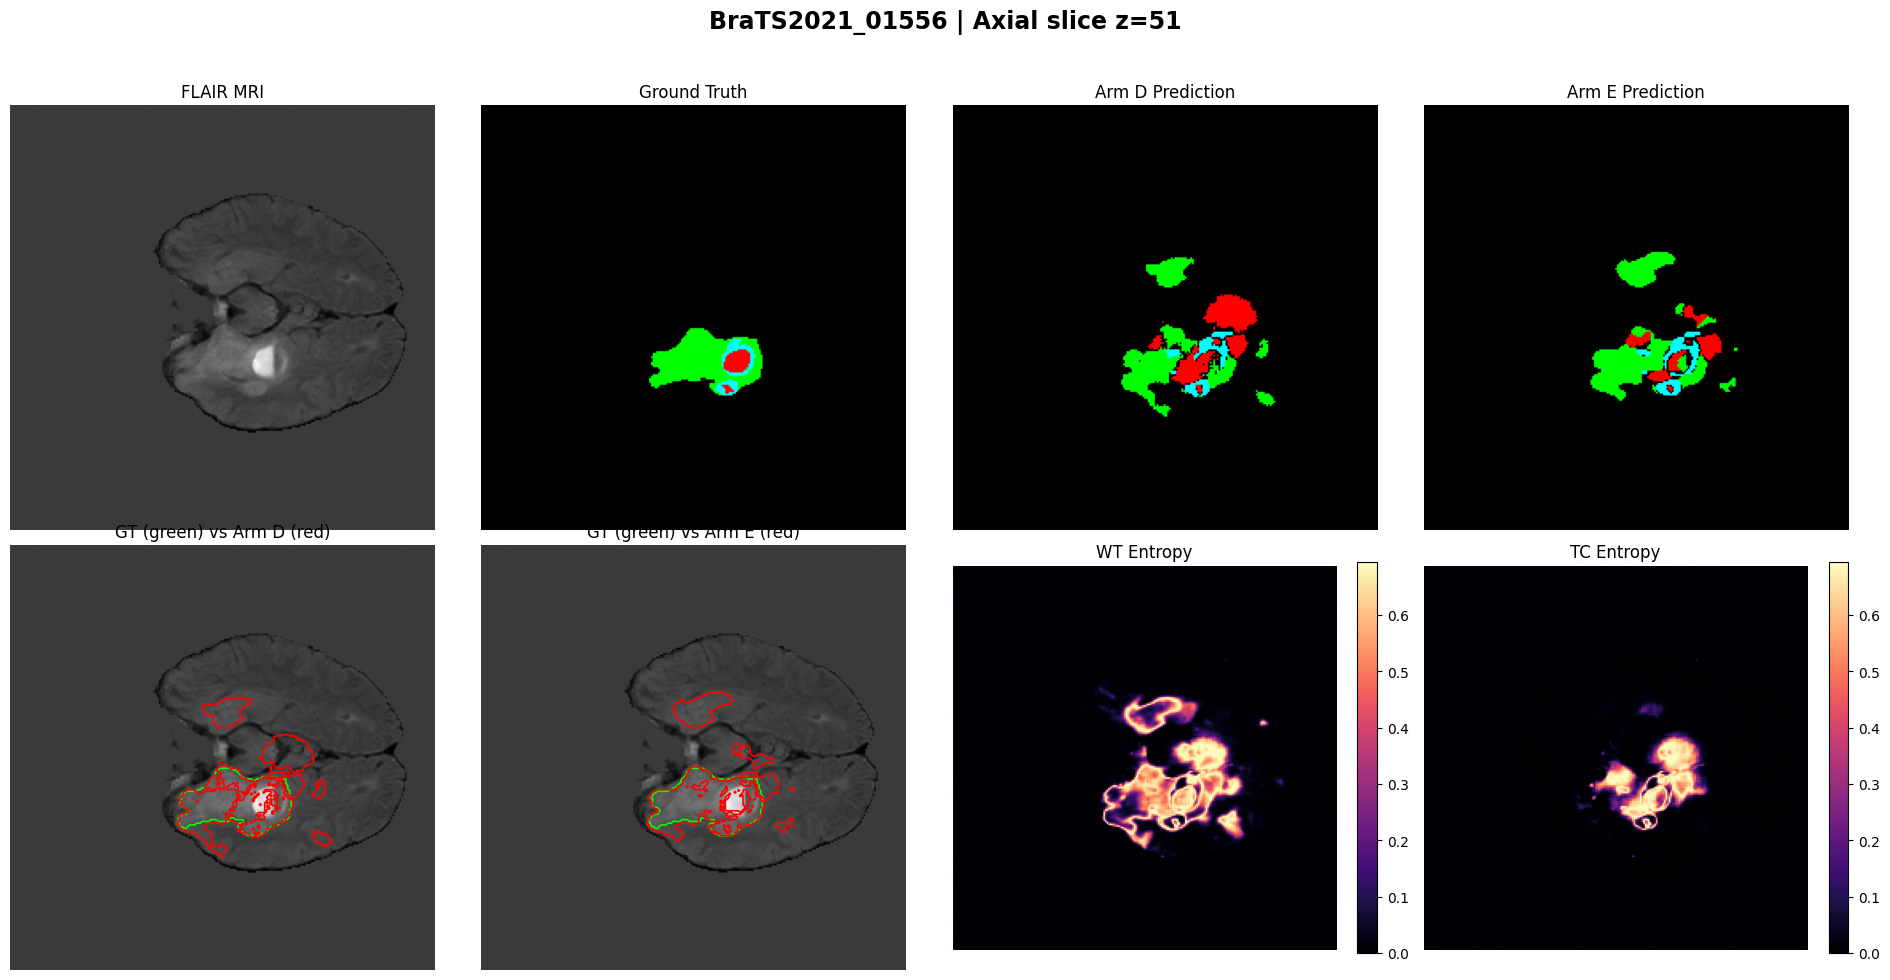

Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/BraTS2021_01556_failure_analysis.png
Processing: BraTS2021_01663


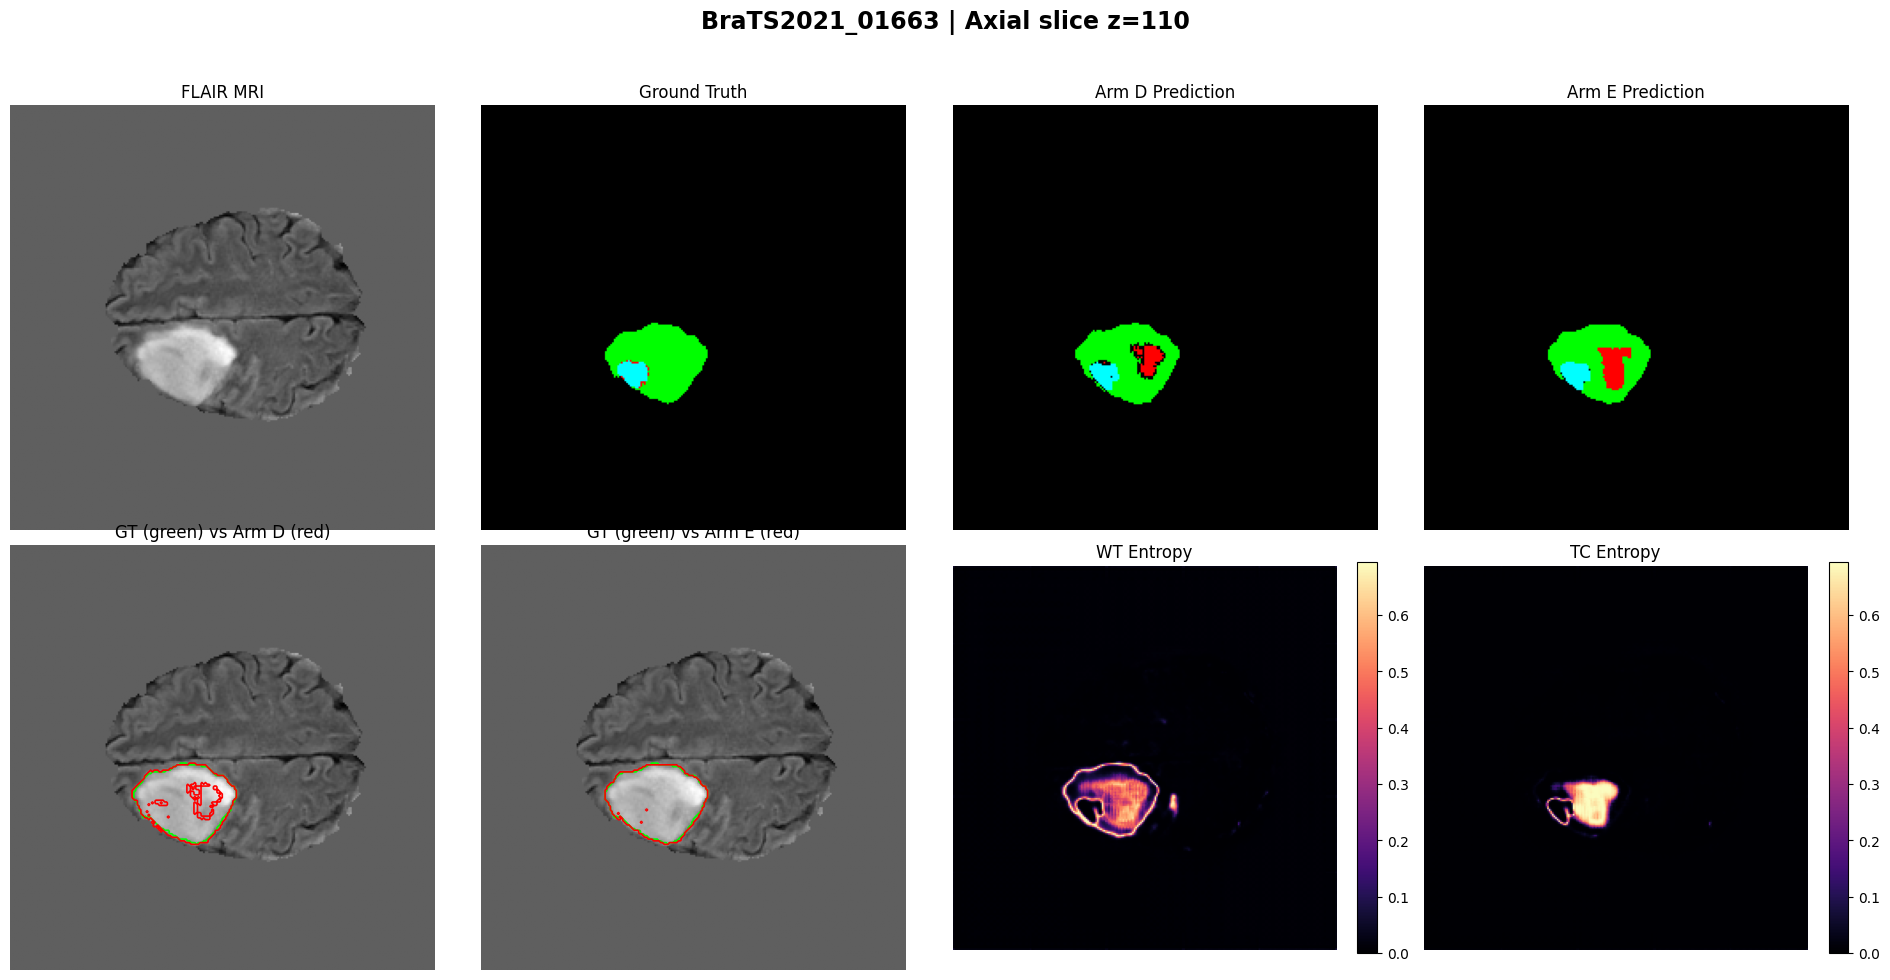

Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/BraTS2021_01663_failure_analysis.png
Processing: BraTS2021_00207


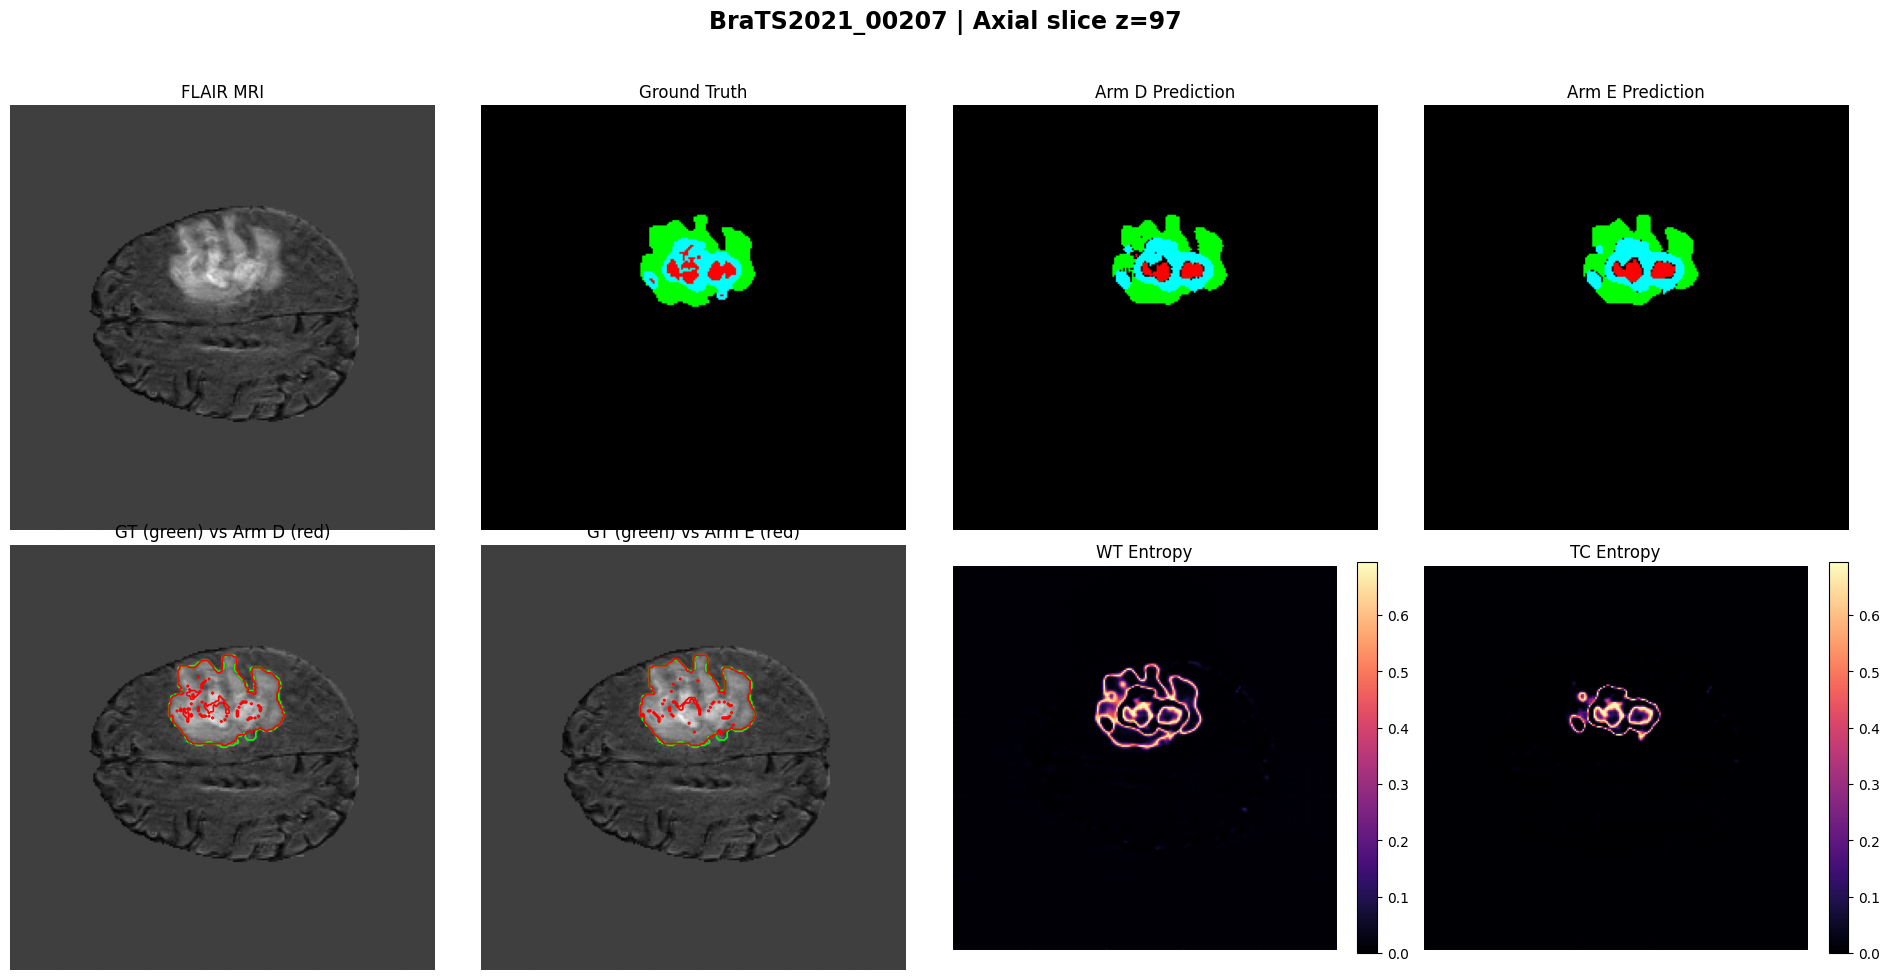

Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/BraTS2021_00207_failure_analysis.png
Processing: BraTS2021_01509


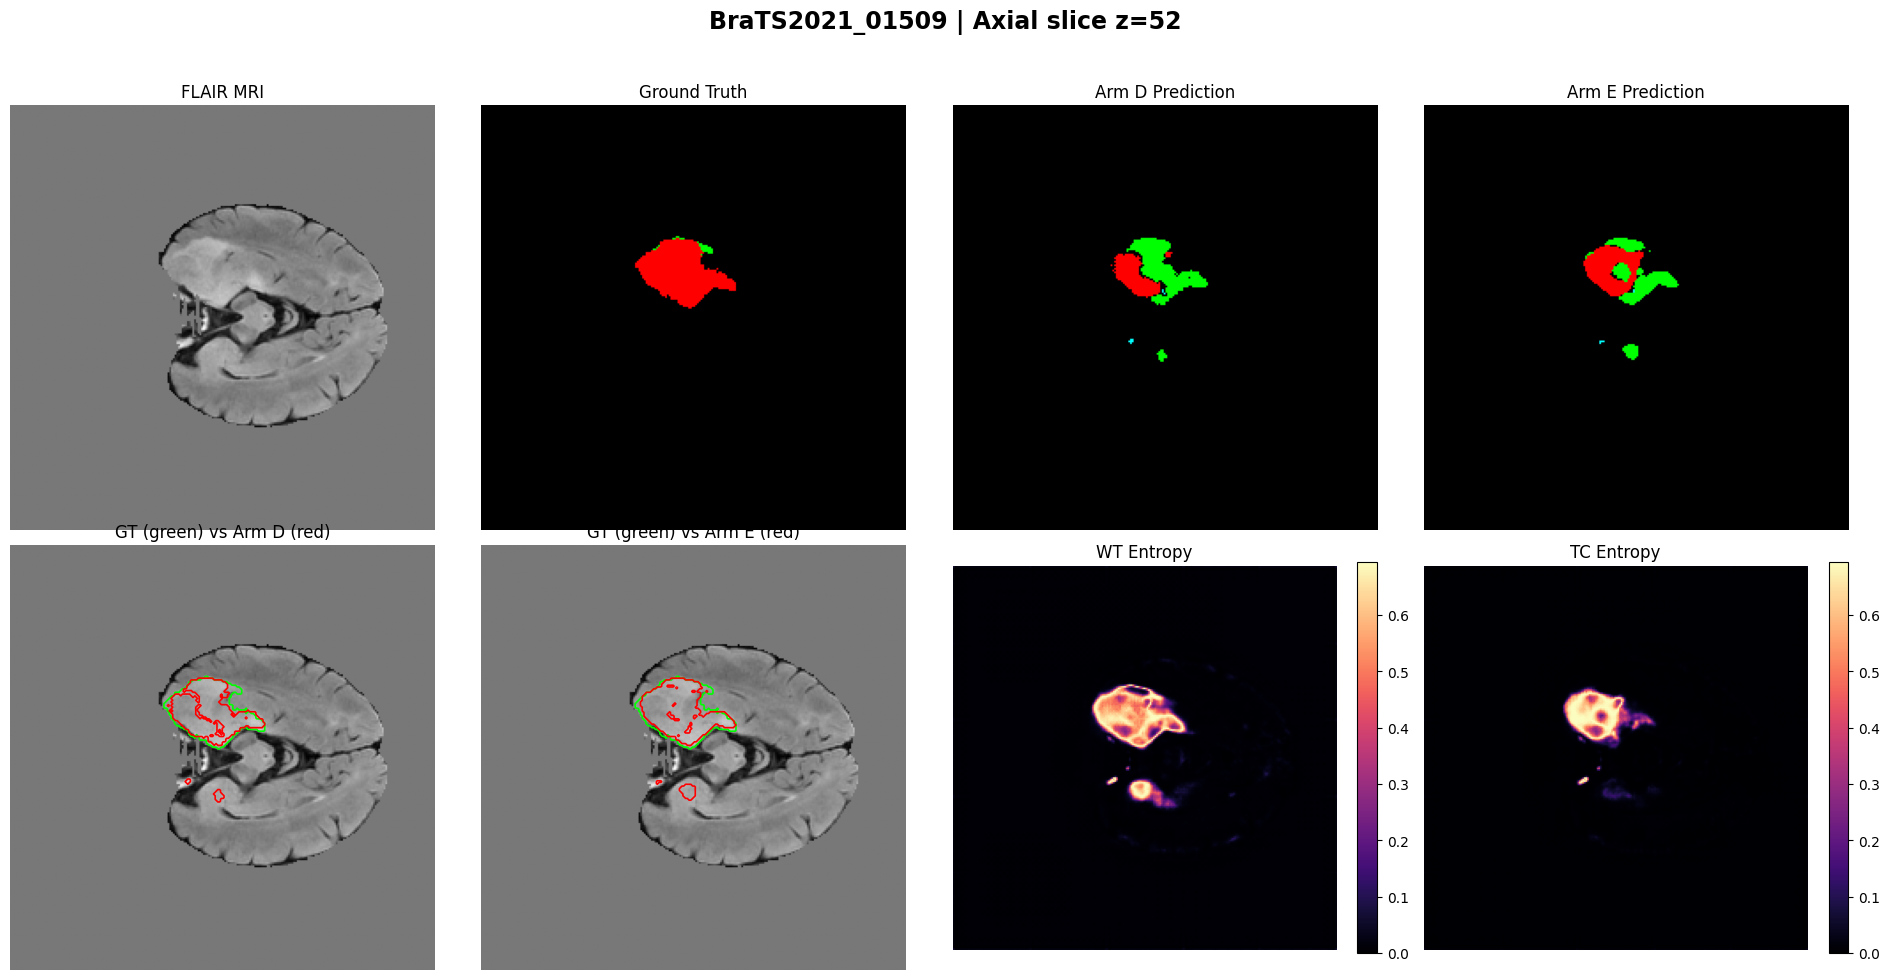

Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/BraTS2021_01509_failure_analysis.png

All failure-analysis figures generated.


In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

OUT = os.path.join(BASE, "results", "failure_analysis")
os.makedirs(OUT, exist_ok=True)

patients = [
    "BraTS2021_01556",
    "BraTS2021_01663",
    "BraTS2021_00207",
    "BraTS2021_01509"
]

# Paths
DATA = os.path.join(BASE, "data/preprocessed")
ARM_D = os.path.join(BASE, "results/test_evaluation/predictions")
ARM_E = os.path.join(BASE, "results/arm_e_test/predictions")
UNC = os.path.join(BASE, "results/arm_e_test/uncertainty_maps")

# Segmentation colours: background, necrotic/core, oedema, enhancing
cmap = ListedColormap([
    "black", "red", "lime", "cyan"
])
norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    cmap.N
)

for patient in patients:

    print("Processing:", patient)

    # Load data
    image = np.load(
        os.path.join(DATA, patient + "_image.npy")
    )

    label = np.load(
        os.path.join(DATA, patient + "_label.npy")
    )

    pred_d = np.load(
        os.path.join(ARM_D, patient + "_prediction.npy")
    )

    pred_e = np.load(
        os.path.join(ARM_E, patient + "_prediction.npy")
    )

    with np.load(
        os.path.join(UNC, patient + "_uncertainty.npz")
    ) as u:
        entropy_wt = u["entropy_wt"].copy()
        entropy_tc = u["entropy_tc"].copy()

    # Select axial slice with largest ground-truth tumour area
    tumour_area = np.sum(label > 0, axis=(0, 1))
    z = int(np.argmax(tumour_area))

    # FLAIR is modality index 3
    flair = image[3, :, :, z]

    gt = label[:, :, z]
    d = pred_d[:, :, z]
    e = pred_e[:, :, z]

    wt_unc = entropy_wt[:, :, z]
    tc_unc = entropy_tc[:, :, z]

    fig, axes = plt.subplots(2, 4, figsize=(19, 10))

    fig.suptitle(
        f"{patient} | Axial slice z={z}",
        fontsize=17,
        fontweight="bold"
    )

    # 1. FLAIR
    axes[0, 0].imshow(flair, cmap="gray")
    axes[0, 0].set_title("FLAIR MRI")

    # 2. Ground truth
    axes[0, 1].imshow(gt, cmap=cmap, norm=norm)
    axes[0, 1].set_title("Ground Truth")

    # 3. Arm D
    axes[0, 2].imshow(d, cmap=cmap, norm=norm)
    axes[0, 2].set_title("Arm D Prediction")

    # 4. Arm E
    axes[0, 3].imshow(e, cmap=cmap, norm=norm)
    axes[0, 3].set_title("Arm E Prediction")

    # 5. Ground truth vs Arm D WT contours
    axes[1, 0].imshow(flair, cmap="gray")
    axes[1, 0].contour(
        gt > 0, levels=[0.5],
        colors="lime", linewidths=1.2
    )
    axes[1, 0].contour(
        d > 0, levels=[0.5],
        colors="red", linewidths=1.2
    )
    axes[1, 0].set_title("GT (green) vs Arm D (red)")

    # 6. Ground truth vs Arm E WT contours
    axes[1, 1].imshow(flair, cmap="gray")
    axes[1, 1].contour(
        gt > 0, levels=[0.5],
        colors="lime", linewidths=1.2
    )
    axes[1, 1].contour(
        e > 0, levels=[0.5],
        colors="red", linewidths=1.2
    )
    axes[1, 1].set_title("GT (green) vs Arm E (red)")

    # 7. WT uncertainty
    im1 = axes[1, 2].imshow(
        wt_unc, cmap="magma", vmin=0, vmax=np.log(2)
    )
    axes[1, 2].set_title("WT Entropy")
    plt.colorbar(im1, ax=axes[1, 2], fraction=0.046)

    # 8. TC uncertainty
    im2 = axes[1, 3].imshow(
        tc_unc, cmap="magma", vmin=0, vmax=np.log(2)
    )
    axes[1, 3].set_title("TC Entropy")
    plt.colorbar(im2, ax=axes[1, 3], fraction=0.046)

    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    save_path = os.path.join(
        OUT, patient + "_failure_analysis.png"
    )

    plt.savefig(
        save_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nAll failure-analysis figures generated.")

In [37]:
import os
import numpy as np
import pandas as pd

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

DATA = os.path.join(BASE, "data/preprocessed")
ARM_D = os.path.join(BASE, "results/test_evaluation/predictions")
ARM_E = os.path.join(BASE, "results/arm_e_test/predictions")

OUT = os.path.join(BASE, "results/failure_analysis")
os.makedirs(OUT, exist_ok=True)

patients = [
    "BraTS2021_01556",
    "BraTS2021_01663",
    "BraTS2021_00207",
    "BraTS2021_01509"
]

def calculate_metrics(gt, pred, mask_gt, mask_pred):
    tp = np.sum(mask_gt & mask_pred)
    fp = np.sum(~mask_gt & mask_pred)
    fn = np.sum(mask_gt & ~mask_pred)

    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan

    gt_count = int(mask_gt.sum())
    pred_count = int(mask_pred.sum())

    volume_ratio = (
        pred_count / gt_count if gt_count > 0 else np.nan
    )

    return {
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
        "GT_voxels": gt_count,
        "Pred_voxels": pred_count,
        "False_Positive_voxels": int(fp),
        "False_Negative_voxels": int(fn),
        "Pred_GT_volume_ratio": volume_ratio
    }

rows = []

for patient in patients:

    gt = np.load(
        os.path.join(DATA, patient + "_label.npy")
    )

    pred_d = np.load(
        os.path.join(ARM_D, patient + "_prediction.npy")
    )

    pred_e = np.load(
        os.path.join(ARM_E, patient + "_prediction.npy")
    )

    for arm_name, pred in [("Arm D", pred_d), ("Arm E", pred_e)]:

        # WT: all tumour classes
        # TC: necrotic + enhancing tumour
        regions = {
            "WT": (gt > 0, pred > 0),
            "TC": (
                np.isin(gt, [1, 3]),
                np.isin(pred, [1, 3])
            ),
            "Necrotic_Core": (gt == 1, pred == 1),
            "Edema": (gt == 2, pred == 2),
            "Enhancing_Tumour": (gt == 3, pred == 3)
        }

        for region, (gt_mask, pred_mask) in regions.items():

            result = calculate_metrics(
                gt, pred, gt_mask, pred_mask
            )

            rows.append({
                "Patient": patient,
                "Arm": arm_name,
                "Region": region,
                **result
            })

results = pd.DataFrame(rows)

# Save complete results
csv_path = os.path.join(
    OUT, "patient_level_failure_metrics.csv"
)
results.to_csv(csv_path, index=False)

# Display WT and TC metrics
print("=" * 75)
print("WHOLE TUMOUR AND TUMOUR CORE METRICS")
print("=" * 75)

display(
    results[
        results["Region"].isin(["WT", "TC"])
    ].round(4)
)

# Display class-specific results
print("\n" + "=" * 75)
print("INDIVIDUAL TUMOUR CLASS METRICS")
print("=" * 75)

display(
    results[
        results["Region"].isin([
            "Necrotic_Core",
            "Edema",
            "Enhancing_Tumour"
        ])
    ].round(4)
)

print("\nSaved:", csv_path)

WHOLE TUMOUR AND TUMOUR CORE METRICS


,Patient,Arm,Region,Dice,Precision,Recall,GT_voxels,Pred_voxels,False_Positive_voxels,False_Negative_voxels,Pred_GT_volume_ratio
0,BraTS2021_01556,Arm D,WT,0.3613,0.2295,0.8490,41800,154627,119139,6312,3.6992
1,BraTS2021_01556,Arm D,TC,0.1376,0.0767,0.6693,6656,58105,53650,2201,8.7297
5,BraTS2021_01556,Arm E,WT,0.3669,0.2314,0.8849,41800,159840,122850,4810,3.8239
6,BraTS2021_01556,Arm E,TC,0.1605,0.0909,0.6869,6656,50318,45746,2084,7.5598
10,BraTS2021_01663,Arm D,WT,0.7966,0.6959,0.9314,56445,75548,22977,3874,1.3384
11,BraTS2021_01663,Arm D,TC,0.2548,0.1568,0.6788,2366,10242,8636,760,4.3288
15,BraTS2021_01663,Arm E,WT,0.8089,0.6895,0.9785,56445,80104,24875,1216,1.4192
16,BraTS2021_01663,Arm E,TC,0.2377,0.1405,0.7718,2366,12996,11170,540,5.4928
20,BraTS2021_00207,Arm D,WT,0.8506,0.9156,0.7942,136827,118687,10022,28162,0.8674
21,BraTS2021_00207,Arm D,TC,0.5867,0.8326,0.4529,47999,26113,4372,26258,0.5440



INDIVIDUAL TUMOUR CLASS METRICS


,Patient,Arm,Region,Dice,Precision,Recall,GT_voxels,Pred_voxels,False_Positive_voxels,False_Negative_voxels,Pred_GT_volume_ratio
2,BraTS2021_01556,Arm D,Necrotic_Core,0.0782,0.0421,0.5448,3229,41748,39989,1470,12.9291
3,BraTS2021_01556,Arm D,Edema,0.3339,0.2278,0.6255,35144,96522,74538,13160,2.7465
4,BraTS2021_01556,Arm D,Enhancing_Tumour,0.2232,0.1350,0.6443,3427,16357,14149,1219,4.7730
7,BraTS2021_01556,Arm E,Necrotic_Core,0.0857,0.0469,0.4998,3229,34437,32823,1615,10.6649
8,BraTS2021_01556,Arm E,Edema,0.3432,0.2266,0.7063,35144,109522,84699,10321,3.1164
9,BraTS2021_01556,Arm E,Enhancing_Tumour,0.2614,0.1589,0.7365,3427,15881,13357,903,4.6341
12,BraTS2021_01663,Arm D,Necrotic_Core,0.0013,0.0007,0.0069,437,4131,4128,434,9.4531
13,BraTS2021_01663,Arm D,Edema,0.7787,0.7118,0.8596,54079,65306,18821,7594,1.2076
14,BraTS2021_01663,Arm D,Enhancing_Tumour,0.3861,0.2540,0.8046,1929,6111,4559,377,3.1680
17,BraTS2021_01663,Arm E,Necrotic_Core,0.0113,0.0060,0.0847,437,6134,6097,400,14.0366



Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/patient_level_failure_metrics.csv


In [38]:
import os
import numpy as np
import pandas as pd

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

DATA = os.path.join(BASE, "data/preprocessed")
ARM_D = os.path.join(BASE, "results/test_evaluation/predictions")
ARM_E = os.path.join(BASE, "results/arm_e_test/predictions")

OUT = os.path.join(BASE, "results/failure_analysis")
os.makedirs(OUT, exist_ok=True)

manifest = pd.read_csv(
    os.path.join(BASE, "manifests/patient_manifest.csv")
)

test_patients = manifest.loc[
    manifest["split"] == "test", "patient_id"
].tolist()

rows = []

classes = {
    "Necrotic_Core": 1,
    "Edema": 2,
    "Enhancing_Tumour": 3
}

for patient in test_patients:

    gt = np.load(
        os.path.join(DATA, patient + "_label.npy")
    )

    for arm, folder in [
        ("Arm D", ARM_D),
        ("Arm E", ARM_E)
    ]:

        pred = np.load(
            os.path.join(folder, patient + "_prediction.npy")
        )

        for class_name, class_id in classes.items():

            gt_mask = gt == class_id
            pred_mask = pred == class_id

            tp = np.logical_and(gt_mask, pred_mask).sum()
            fp = np.logical_and(~gt_mask, pred_mask).sum()
            fn = np.logical_and(gt_mask, ~pred_mask).sum()

            denominator = 2 * tp + fp + fn

            dice = (
                2 * tp / denominator
                if denominator > 0 else np.nan
            )

            rows.append({
                "Patient": patient,
                "Arm": arm,
                "Class": class_name,
                "Dice": dice,
                "GT_voxels": int(gt_mask.sum()),
                "Pred_voxels": int(pred_mask.sum()),
                "FP_voxels": int(fp),
                "FN_voxels": int(fn)
            })

df = pd.DataFrame(rows)

df.to_csv(
    os.path.join(OUT, "all_20_patient_classwise_metrics.csv"),
    index=False
)

summary = df.groupby(
    ["Arm", "Class"]
).agg(
    Mean_Dice=("Dice", "mean"),
    Std_Dice=("Dice", "std"),
    Median_Dice=("Dice", "median"),
    Mean_GT_Voxels=("GT_voxels", "mean"),
    Mean_Pred_Voxels=("Pred_voxels", "mean"),
    Patients_With_Class=("GT_voxels", lambda x: (x > 0).sum())
).reset_index()

summary.to_csv(
    os.path.join(OUT, "all_20_patient_classwise_summary.csv"),
    index=False
)

print("ALL 20 TEST PATIENTS — CLASS-WISE RESULTS")
display(summary.round(4))

print("\nSaved class-wise patient metrics and summary.")

ALL 20 TEST PATIENTS — CLASS-WISE RESULTS


,Arm,Class,Mean_Dice,Std_Dice,Median_Dice,Mean_GT_Voxels,Mean_Pred_Voxels,Patients_With_Class
0,Arm D,Edema,0.7290,0.2342,0.8192,55149.9,60581.65,20
1,Arm D,Enhancing_Tumour,0.7509,0.2532,0.8403,31512.2,30570.90,19
2,Arm D,Necrotic_Core,0.5736,0.3122,0.5352,20355.1,16302.00,20
3,Arm E,Edema,0.7412,0.2306,0.8498,55149.9,61024.80,20
4,Arm E,Enhancing_Tumour,0.7597,0.2508,0.8435,31512.2,30402.65,19
5,Arm E,Necrotic_Core,0.5947,0.3231,0.6107,20355.1,16547.60,20



Saved class-wise patient metrics and summary.


In [39]:
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

BASE = "/kaggle/working/P29_Brain_Tumour_Segmentation"

path = os.path.join(
    BASE,
    "results/failure_analysis/all_20_patient_classwise_metrics.csv"
)

df = pd.read_csv(path)

rng = np.random.default_rng(42)

classes = [
    "Edema",
    "Enhancing_Tumour",
    "Necrotic_Core"
]

rows = []

for cls in classes:

    subset = df[df["Class"] == cls]

    d = subset[subset["Arm"] == "Arm D"][
        ["Patient", "Dice"]
    ].rename(columns={"Dice": "Dice_D"})

    e = subset[subset["Arm"] == "Arm E"][
        ["Patient", "Dice"]
    ].rename(columns={"Dice": "Dice_E"})

    paired = d.merge(e, on="Patient", validate="one_to_one")
    paired = paired.dropna()

    differences = (
        paired["Dice_E"].to_numpy()
        - paired["Dice_D"].to_numpy()
    )

    if np.allclose(differences, 0):
        statistic, p = 0.0, 1.0
    else:
        statistic, p = wilcoxon(
            paired["Dice_E"],
            paired["Dice_D"],
            alternative="two-sided"
        )

    bootstrap = []

    for _ in range(10000):
        indices = rng.integers(
            0, len(differences), len(differences)
        )
        bootstrap.append(np.mean(differences[indices]))

    lower, upper = np.percentile(
        bootstrap, [2.5, 97.5]
    )

    rows.append({
        "Class": cls,
        "Patients": len(paired),
        "Arm_D_Mean": paired["Dice_D"].mean(),
        "Arm_E_Mean": paired["Dice_E"].mean(),
        "Mean_Improvement": differences.mean(),
        "95CI_Lower": lower,
        "95CI_Upper": upper,
        "Wilcoxon_p": p,
        "Patients_Improved": int((differences > 0).sum()),
        "Patients_Worsened": int((differences < 0).sum())
    })

result = pd.DataFrame(rows)

# Holm correction for three related statistical tests
result["Holm_Adjusted_p"] = multipletests(
    result["Wilcoxon_p"],
    method="holm"
)[1]

out = os.path.join(
    BASE,
    "results/failure_analysis/classwise_paired_statistics.csv"
)

result.to_csv(out, index=False)

display(result.round(5))

print("Saved:", out)

,Class,Patients,Arm_D_Mean,Arm_E_Mean,Mean_Improvement,95CI_Lower,95CI_Upper,Wilcoxon_p,Patients_Improved,Patients_Worsened,Holm_Adjusted_p
0,Edema,20,0.72900,0.74122,0.01222,-0.00337,0.02602,0.02395,16,4,0.04790
1,Enhancing_Tumour,20,0.75087,0.75967,0.00880,0.00508,0.01336,0.00021,18,1,0.00064
2,Necrotic_Core,20,0.57359,0.59474,0.02115,0.00111,0.04924,0.11399,14,6,0.11399


Saved: /kaggle/working/P29_Brain_Tumour_Segmentation/results/failure_analysis/classwise_paired_statistics.csv


In [40]:
import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

print("=" * 65)
print("PROJECT RESULTS AND LOGS INSPECTION")
print("=" * 65)

folders_to_check = [
    "logs",
    "results",
    "results/test_evaluation",
    "results/arm_e_test",
    "results/arm_d_vs_arm_e",
    "results/final_comparison",
    "results/failure_analysis",
]

for folder in folders_to_check:
    path = os.path.join(PROJECT_DIR, folder)

    print(f"\n📁 {folder}")

    if not os.path.exists(path):
        print("   Not found")
        continue

    items = sorted(os.listdir(path))

    if not items:
        print("   Empty")
        continue

    for item in items:
        item_path = os.path.join(path, item)

        if os.path.isfile(item_path):
            size_mb = os.path.getsize(item_path) / (1024 * 1024)
            print(f"   📄 {item} ({size_mb:.2f} MB)")
        else:
            print(f"   📂 {item}/")

# Inspect all CSV files in logs and results
print("\n" + "=" * 65)
print("AVAILABLE CSV FILES")
print("=" * 65)

for root, dirs, files in os.walk(os.path.join(PROJECT_DIR, "logs")):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            df = pd.read_csv(path)

            print(f"\n{file}")
            print("Shape:", df.shape)
            print("Columns:", list(df.columns))
            print(df.head(3).to_string(index=False))

for root, dirs, files in os.walk(os.path.join(PROJECT_DIR, "results")):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            df = pd.read_csv(path)

            print(f"\n{os.path.relpath(path, PROJECT_DIR)}")
            print("Shape:", df.shape)
            print("Columns:", list(df.columns))

PROJECT RESULTS AND LOGS INSPECTION

📁 logs
   📄 baseline_training_history.csv (0.00 MB)
   📄 model_b_training_history.csv (0.00 MB)
   📄 original_preprocessing_summary.csv (0.00 MB)
   📄 preprocessing_summary.csv (0.01 MB)

📁 results
   📂 arm_d_vs_arm_e/
   📂 arm_e_test/
   📂 arm_e_validation/
   📂 failure_analysis/
   📂 figures/
   📂 final_comparison/
   📂 predictions/
   📂 test_evaluation/
   📂 validation_comparison/

📁 results/test_evaluation
   📂 predictions/
   📄 test_patient_results.csv (0.00 MB)
   📄 test_summary.csv (0.00 MB)
   📂 uncertainty_maps/

📁 results/arm_e_test
   📄 arm_e_test_patient_results.csv (0.00 MB)
   📄 arm_e_test_summary.csv (0.00 MB)
   📂 predictions/
   📂 probabilities/
   📂 uncertainty_maps/

📁 results/arm_d_vs_arm_e
   📄 arm_d_vs_arm_e_patient_comparison.csv (0.00 MB)
   📄 arm_d_vs_arm_e_statistical_summary.csv (0.00 MB)

📁 results/final_comparison
   📂 arm_a_predictions/
   📄 arm_a_test_patient_results.csv (0.00 MB)
   📄 arm_a_test_summary.csv (0.00 MB)


MAIN TEST RESULTS


,Experiment,Patients,WT_Dice,WT_Dice_Std,TC_Dice,TC_Dice_Std,Mean_Dice,Mean_Dice_Std,Inference_Time_Seconds
0,Model A,20,0.8492,0.1282,0.6445,0.2480,0.7468,0.1714,2.4791
1,Arm D,20,0.8528,0.1321,0.7696,0.2415,0.8112,0.1776,NaN
2,Arm E,20,0.8612,0.1321,0.7876,0.2295,0.8244,0.1713,13.5478


Copied: arm_d_vs_arm_e_statistical_summary.csv
Copied: model_a_vs_arm_e_final_summary.csv
Copied: paired_bootstrap_95CI.csv
Copied: all_20_patient_classwise_summary.csv
Copied: classwise_paired_statistics.csv
Copied: patient_level_failure_metrics.csv
Copied: model_a_vs_arm_e_patient_metrics.csv
Copied: arm_d_vs_arm_e_patient_comparison.csv


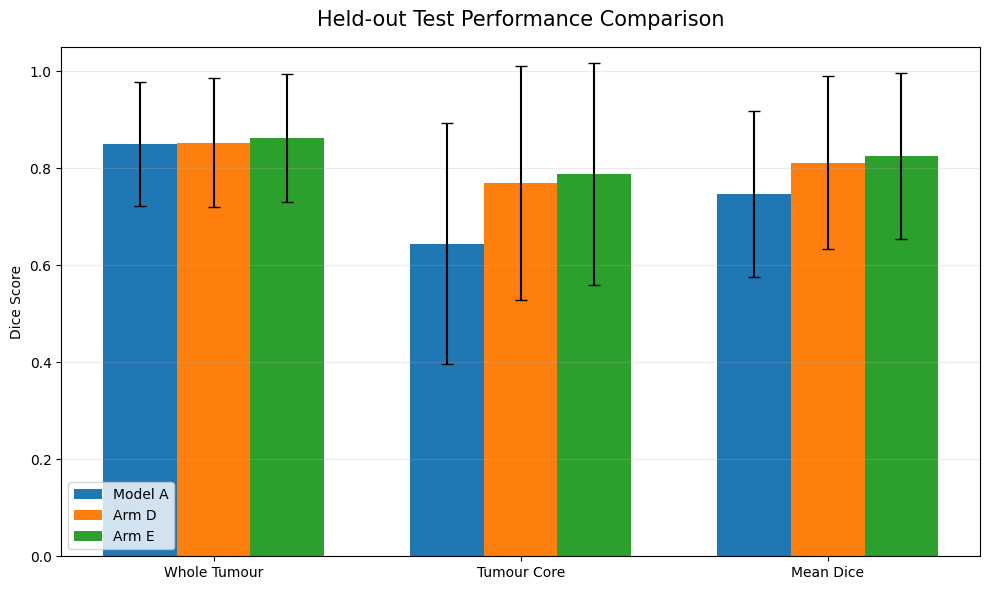

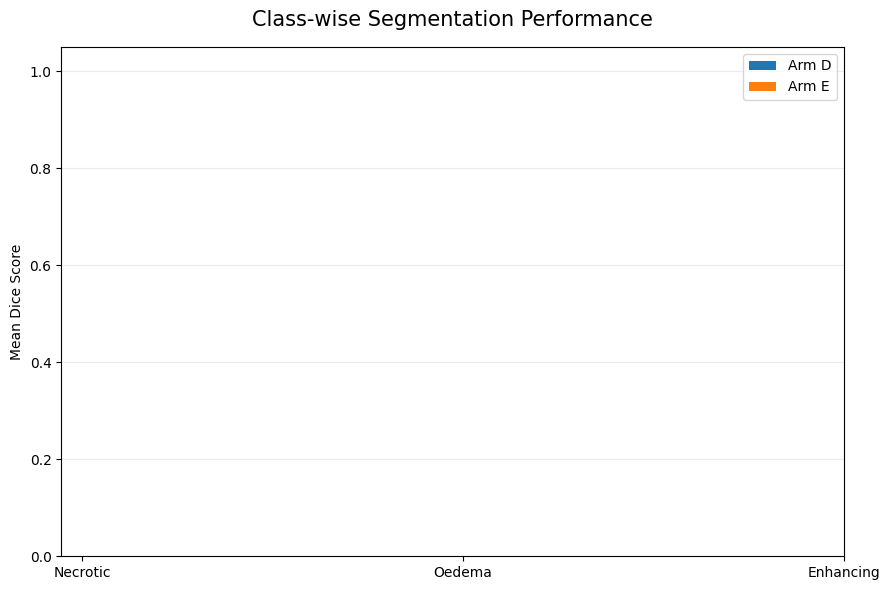

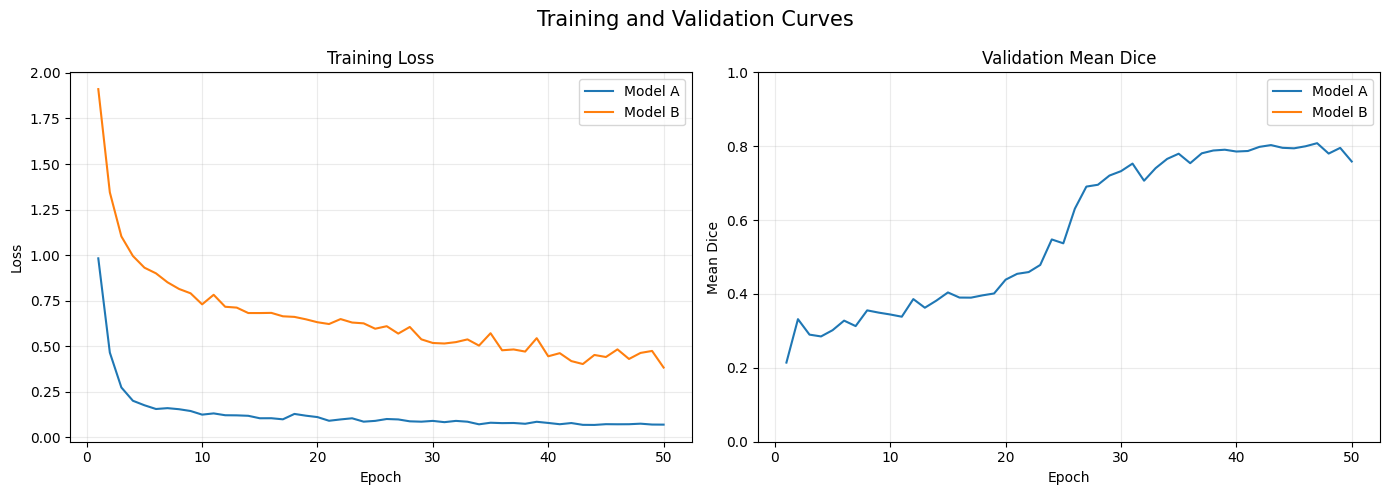


FINAL TABLES
📄 all_20_patient_classwise_summary.csv
📄 arm_d_vs_arm_e_patient_comparison.csv
📄 arm_d_vs_arm_e_statistical_summary.csv
📄 classwise_paired_statistics.csv
📄 main_test_results.csv
📄 model_a_vs_arm_e_final_summary.csv
📄 model_a_vs_arm_e_patient_metrics.csv
📄 paired_bootstrap_95CI.csv
📄 patient_level_failure_metrics.csv

GENERATED FIGURES
📊 classwise_dice_comparison.png — 0.08 MB
📊 main_test_dice_comparison.png — 0.09 MB
📊 training_curves.png — 0.21 MB

Consolidation and figure generation completed.


In [41]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
LOGS_DIR = os.path.join(PROJECT_DIR, "logs")

FINAL_TABLES = os.path.join(RESULTS_DIR, "final_tables")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(FINAL_TABLES, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# --------------------------------------------------
# 1. LOAD EXPERIMENT SUMMARIES
# --------------------------------------------------

summary_files = {
    "Model A": "final_comparison/arm_a_test_summary.csv",
    "Arm D": "test_evaluation/test_summary.csv",
    "Arm E": "arm_e_test/arm_e_test_summary.csv"
}

main_rows = []

for model_name, relative_path in summary_files.items():

    path = os.path.join(RESULTS_DIR, relative_path)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing summary: {path}")

    df = pd.read_csv(path)
    row = df.iloc[0]

    main_rows.append({
        "Experiment": model_name,
        "Patients": int(row["Number_of_patients"]),
        "WT_Dice": row["WT_Dice"],
        "WT_Dice_Std": row["WT_Dice_Std"],
        "TC_Dice": row["TC_Dice"],
        "TC_Dice_Std": row["TC_Dice_Std"],
        "Mean_Dice": row["Mean_Dice"],
        "Mean_Dice_Std": row["Mean_Dice_Std"],
        "Inference_Time_Seconds": row.get(
            "Mean_inference_time_seconds", np.nan
        )
    })

main_table = pd.DataFrame(main_rows)

main_table.to_csv(
    os.path.join(FINAL_TABLES, "main_test_results.csv"),
    index=False
)

print("MAIN TEST RESULTS")
display(main_table.round(4))


# --------------------------------------------------
# 2. COPY IMPORTANT STATISTICAL TABLES
# --------------------------------------------------

tables_to_copy = [
    "arm_d_vs_arm_e/arm_d_vs_arm_e_statistical_summary.csv",
    "final_comparison/model_a_vs_arm_e_final_summary.csv",
    "final_comparison/paired_bootstrap_95CI.csv",
    "failure_analysis/all_20_patient_classwise_summary.csv",
    "failure_analysis/classwise_paired_statistics.csv",
    "failure_analysis/patient_level_failure_metrics.csv",
    "final_comparison/model_a_vs_arm_e_patient_metrics.csv",
    "arm_d_vs_arm_e/arm_d_vs_arm_e_patient_comparison.csv"
]

for relative_path in tables_to_copy:

    source = os.path.join(RESULTS_DIR, relative_path)

    if os.path.exists(source):

        destination_name = os.path.basename(relative_path)

        shutil.copy2(
            source,
            os.path.join(FINAL_TABLES, destination_name)
        )

        print("Copied:", destination_name)

    else:
        print("WARNING: Missing:", relative_path)


# --------------------------------------------------
# 3. FIGURE 1 — MAIN TEST DICE COMPARISON
# --------------------------------------------------

metrics = ["WT_Dice", "TC_Dice", "Mean_Dice"]
metric_labels = ["Whole Tumour", "Tumour Core", "Mean Dice"]

x = np.arange(len(metrics))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 6))

for i, (_, row) in enumerate(main_table.iterrows()):

    values = [row[m] for m in metrics]
    errors = [row[m + "_Std"] for m in metrics]

    positions = x + (i - 1) * width

    ax.bar(
        positions,
        values,
        width,
        yerr=errors,
        capsize=4,
        label=row["Experiment"]
    )

ax.set_title(
    "Held-out Test Performance Comparison",
    fontsize=15,
    pad=15
)

ax.set_ylabel("Dice Score")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(FIGURES_DIR, "main_test_dice_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 4. FIGURE 2 — CLASS-WISE DICE COMPARISON
# --------------------------------------------------

classwise_path = os.path.join(
    RESULTS_DIR,
    "failure_analysis/all_20_patient_classwise_summary.csv"
)

classwise = pd.read_csv(classwise_path)

class_order = [
    "Necrotic",
    "Oedema",
    "Enhancing"
]

# Match class labels from the source CSV
classwise["Class"] = classwise["Class"].replace({
    "Necrotic_Core": "Necrotic",
    "Enhancing_Tumour": "Enhancing",
    "Edema": "Oedema"
})

classwise = classwise[classwise["Class"].isin(class_order)]

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(class_order))
width = 0.34

for i, arm in enumerate(["D", "E"]):

    subset = (
        classwise[classwise["Arm"] == arm]
        .set_index("Class")
        .reindex(class_order)
    )

    ax.bar(
        x + (i - 0.5) * width,
        subset["Mean_Dice"].values,
        width,
        yerr=subset["Std_Dice"].values,
        capsize=4,
        label=f"Arm {arm}"
    )

ax.set_title(
    "Class-wise Segmentation Performance",
    fontsize=15,
    pad=15
)

ax.set_ylabel("Mean Dice Score")
ax.set_xticks(x)
ax.set_xticklabels(class_order)
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(FIGURES_DIR, "classwise_dice_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 5. FIGURE 3 — TRAINING CURVES
# --------------------------------------------------

baseline_history = pd.read_csv(
    os.path.join(LOGS_DIR, "baseline_training_history.csv")
)

model_b_history = pd.read_csv(
    os.path.join(LOGS_DIR, "model_b_training_history.csv")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training loss
axes[0].plot(
    baseline_history["epoch"],
    baseline_history["train_loss"],
    label="Model A"
)

axes[0].plot(
    model_b_history["epoch"],
    model_b_history["train_loss"],
    label="Model B"
)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Validation mean Dice
axes[1].plot(
    baseline_history["epoch"],
    baseline_history["val_mean_Dice"],
    label="Model A"
)

axes[1].plot(
    model_b_history["epoch"],
    model_b_history["val_mean_Dice"],
    label="Model B"
)

axes[1].set_title("Validation Mean Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Dice")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.suptitle(
    "Training and Validation Curves",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    os.path.join(FIGURES_DIR, "training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 6. FINAL OUTPUT CHECK
# --------------------------------------------------

print("\n" + "=" * 65)
print("FINAL TABLES")
print("=" * 65)

for file in sorted(os.listdir(FINAL_TABLES)):
    print("📄", file)

print("\n" + "=" * 65)
print("GENERATED FIGURES")
print("=" * 65)

for file in sorted(os.listdir(FIGURES_DIR)):
    if file.endswith(".png"):
        path = os.path.join(FIGURES_DIR, file)
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"📊 {file} — {size:.2f} MB")

print("\nConsolidation and figure generation completed.")

In [42]:
import os
from PIL import Image
import pandas as pd

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

FIGURES_DIR = os.path.join(PROJECT_DIR, "results", "figures")
TABLES_DIR = os.path.join(PROJECT_DIR, "results", "final_tables")

expected_figures = [
    "main_test_dice_comparison.png",
    "classwise_dice_comparison.png",
    "training_curves.png"
]

print("=" * 60)
print("FIGURE VERIFICATION")
print("=" * 60)

for filename in expected_figures:

    path = os.path.join(FIGURES_DIR, filename)

    if os.path.exists(path):
        img = Image.open(path)

        print(f"\n✓ {filename}")
        print("  Dimensions:", img.size)
        print("  File size:", round(os.path.getsize(path) / 1024, 2), "KB")

    else:
        print(f"\n✗ MISSING: {filename}")


print("\n" + "=" * 60)
print("FINAL TABLE VERIFICATION")
print("=" * 60)

for filename in sorted(os.listdir(TABLES_DIR)):

    if filename.endswith(".csv"):

        path = os.path.join(TABLES_DIR, filename)
        df = pd.read_csv(path)

        print(f"✓ {filename} | Rows: {len(df)} | Columns: {len(df.columns)}")


print("\n" + "=" * 60)
print("VERIFICATION COMPLETE")
print("=" * 60)

FIGURE VERIFICATION

✓ main_test_dice_comparison.png
  Dimensions: (2970, 1769)
  File size: 94.24 KB

✓ classwise_dice_comparison.png
  Dimensions: (2670, 1769)
  File size: 84.89 KB

✓ training_curves.png
  Dimensions: (4170, 1485)
  File size: 218.48 KB

FINAL TABLE VERIFICATION
✓ all_20_patient_classwise_summary.csv | Rows: 6 | Columns: 8
✓ arm_d_vs_arm_e_patient_comparison.csv | Rows: 20 | Columns: 11
✓ arm_d_vs_arm_e_statistical_summary.csv | Rows: 3 | Columns: 12
✓ classwise_paired_statistics.csv | Rows: 3 | Columns: 11
✓ main_test_results.csv | Rows: 3 | Columns: 9
✓ model_a_vs_arm_e_final_summary.csv | Rows: 5 | Columns: 7
✓ model_a_vs_arm_e_patient_metrics.csv | Rows: 20 | Columns: 15
✓ paired_bootstrap_95CI.csv | Rows: 5 | Columns: 5
✓ patient_level_failure_metrics.csv | Rows: 40 | Columns: 11

VERIFICATION COMPLETE


In [43]:
import os

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

print("=" * 70)
print("PROJECT STRUCTURE AUDIT")
print("=" * 70)

# 1. Inspect project files, excluding large data/output folders
excluded = {
    "data",
    "predictions",
    "uncertainty_maps",
    "probabilities",
    "arm_a_predictions",
}

for root, dirs, files in os.walk(PROJECT_DIR):

    dirs[:] = sorted(d for d in dirs if d not in excluded)

    relative = os.path.relpath(root, PROJECT_DIR)

    if relative == ".":
        print("\n📁 PROJECT ROOT")
    else:
        print(f"\n📁 {relative}/")

    for file in sorted(files):
        path = os.path.join(root, file)
        size_kb = os.path.getsize(path) / 1024

        print(f"   {file} ({size_kb:.1f} KB)")


# 2. Check important reproducibility files
required_files = {
    "README.md": os.path.join(PROJECT_DIR, "README.md"),
    "requirements.txt": os.path.join(PROJECT_DIR, "requirements.txt"),
    "run_all.sh": os.path.join(PROJECT_DIR, "run_all.sh"),
    "Preprocessing scripts": os.path.join(PROJECT_DIR, "scripts"),
    "Training scripts": os.path.join(PROJECT_DIR, "scripts"),
    "Configuration files": os.path.join(PROJECT_DIR, "configs"),
}

print("\n" + "=" * 70)
print("REPRODUCIBILITY FILE CHECK")
print("=" * 70)

for name, path in required_files.items():
    exists = os.path.exists(path)

    if exists:
        print(f"✓ {name}: PRESENT")
    else:
        print(f"✗ {name}: NOT FOUND")


# 3. Locate Python and shell scripts
print("\n" + "=" * 70)
print("AVAILABLE PYTHON AND SHELL SCRIPTS")
print("=" * 70)

for root, dirs, files in os.walk(PROJECT_DIR):

    dirs[:] = sorted(d for d in dirs if d not in excluded)

    for file in sorted(files):
        if file.endswith((".py", ".sh")):
            print(os.path.relpath(os.path.join(root, file), PROJECT_DIR))


# 4. Check available notebooks in Kaggle working directory
print("\n" + "=" * 70)
print("NOTEBOOK FILES")
print("=" * 70)

for root, dirs, files in os.walk("/kaggle/working"):

    dirs[:] = sorted(
        d for d in dirs
        if d not in {"data", ".cache"}
    )

    for file in sorted(files):
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))


print("\n" + "=" * 70)
print("AUDIT COMPLETE")
print("=" * 70)

PROJECT STRUCTURE AUDIT

📁 PROJECT ROOT

📁 checkpoints/

📁 checkpoints/model_a/
   baseline_best.pth (7156.9 KB)
   baseline_latest.pth (7157.5 KB)

📁 checkpoints/model_b/
   model_b_best.pth (7118.7 KB)
   model_b_latest.pth (7118.9 KB)

📁 configs/

📁 logs/
   baseline_training_history.csv (3.4 KB)
   model_b_training_history.csv (3.9 KB)
   original_preprocessing_summary.csv (4.1 KB)
   preprocessing_summary.csv (14.9 KB)

📁 manifests/
   archive_index.csv (295.7 KB)
   original_patient_manifest.csv (35.9 KB)
   patient_manifest.csv (42.5 KB)

📁 results/

📁 results/arm_d_vs_arm_e/
   arm_d_vs_arm_e_patient_comparison.csv (4.3 KB)
   arm_d_vs_arm_e_statistical_summary.csv (0.7 KB)

📁 results/arm_e_test/
   arm_e_test_patient_results.csv (2.7 KB)
   arm_e_test_summary.csv (0.3 KB)

📁 results/arm_e_validation/
   arm_e_validation_patient_results.csv (1.1 KB)
   arm_e_validation_summary.csv (0.3 KB)

📁 results/failure_analysis/
   BraTS2021_00207_failure_analysis.png (327.9 KB)
   BraTS2

In [44]:
import json
import os

NOTEBOOK_PATH = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

if not os.path.exists(NOTEBOOK_PATH):
    raise FileNotFoundError("Notebook source not found!")

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

print("=" * 75)
print("ORIGINAL NOTEBOOK INSPECTION")
print("=" * 75)

print("Total cells:", len(cells))
print("Code cells:", sum(c["cell_type"] == "code" for c in cells))
print("Markdown cells:", sum(c["cell_type"] == "markdown" for c in cells))

print("\n" + "=" * 75)
print("NOTEBOOK CELL INDEX")
print("=" * 75)

for i, cell in enumerate(cells):

    source = "".join(cell.get("source", []))
    lines = source.strip().splitlines()

    if not lines:
        continue

    if cell["cell_type"] == "markdown":
        heading = next(
            (line.strip("# ").strip() for line in lines
             if line.strip().startswith("#")),
            lines[0][:100]
        )
        print(f"\n[{i}] MARKDOWN: {heading}")

    else:
        first_lines = " | ".join(
            line.strip() for line in lines[:3]
        )

        print(
            f"\n[{i}] CODE "
            f"({len(lines)} lines): {first_lines[:180]}"
        )

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("=" * 75)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [45]:
import os

NOTEBOOK_PATH = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

print("File exists:", os.path.exists(NOTEBOOK_PATH))

if os.path.exists(NOTEBOOK_PATH):

    size = os.path.getsize(NOTEBOOK_PATH)

    print("File size:", size, "bytes")

    with open(NOTEBOOK_PATH, "rb") as f:
        content = f.read(500)

    print("\nFirst 500 bytes:")
    print(repr(content))

print("\n" + "=" * 60)
print("SEARCHING FOR NOTEBOOK FILES")
print("=" * 60)

for base in ["/kaggle/working", "/kaggle/input"]:

    for root, dirs, files in os.walk(base):

        dirs[:] = [
            d for d in dirs
            if d not in {"data", ".cache"}
        ]

        for file in files:
            if file.endswith(".ipynb"):
                path = os.path.join(root, file)
                print(path, "|", os.path.getsize(path), "bytes")

File exists: True
File size: 129022 bytes

First 500 bytes:
b'# This Python 3 environment comes with many helpful analytics libraries installed\n# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python\n# For example, here\'s several helpful packages to load\n\nimport numpy as np # linear algebra\nimport pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)\n\n# Input data files are available in the read-only "../input/" directory\n# For example, running this (by clicking run or pressing Shift+Enter) will list all files u'

SEARCHING FOR NOTEBOOK FILES
/kaggle/working/.virtual_documents/__notebook_source__.ipynb | 129022 bytes


In [47]:
import os
import re

SOURCE_PATH = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(SOURCE_PATH, "r", encoding="utf-8") as f:
    source = f.read()

lines = source.splitlines()

print("=" * 75)
print("SOURCE FILE INFORMATION")
print("=" * 75)

print("Total lines:", len(lines))
print("Total characters:", len(source))

# Identify section headings and cell markers
print("\n" + "=" * 75)
print("SECTION HEADINGS AND CELL MARKERS")
print("=" * 75)

for i, line in enumerate(lines):

    stripped = line.strip()

    if (
        stripped.startswith("# In[")
        or stripped.startswith("# %%")
        or (
            stripped.startswith("#")
            and len(stripped) > 3
            and not stripped.startswith("#!")
        )
    ):
        print(f"Line {i+1}: {stripped[:150]}")

# Identify important implementation components
keywords = [
    "def ",
    "class ",
    "UNet(",
    "DiceCELoss",
    "CrossEntropyLoss",
    "SlidingWindowInferer",
    "RandCropByPosNegLabel",
    "torch.save",
    "torch.load",
    "optimizer",
    "DataLoader",
    "validation",
    "preprocess",
    "inference",
    "seed"
]

print("\n" + "=" * 75)
print("IMPORTANT IMPLEMENTATION REFERENCES")
print("=" * 75)

for keyword in keywords:

    matches = [
        (i+1, line.strip())
        for i, line in enumerate(lines)
        if keyword.lower() in line.lower()
    ]

    if matches:
        print(f"\n{keyword}:")
        for line_number, content in matches[:8]:
            print(f"  Line {line_number}: {content[:150]}")

print("\n" + "=" * 75)
print("SOURCE INSPECTION COMPLETE")
print("=" * 75)

SOURCE FILE INFORMATION
Total lines: 5155
Total characters: 128996

SECTION HEADINGS AND CELL MARKERS
Line 1: # This Python 3 environment comes with many helpful analytics libraries installed
Line 2: # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
Line 3: # For example, here's several helpful packages to load
Line 8: # Input data files are available in the read-only "../input/" directory
Line 9: # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
Line 16: # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
Line 17: # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session
Line 19: # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
Line 20: # Learn more about kagglehub

In [48]:
import os
import shutil
from IPython.display import FileLink, display

PROJECT_DIR = "/kaggle/working/P29_Brain_Tumour_Segmentation"

SOURCE_PATH = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebooks")
os.makedirs(NOTEBOOK_DIR, exist_ok=True)

OUTPUT_PATH = os.path.join(
    NOTEBOOK_DIR,
    "original_kaggle_source.py"
)

# Preserve the original source
shutil.copy2(SOURCE_PATH, OUTPUT_PATH)

print("Source prepared successfully.")
print("File size:", round(os.path.getsize(OUTPUT_PATH) / 1024, 2), "KB")

# Download link
display(FileLink(OUTPUT_PATH))

Source prepared successfully.
File size: 157.88 KB


/kaggle/working/P29_Brain_Tumour_Segmentation/notebooks/original_kaggle_source.py